In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
import math

Read 3 csv from documents

In [3]:
property = pd.read_csv("/content/drive/MyDrive/Data/properties_2022.csv")
sales = pd.read_csv("/content/drive/MyDrive/Data/sales.csv")
var_dict = pd.read_csv("/content/drive/MyDrive/Data/variable_dictionary.csv")

/tmp/ipykernel_30901/1186188372.py:1: DtypeWarning: Columns (37) have mixed types. Specify dtype option on import or set low_memory=False.
  property = pd.read_csv("/content/drive/MyDrive/Data/properties_2022.csv")


Check the circumstance of missing value in property and
sales csv. Check whether the missing value fraction in
property csv approximately equals to that in dictionary

初步检查两份文件的数据，包括日期的合理性、price的合理性、缺失值情况


In [4]:
print (property.info())
print ("\nThe shape of property dataset is: {}\n".format(property.shape))

act_missing = property.drop(columns='property_id').isnull().mean()

var_dict["actual_missing_fraction"] = var_dict["variable"].map(act_missing)
difference = (var_dict["actual_missing_fraction"] - var_dict["missing_fraction"])
great_diff = difference[difference>1e-6]

unmatched = act_missing.index[~act_missing.index.isin(var_dict["variable"])]

if great_diff.empty and unmatched.empty:
  print ("All null fraction in property csv can match with that in dictionary\n and features are all included in dictionary")
else:
  print (great_diff)
  print (unmatched)

value_null = property.isnull().sum().sort_values(ascending=False)
cols_with_missing = property.isnull().any(axis=0).sum()
print ("\nNumber of columns with missing values in property csv: ",cols_with_missing)
print ("\nSum of missing value:\n", value_null[value_null!=0])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98899 entries, 0 to 98898
Data columns (total 98 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   property_id                                            98899 non-null  int64  
 1   loc_property_city                                      98897 non-null  object 
 2   loc_property_zip                                       98517 non-null  float64
 3   loc_longitude                                          98899 non-null  float64
 4   loc_latitude                                           98899 non-null  float64
 5   char_yrblt                                             98898 non-null  float64
 6   char_bldg_sf                                           98899 non-null  float64
 7   char_land_sf                                           98899 non-null  float64
 8   char_beds                                     

上述property csv中，所有feature均已被dictionary涵盖，且missing fraction与dictionary基本一致。
总计样本数98899，总feature数量为97+1（1为property_id），含缺失值的feature总共有39个

In [5]:
print (sales.info())
print ("\nThe shape of property dataset is: {}\n".format(sales.shape))
value_null2 = sales.isnull().sum().sort_values(ascending=False)

if value_null2.empty:
  print ("No missing value in sales csv")
else:
  print (value_null2[value_null2!=0])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109307 entries, 0 to 109306
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   property_id     109307 non-null  int64  
 1   transaction_id  109307 non-null  int64  
 2   sale_date       109307 non-null  object 
 3   sale_price      109307 non-null  float64
dtypes: float64(1), int64(2), object(1)
memory usage: 3.3+ MB
None

The shape of property dataset is: (109307, 4)

Series([], dtype: int64)


上述Sales csv中总计109307个样本，feature数量为3+1（包含1个property_id）。没有missing value

According to the above, there are a large amount of missing
value in property csv, and their fraction can match to
that in dictionary. No missing value exist in sales csv.


---


Confirm whether there are records out of required time

In [6]:
sales['sale_date'] = pd.to_datetime(sales['sale_date'])

# Confirm whether there are records out of required time
outoftime = sales[(sales['sale_date'] >= '2026-01-01')|(sales['sale_date'] <= '2022-12-31')]

if outoftime.empty:
  print ('All records in sale csv fall within 2023 and 2025\n')
else:
  print ('There are sale records out of specified time:\n{}'.format(outoftime))

print("char_yrblt range:", property["char_yrblt"].min(),property["char_yrblt"].max())
print("Later than 2022 char_built:",(property["char_yrblt"]>2022).sum())
print("Null or negative record:",(property["char_yrblt"] <= 0).sum())
print("Too early (<1800) :", (property["char_yrblt"]< 1800).sum())

print("\nRange of year Median Occupied Household:",property["acs5_median_household_total_occupied_year_built"].min(),
      property["acs5_median_household_total_occupied_year_built"].max())
print("Later than 2022 Median Occupied Household:",
 (property["acs5_median_household_total_occupied_year_built"] > 2022).sum())

illegal_price = sales[sales['sale_price']<=0]

if illegal_price.empty:
  print ('\nAll records in sale csv have proper price\n')
else:
  print ('There are sale records within illegal price:\n{}'.format(illegal_price))


All records in sale csv fall within 2023 and 2025

char_yrblt range: 1847.0 2021.0
Later than 2022 char_built: 0
Null or negative record: 0
Too early (<1800) : 0

Range of year Median Occupied Household: 1940.0 2007.0
Later than 2022 Median Occupied Household: 0

All records in sale csv have proper price



All records in sales csv and property csv are correctly
recorded.

上述时间检查中，sales和property中的records的时间，均被记录在正确范围内。
对于sales csv中的价格数据，均在0值以上，没有非法数据记录。

---


We then test whether duplicate records and repeated
sales of the same property exist or not.

:

In [7]:
duplicate_trans_id = sales['transaction_id'].value_counts()
duplicate_list = duplicate_trans_id[duplicate_trans_id>1]
if duplicate_list.empty:
  print ('No duplicated transaction id exist.')
else:
  print ('There are duplicated transaction id existing:\n{}'.format(duplicate_list))

print ("Number of unique transaction id in sales csv: ",sales['transaction_id'].nunique())
print ("Number of unique property id in sales csv: ",sales['property_id'].nunique())
print ("Number of unique property id in property csv: ",property['property_id'].nunique())

print ("Sales shape: ",sales.shape)
print ("Property shape: ",property.shape)


No duplicated transaction id exist.
Number of unique transaction id in sales csv:  109307
Number of unique property id in sales csv:  98899
Number of unique property id in property csv:  98899
Sales shape:  (109307, 4)
Property shape:  (98899, 98)


From the above, we can find that in the property csv,
all of the property id is unique. However, in the sales
csv, the number of property id does not equal to the
row number, which means that there are duplicated property id
existing. Transaction id is unique. This means that one
property id may match mulitple transaction id, which is
compliant.

上述检查中，sales csv中的transaction id的独立值数量总计109307，与行数一致，故transaction是完全相互独立，不存在重复销售的情况。

property csv中的property id的独立值总计98899，和csv的行数一致，不存在重复的property信息被记录的情况。

而sales csv中的property id的独立值数量总计为98899，小于109307，故存在同一property有着多笔交易的出现，这符合实际情况和预期。而其独立值数量与property csv的数量一致，初步判断两边property id的独立值在数量和value上是相等的，还需进一步判断


---


Set the first column 'property_id' as index

In [8]:
property = property.set_index ('property_id')
print (property.head())
sales = sales.set_index ('property_id')
print (sales.head())

              loc_property_city  loc_property_zip  loc_longitude  \
property_id                                                        
1011000170000        BARRINGTON           60010.0     -88.140521   
1011000190000        BARRINGTON           60010.0     -88.140083   
1011000250000        BARRINGTON           60010.0     -88.138667   
1011000430000        BARRINGTON           60010.0     -88.138708   
1011000460000        BARRINGTON           60010.0     -88.137997   

               loc_latitude  char_yrblt  char_bldg_sf  char_land_sf  \
property_id                                                           
1011000170000     42.153671      1893.0        1584.0        9027.0   
1011000190000     42.153577      1940.0         807.0        6699.0   
1011000250000     42.153573      1930.0        1248.0        5040.0   
1011000430000     42.153038      1935.0        1366.0        8712.0   
1011000460000     42.153036      1888.0        1823.0        7933.0   

               char_beds 

下面进一步检测sales中的property id独立值是否与property csv中的独立值一致，不存在哪一边有对方不存在的独立值

In [9]:
unmatched_index = sales.index[~sales.index.isin(property.index)]
unmatched_index2 = property.index[~property.index.isin(sales.index)]

if unmatched_index.empty and unmatched_index2.empty:
  print ("\nAll property_id can be matched between property csv and sales csv. \n")
else:
  print (unmatched_index)
  print (unmatched_index2)


All property_id can be matched between property csv and sales csv. 



上述检测可得出，property_id在sales和property csv中独立值完全一致。

通过上述所有的检验，我们进行两表的合并，以sales csv为主表，将property数据匹配插入

In [10]:
property_list = pd.merge(sales, property, left_index=True, right_index=True, how = 'left', validate = 'many_to_one')
print (property_list.shape)
print (property_list.info())

(109307, 100)
<class 'pandas.core.frame.DataFrame'>
Index: 109307 entries, 4211120100000 to 32363060100000
Data columns (total 100 columns):
 #   Column                                                 Non-Null Count   Dtype         
---  ------                                                 --------------   -----         
 0   transaction_id                                         109307 non-null  int64         
 1   sale_date                                              109307 non-null  datetime64[ns]
 2   sale_price                                             109307 non-null  float64       
 3   loc_property_city                                      109305 non-null  object        
 4   loc_property_zip                                       108894 non-null  float64       
 5   loc_longitude                                          109307 non-null  float64       
 6   loc_latitude                                           109307 non-null  float64       
 7   char_yrblt                

In [11]:
print (property_list.head())

                transaction_id  sale_date  sale_price loc_property_city  \
property_id                                                               
4211120100000       2301313139 2023-01-01    880000.0        NORTHBROOK   
18023090540000      2303045332 2023-01-01    337900.0             LYONS   
23013140100000      2306216036 2023-01-01    228000.0     HICKORY HILLS   
25112030810000      2304629012 2023-01-01    110000.0           CHICAGO   
27144070010000      2301941242 2023-01-01    375000.0       ORLAND PARK   

                loc_property_zip  loc_longitude  loc_latitude  char_yrblt  \
property_id                                                                 
4211120100000            60062.0     -87.845137     42.103258      1976.0   
18023090540000           60534.0     -87.838682     41.808332      1962.0   
23013140100000           60457.0     -87.811034     41.719381      1955.0   
25112030810000           60628.0     -87.593844     41.719670      1944.0   
271440700100

合并后的表格行数109307，和sales一致；columns数据为102=97+2+3，其中97和3分别为property和sales的features数量，2为property中新增的两列用于标识重复交易的property

---


将合并后的表格，除了sales原本的columns外，property的feature部分，根据dictionary规定的variable type进行数据类型转换

①提供检查dictionary中是否存在codes的feature都为categorical；

②假设满足codes都为categorical的情况，对完整数据进行以下转换：主要包含的类别为 一般的连续型数据float（dictionary中规定类别为numeric，但数据内容为连续型），离散型数据int（dictionary中规定类别为numeric，但数据内容为离散的），binary型（仅为0/1），字符串str型（dictionary中规定类别为categocial）。

③使用astype('Int64').astype('string') 这类语句进行转换，以保证空值以<NA>的形式保存下来，便于在当列数据可以转为正确的数据格式后，仍然用fillna填充

In [12]:
# 1. 检查字典中是否存在 codes 但 type 不是 categorical 的异常列
bad_dict_entries = var_dict[
    (var_dict['codes'].notna()) &
    (var_dict['type'] != 'categorical')
]

if bad_dict_entries.empty:
    print("✅ 检查通过：字典中所有带有 codes 定义的列，其 type 均已被正确标记为 'categorical'。")
else:
    print("⚠️ 警告：以下列在字典中有 codes，但 type 不是 categorical：")
    print(bad_dict_entries[['variable', 'type', 'codes']])

✅ 检查通过：字典中所有带有 codes 定义的列，其 type 均已被正确标记为 'categorical'。


In [13]:
import re

property_list = property_list.copy()
exclude_cols = ['sale_price', 'sale_date', 'transaction_id', 'property_id']
all_cols = [c for c in property_list.columns if c not in exclude_cols]

type_map = var_dict.set_index('variable')['type'].to_dict()
codes_map = var_dict.set_index('variable')['codes'].to_dict()

yes_no_cols = []       # 1=Yes, 2=No   → 1→1, 2→0
no_yes_cols = []       # 1=No,  2=Yes  → 1→0, 2→1

for _, row in var_dict[var_dict['codes'].notna()].iterrows():
    col_name = row['variable']
    codes_str = str(row['codes']).lower()
    if re.search(r'1\s*=\s*yes', codes_str) and re.search(r'2\s*=\s*no', codes_str):
        yes_no_cols.append(col_name)
    elif re.search(r'1\s*=\s*no', codes_str) and re.search(r'2\s*=\s*yes', codes_str):
        no_yes_cols.append(col_name)

# 映射表：原编码 → 目标 0/1
yes_no_map = {c: {1: 1, 2: 0} for c in yes_no_cols}
yes_no_map.update({c: {1: 0, 2: 1} for c in no_yes_cols})
yes_no_cols_all = set(yes_no_cols) | set(no_yes_cols)

print(f"\n✅ 识别出 1=Yes/2=No 特征 {len(yes_no_cols)} 个：{yes_no_cols}")
print(f"✅ 识别出 1=No/2=Yes 特征 {len(no_yes_cols)} 个：{no_yes_cols}")


✅ 识别出 1=Yes/2=No 特征 3 个：['char_tp_dsgn', 'char_gar1_att', 'char_gar1_area']
✅ 识别出 1=No/2=Yes 特征 0 个：[]


In [14]:
numeric_features = []
discrete_int_features = []
binary_features = []
cat_str_features = []
cat_codes_features = []

print("\n开始进行数据类型转换与分类 ...")

for col in all_cols:
    col_type = type_map.get(col, 'unknown')
    has_codes = pd.notna(codes_map.get(col))

    unique_vals = property_list[col].dropna().unique()
    n_unique = len(unique_vals)

    # --- 优先级 0：字典里明确是 1=Yes/2=No 的列，强制归为 binary ---
    if col in yes_no_cols_all:
        binary_features.append(col)
        continue

    # --- 优先级 1：基于 Nunique 拦截自然二值特征 ---
    if n_unique <= 2:
        binary_features.append(col)
        continue

    # --- 优先级 2：严格遵循 Dictionary ---
    if col_type == 'numeric':
        if n_unique > 0 and n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            discrete_int_features.append(col)
        else:
            numeric_features.append(col)

    elif col_type == 'categorical':
        if has_codes:
            cat_codes_features.append(col)
        else:
            cat_str_features.append(col)

    # --- 优先级 3：字典未收录的兜底 ---
    else:
        if pd.api.types.is_numeric_dtype(property_list[col]):
            numeric_features.append(col)
        else:
            cat_str_features.append(col)

# ==========================================
# 2. 执行类型转换
# ==========================================

# 1. 连续型 → float64
for col in numeric_features:
    property_list[col] = pd.to_numeric(property_list[col], errors='coerce').astype('float64')

# 2. Binary 型 → Nullable Int64
for col in binary_features:
    # 2a. 字典里 1=Yes/2=No 的列，先做 1↔0 重映射
    if col in yes_no_cols_all:
        raw = pd.to_numeric(property_list[col], errors='coerce')
        bad = raw.dropna()[~raw.dropna().isin([1, 2])]
        if len(bad):
          print(f"⚠️ {col} 出现非 1/2 值：{bad.unique()[:5]}（共 {len(bad)} 条）")
        # 先统一成数值，再做映射；无法识别的值变 NaN（保留缺失）
        s = raw.map(yes_no_map[col]).astype('Int64')
        property_list[col] = s
        continue

    # 2b. 原本是布尔字符串
    if property_list[col].dtype == 'object' or property_list[col].dtype == 'string':
        property_list[col] = property_list[col].replace(
            {'True': 1, 'False': 0, 'true': 1, 'false': 0}
        )
    property_list[col] = pd.to_numeric(property_list[col], errors='coerce').astype('Int64')

# 3. 离散型 → Nullable Int64
for col in discrete_int_features:
    property_list[col] = pd.to_numeric(property_list[col], errors='coerce').round(0).astype('Int64')

# 4. 带代码的类别 → string（这些列不含 yes/no 列，因为已被优先级 0 拦截）
for col in cat_codes_features:
    property_list[col] = property_list[col].astype('Int64').astype('string')



# 5. 纯字符串类别 → string
for col in cat_str_features:
    property_list[col] = property_list[col].astype('string')

print("✅ 转换完成！所有空值均已被保留（Float 显示 NaN，Int64/String 显示 <NA>）。")

print("\n转换后的 dtype 分布：")
print(property_list[all_cols].dtypes.value_counts())

print("\n抽查空值显示状态：")
print(property_list[cat_codes_features[:2]].head())

# 抽查 yes/no 列的转换结果
if yes_no_cols_all:
    sample = list(yes_no_cols_all)[:3]
    print(f"\n抽查 1=Yes/2=No 列转换结果（{sample}）：")
    print(property_list[sample].head())


开始进行数据类型转换与分类 ...
✅ 转换完成！所有空值均已被保留（Float 显示 NaN，Int64/String 显示 <NA>）。

转换后的 dtype 分布：
float64           52
string[python]    29
Int64             16
Name: count, dtype: int64

抽查空值显示状态：
               char_type_resd char_cnst_qlty
property_id                                 
4211120100000               2              2
18023090540000              1              2
23013140100000              1              2
25112030810000              1              2
27144070010000              4              1

抽查 1=Yes/2=No 列转换结果（['char_gar1_area', 'char_tp_dsgn', 'char_gar1_att']）：
                char_gar1_area  char_tp_dsgn  char_gar1_att
property_id                                                
4211120100000                0             0              1
18023090540000               0             0              0
23013140100000               0          <NA>              0
25112030810000               0          <NA>              0
27144070010000               0          <NA>              1


再次检查合并后表格的missing value 情况

In [15]:
value_null3 = property_list.isnull().sum().sort_values(ascending=False)
print (value_null3[value_null3!=0])

value_null_frac = property_list.isnull().mean().sort_values(ascending=False)
print ('\n',value_null_frac[value_null_frac!=0])

loc_tax_special_service_area_num                    106181
loc_school_unified_district_geoid                   105378
loc_tax_tif_district_num                            100073
loc_chicago_community_area_name                      65215
loc_chicago_ward_num                                 65215
char_tp_dsgn                                         58644
char_tp_plan                                         30998
prox_avg_school_rating_in_half_mile                  27086
acs5_median_household_total_occupied_year_built      24145
char_gar1_cnst                                       17977
other_school_district_elementary_avg_rating           4250
other_school_district_secondary_avg_rating            4057
loc_school_elementary_district_geoid                  3929
loc_school_secondary_district_geoid                   3929
acs5_median_household_renter_occupied_gross_rent      2770
char_apts                                              969
prox_num_foreclosure_per_1000_pin_past_5_years         8

根据dictionary内的定义来预先进行structural imputation

①处理char_type_resd的missing定义

In [16]:
# match codes with variables that have missing value
match_code = (
    var_dict
    .set_index("variable")
    .reindex(value_null_frac.index)[["type", "codes", "definition", "missing_fraction"]]
)
print (match_code[match_code["codes"].notna()]["codes"])

# char_type_resd, dictionary provides 9.9 = Missing
property_list['char_type_resd'] = property_list['char_type_resd'].fillna('9.9')


char_tp_dsgn                                         1 = Yes; 2 = No
char_tp_plan                           1 = Architect; 2 = Stock Plan
char_gar1_cnst     1 = Frame; 2 = Masonry; 3 = Frame + Masonry; 4...
char_apts          1 = Two; 2 = Three; 3 = Four; 4 = Five; 5 = Si...
char_gar1_att                                        1 = Yes; 2 = No
char_gar1_area                                       1 = Yes; 2 = No
char_type_resd     1 = 1 Story; 2 = 2 Story; 3 = 3 Story +; 4 = S...
char_porch         0 = None; 1 = Frame Enclosed; 2 = Masonry Encl...
char_attic_fnsh               1 = Living Area; 2 = Partial; 3 = None
char_heat          1 = Warm Air Furnace; 2 = Hot Water Steam; 3 =...
char_bsmt_fin      1 = Formal Rec Room; 2 = Apartment; 3 = Unfini...
char_gar1_size     1 = 1 cars; 2 = 1.5 cars; 3 = 2 cars; 4 = 2.5 ...
char_air                         1 = Central A/C; 2 = No Central A/C
char_bsmt                 1 = Full; 2 = Slab; 3 = Partial; 4 = Crawl
char_ext_wall      1 = Frame; 2 = 

②处理definition对feature的missing有定义的部分

验证ward_num和chicago_community_loc的missing value sample的一致
验证property_city和ward_num对于是否chicago上并非一致

In [17]:
# match definition with variables that have missing value
print ('\n',match_code[match_code["definition"].notna()]["definition"])

# missing in loc_chicago_ward_num means outside Chicago
# meanwhile, loc_property_city provide located city, including Chicago
# Also, we check loc_chicago_community_area_name's relation with loc_chicago_ward_num, since both have same fraction
diff2 = property_list["loc_chicago_ward_num"].notna().equals(property_list["loc_chicago_community_area_name"].notna())
print ('\nWhether missing value rows are the same between loc_chicago_ward_num and loc_chicago_community_area_name: ',diff2)

# So both missing value can use a similar rule to fill
# However, for loc_property_city and loc_chicago_ward_num, one shows Chicago but the other is not
identify1 = property_list["loc_chicago_ward_num"].notna()
identify2 = property_list["loc_property_city"].notna()
diff3 = property_list[identify1 & identify2]["loc_property_city"] == 'CHICAGO'
print ('\nWhether loc_chicago_ward_num notna value rows have CHICAGO label in loc_property_city: ',diff3.all())




 loc_tax_special_service_area_num                                          Special Service Area Number
loc_school_unified_district_geoid                                       School Unified District GEOID
loc_tax_tif_district_num                                                          TIF District Number
loc_chicago_community_area_name                                           Chicago Community Area Name
loc_chicago_ward_num                                Chicago ward code. Usually missing outside Chi...
                                                                          ...                        
acs5_percent_employment_unemployed                          Percent Population Employment, Unemployed
acs5_percent_household_total_occupied_w_sel_cond    Percent Occupied Households, Total, One or Mor...
meta_class                                                                             Property Class
meta_nbhd_code                                                                  

由于ward_num和property_city都能代表Chicago相关，根据两边共同建立is_Chicago的missing indicator并且判断。通过crosstab判断ward_num显示缺失与“is_Chicago”是否高度重合

In [18]:
# we combine loc_chicago_ward_num and loc_property_city to set a new column identifier is_Chicago
is_Chicago = (property_list["loc_chicago_ward_num"].notna()
| (property_list["loc_property_city"].str.strip().str.lower() == 'chicago'))

property_list['is_Chicago'] = is_Chicago.astype(int)

pd.crosstab(
    property_list["is_Chicago"],
    property_list["loc_chicago_ward_num"].isna(),
    margins=True
)



loc_chicago_ward_num,False,True,All
is_Chicago,,,
0,0,65147,65147
1,44092,68,44160
All,44092,65215,109307


对property_city,ward_num,chicago_community_area的missing value进行填补

In [19]:
# Since loc_property_city only has 2 missing value, we replace it with CHICAGO or Unknown
city = property_list["loc_property_city"].astype("object")

mask_city_missing = city.isnull()
city[mask_city_missing & (property_list["is_Chicago"] == 1)] = "CHICAGO"
city[mask_city_missing & (property_list["is_Chicago"] == 0)] = "UNKNOWN"

property_list["loc_property_city"] = city

# Since loc_chicago_ward_num has 59% missing fraction, we have 2 choices to replace NaN
ward = property_list["loc_chicago_ward_num"].astype("object")

mask_A = ward.isnull() & (property_list["is_Chicago"] == 1)
ward[mask_A] = "Chicago-Unknown"
mask_B = ward.isnull() & (property_list["is_Chicago"] == 0)
ward[mask_B] = "Non-Chicago"

property_list["loc_chicago_ward_num"] = ward

# Similarly, loc_chicago_community_area_name can follow the same rule to replace NaN
Area = property_list["loc_chicago_community_area_name"].astype("object")

mask_A = Area.isnull() & (property_list["is_Chicago"] == 1)
Area[mask_A] = "Chicago-Unknown"
mask_B = Area.isnull() & (property_list["is_Chicago"] == 0)
Area[mask_B] = "Non-Chicago"

property_list["loc_chicago_community_area_name"] = Area



以上missing value填补采用的是Structural Imputation，不存在leakage问题。后续我们优先对DF进行split，再预先EDA分析，最后进行miss value 填补

我们先对目前的dataframe进行切分split，而后对training set中的sales price进行EDA分析

先观察每个时间维度下，各个区间的样本量分布情况

In [20]:
sales_property = property_list.copy()

sales_property['sale_year'] = sales_property['sale_date'].dt.year
sales_property['sale_quarter'] = sales_property['sale_date'].dt.quarter
sales_property['sale_month'] = sales_property['sale_date'].dt.month

year_counts = sales_property.groupby('sale_year').size()

print("Transactions by year:")
print(year_counts,'\n')

quarter_counts = sales_property.groupby(
    ['sale_year', 'sale_quarter']
).size().unstack(fill_value=0)

print(quarter_counts,'\n')

month_counts = sales_property.groupby(
    ['sale_year', 'sale_month']
).size().unstack(fill_value=0)

print(month_counts,'\n')

# month_counts.plot(kind='bar')
# plt.title('Number of Transactions by Year')
# plt.xlabel('Sale Year')
# plt.ylabel('Number of Transactions')
# plt.xticks(rotation=0)
# plt.show()


Transactions by year:
sale_year
2023    37520
2024    35465
2025    36322
dtype: int64 

sale_quarter     1      2      3     4
sale_year                             
2023          7552  11211  10360  8397
2024          7308  10025   9768  8364
2025          7074  10563  10094  8591 

sale_month    1     2     3     4     5     6     7     8     9     10    11  \
sale_year                                                                      
2023        1973  2274  3305  3217  3847  4147  3529  3682  3149  3101  2686   
2024        2044  2377  2887  3186  3478  3361  3485  3297  2986  3087  2701   
2025        2190  2221  2663  3376  3530  3657  3602  3411  3081  3203  2551   

sale_month    12  
sale_year         
2023        2610  
2024        2576  
2025        2837   



时间轴完整性检验：
为确认切分后的各子集有足够的样本量且时间连贯，我们对 sale_date 按年度、季度、月度进行了分组统计。结果显示，年度、季度、月度下每个区间都存有数据，且样本量的数量级一致。


---


我们按照Train	2023-01 至 2024-06（共 18 个月），Val	2024-07 至 2024-12（共 6 个月），Test	2025-01 至 2025-12（共 12 个月）的时间区间进行数据集的划分

依据为：
1. 任务的时间因果结构

业务目标定义为“已知历史交易数据，预测未来房产的交易售价”。任务本质是时序外推，因此训练集必须在时间上早于评估集。这是时序建模的先验约束，不依赖任何 label 分布，也不依赖 EDA 结果。

2. 时间轴完整性检验

① 时间轴无断层。36 个自然月全部有数据，无任何空月度、无断层、无断崖式跌落；
② 切分边界的具体时刻。结论：时间轴无断层，月度样本量均衡，可以安全按业务定义的时间窗口切分。
③ 各子集样本量充足性

3. 切分点的时间合理性

选择 2025 全年（12 个自然月）作为 test：2025 是数据集中最新、最完整的自然年，12 个月全覆盖，与 2024H2 之间有清晰的时间边界（2024-12-31 → 2025-01-01），符合“预测未来”的业务语义。按月切分的粒度进一步保证了 test 覆盖了全年的季节性变化，避免因只切在某几个月而偏离全年的市场分布。

选择 2024H2（6 个自然月）作为 val：与 test 紧邻，涵盖 2024 年下半年的完整季节性（含 Q3 高点、Q4 回落），是最贴近未来分布的历史数据；与 train 之间有清晰的时间边界（2024-06-30 → 2024-07-01），不会时间重叠。

选择 2023-01 至 2024-06（18 个自然月）作为 train：涵盖完整 1.5 年历史样本（包括 2023 和 2024 各自的前半年），样本量充足（5.4 万），且覆盖了至少一次完整的季节循环（2023 全年 + 2024 H1 的季节模式），与 val 的时间边界清晰。

In [21]:
sale_train = (sales_property['sale_year'] == 2023) | ((sales_property['sale_year'] == 2024) & (sales_property['sale_month']<=6))
train_data = sales_property[sale_train].copy()

sale_vali = (sales_property['sale_year'] == 2024) & (sales_property['sale_month']>=7)
val_data = sales_property[sale_vali].copy()

sale_test = (sales_property['sale_year'] == 2025)
test_data = sales_property[sale_test].copy()

# Verify the row number of each sets
print(f"Train rows: {len(train_data)}")
print(f"Val rows:   {len(val_data)}")
print(f"Test rows:  {len(test_data)}")

# Verify whether there is any cross dataset existing
print("\n--- Verify each set's time range ---")
print("Train year+month:", train_data.groupby(['sale_year', 'sale_month']).size().index.tolist())
print("Validation year+month:  ", val_data.groupby(['sale_year', 'sale_month']).size().index.tolist())
print("Test year+month: ", test_data.groupby(['sale_year', 'sale_month']).size().index.tolist())



Train rows: 54853
Val rows:   18132
Test rows:  36322

--- Verify each set's time range ---
Train year+month: [(2023, 1), (2023, 2), (2023, 3), (2023, 4), (2023, 5), (2023, 6), (2023, 7), (2023, 8), (2023, 9), (2023, 10), (2023, 11), (2023, 12), (2024, 1), (2024, 2), (2024, 3), (2024, 4), (2024, 5), (2024, 6)]
Validation year+month:   [(2024, 7), (2024, 8), (2024, 9), (2024, 10), (2024, 11), (2024, 12)]
Test year+month:  [(2025, 1), (2025, 2), (2025, 3), (2025, 4), (2025, 5), (2025, 6), (2025, 7), (2025, 8), (2025, 9), (2025, 10), (2025, 11), (2025, 12)]


接下来对training set的数据，sale price做EDA分析，以初步了解response的变量分布情况

           count       mean    median        std      min         max
sale_year                                                            
2023       37520  406135.87  315000.0  382418.53  10650.0  12500000.0
2024       17333  445232.43  340000.0  408305.77  10639.0   5750000.0


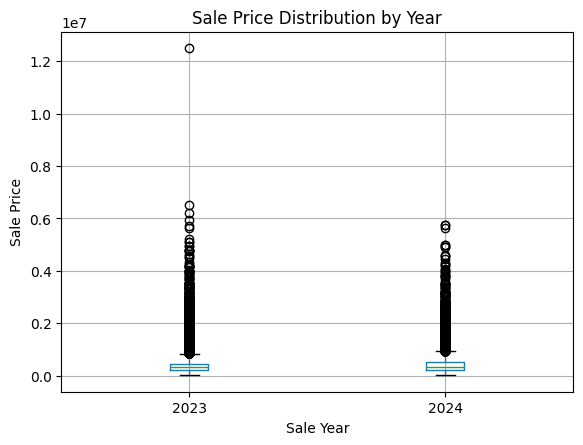

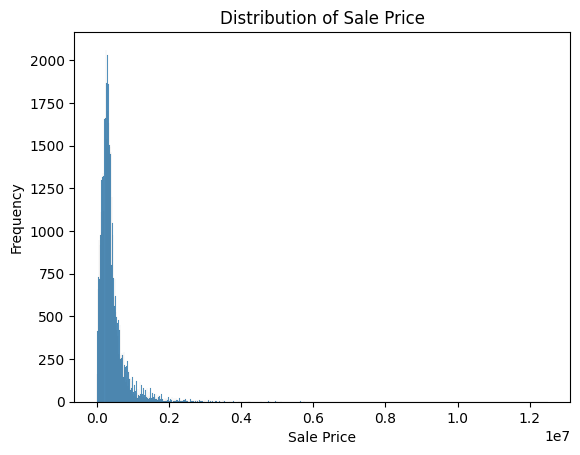

In [22]:
year_price_summary = train_data.groupby('sale_year')['sale_price'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    min='min',
    max='max'
)

print(year_price_summary.round(2))

# Draw the boxplot to find
train_data.boxplot(
    column='sale_price',
    by='sale_year'
)

plt.title('Sale Price Distribution by Year')
plt.suptitle('')
plt.xlabel('Sale Year')
plt.ylabel('Sale Price')
plt.show()


sns.histplot(train_data['sale_price'])
plt.title('Distribution of Sale Price')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
plt.show()

从上述结果看出，23年到24年中期之间sale price的中位数和均值都有着明显的上涨，且都存在极端值影响的情况以及右尾分布，这将影响我们进一步EDA的分析，因而我们下面采用log transform来抵消极端值产生的影响

           count   mean  median   std   min    max
sale_year                                         
2023       37520  12.63   12.66  0.77  9.27  16.34
2024       17333  12.72   12.74  0.76  9.27  15.56


<Figure size 900x500 with 0 Axes>

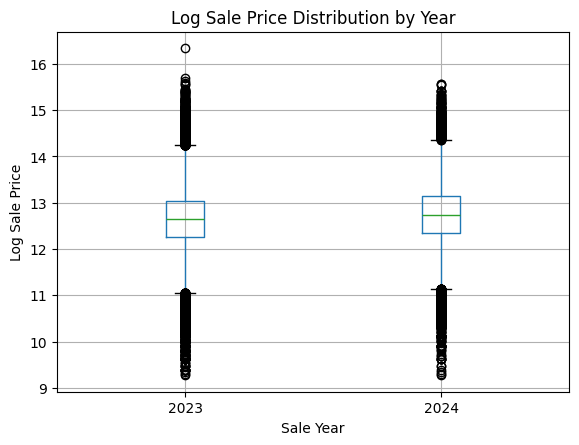

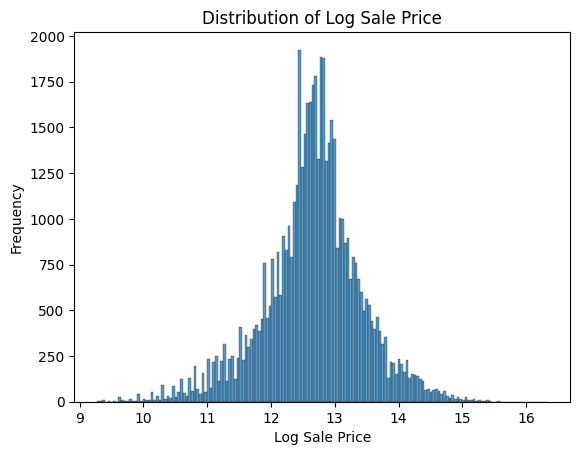

In [23]:
# Already checked that all sale prices are larger than 0
# use log transform to offset the influence of extreme value
train_data['log_sale_price'] = np.log1p(train_data['sale_price'])

year_logprice_summary = train_data.groupby('sale_year')['log_sale_price'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    min='min',
    max='max'
)

plt.figure(figsize=(9, 5))

print(year_logprice_summary.round(2))

# Draw the boxplot to find
train_data.boxplot(
    column='log_sale_price',
    by='sale_year'
)

plt.title('Log Sale Price Distribution by Year')
plt.suptitle('')
plt.xlabel('Sale Year')
plt.ylabel('Log Sale Price')
plt.show()

sns.histplot(train_data['log_sale_price'])
plt.title('Distribution of Log Sale Price')
plt.xlabel('Log Sale Price')
plt.ylabel('Frequency')
plt.show()

Form the above

从上图看出，采用log变换后，极端值的影响减小，sale price的分布更加偏向正态。我们通过对training set的response variable发现及log变换，应用到其余两个set中。


In [24]:
val_data['log_sale_price'] = np.log1p(val_data['sale_price'])
test_data['log_sale_price'] = np.log1p(test_data['sale_price'])


Organizing feature types

我们对每个不同类型的feature index进行归集，分成不同list，便于后续EDA分析

In [25]:
# Filter the feature that have missing value
missing_count_train = train_data.isnull().sum()
missing_fraction_train = train_data.isnull().mean()

missing_report = pd.DataFrame({
    'Count': missing_count_train,
    'Fraction': missing_fraction_train
})

missing_report = missing_report[missing_report['Count'] > 0].sort_values('Fraction', ascending=False)
print(missing_report)


                                                  Count  Fraction
loc_tax_special_service_area_num                  53291  0.971524
loc_school_unified_district_geoid                 52899  0.964378
loc_tax_tif_district_num                          50204  0.915246
char_tp_dsgn                                      29566  0.539004
char_tp_plan                                      15620  0.284761
prox_avg_school_rating_in_half_mile               13549  0.247006
acs5_median_household_total_occupied_year_built   12204  0.222486
char_gar1_cnst                                     9119  0.166244
other_school_district_elementary_avg_rating        2110  0.038466
other_school_district_secondary_avg_rating         2010  0.036643
loc_school_secondary_district_geoid                1954  0.035622
loc_school_elementary_district_geoid               1954  0.035622
acs5_median_household_renter_occupied_gross_rent   1377  0.025103
char_apts                                           487  0.008878
prox_num_f

检查miss value fraction比例在1%以内的feature，判断这些微小缺失值对应的样本数据是否对price有着较大影响



In [26]:
# Handle features whose missing value fractions are under 1%
# Extract features whose missing value fractions are under 1%
low_missing_cols = missing_report[missing_report['Fraction'] < 0.01].index
low_missing_cols_list = low_missing_cols.tolist()

print("Feature having missing fraction between 0% and 1% has amount", len(low_missing_cols_list), " ：")
print(low_missing_cols_list,'\n')

# Compare median sales price in missing value part to that in non-missing part
mnar_candidates = []

for col in low_missing_cols_list:
    missing_group = train_data[train_data[col].isnull()]["sale_price"]
    non_missing_group = train_data[train_data[col].notna()]["sale_price"]

    med_miss = missing_group.median()
    med_non_miss = non_missing_group.median()

    # If notna group's median not equal to 0, calculate diff percentage
    if med_non_miss > 0 and med_miss > 0:
        diff_pct = abs(med_miss - med_non_miss) / med_non_miss

        print(f"--- {col} ---")
        print(f"Missing median: {med_miss:.0f} | Non-missing median: {med_non_miss:.0f} | Diff: {diff_pct:.2%}")

        # if median's diff percentage outweigh 10%, identified as MNAR
        if diff_pct > 0.10:
            mnar_candidates.append(col)

print(f"\nFeatures identified as MNAR (price diff > 10%): {mnar_candidates}")



Feature having missing fraction between 0% and 1% has amount 19  ：
['char_apts', 'prox_num_foreclosure_per_1000_pin_past_5_years', 'loc_property_zip', 'acs5_median_household_owner_occupied_value', 'meta_cdu', 'loc_env_flood_fs_risk_direction', 'loc_env_flood_fs_factor', 'char_frpl', 'other_tax_bill_rate', 'char_gar1_att', 'char_gar1_area', 'char_porch', 'char_attic_fnsh', 'char_heat', 'char_bsmt_fin', 'char_gar1_size', 'char_bsmt', 'loc_access_cmap_walk_total_score', 'loc_access_cmap_walk_nta_score'] 

--- char_apts ---
Missing median: 242000 | Non-missing median: 325000 | Diff: 25.54%
--- prox_num_foreclosure_per_1000_pin_past_5_years ---
Missing median: 695000 | Non-missing median: 324000 | Diff: 114.51%
--- loc_property_zip ---
Missing median: 415000 | Non-missing median: 325000 | Diff: 27.69%
--- acs5_median_household_owner_occupied_value ---
Missing median: 203000 | Non-missing median: 325000 | Diff: 37.54%
--- meta_cdu ---
Missing median: 680000 | Non-missing median: 325000 | Dif

由于这些微小缺失比率的特征值，对比非特征值缺失的样本和特征值缺失样本的price中位数差异超过10%的，在以上列表的都满足。我们对缺失值数额超过50的进行missing indicator+众数/中位数进行填补，对小于50的特征值用简单插补法填补

In [27]:
# Select those feature having less than 50 missing value to replace by mode or median
# 1. 提取微小缺失和中低缺失列
tiny_missing_cols_list = missing_report[missing_report['Count'] <= 50].index.tolist()
mnar_list = [col for col in low_missing_cols_list if col not in tiny_missing_cols_list]

medians_dict = {}
modes_dict = {}
boolean_cols = [] # 就地记录哪些是二值列

for col in tiny_missing_cols_list + mnar_list:
    if col not in train_data.columns: continue

    # --- 就地识别 Boolean (非空取值 <= 2) ---
    unique_vals = train_data[col].dropna().unique()
    if len(unique_vals) <= 2 and len(unique_vals) > 0:
        boolean_cols.append(col)
        # 对 Boolean 用众数填
        mode_series = train_data[col].mode()
        medians_dict[col] = mode_series.iloc[0] if not mode_series.empty else 0
        continue # 跳过后续的普通数值/字符串判断

    # --- 原有逻辑 ---
    if pd.api.types.is_numeric_dtype(train_data[col]):
        median_val = train_data[col].median()
        medians_dict[col] = median_val if pd.notna(median_val) else 0
    else:
        mode_series = train_data[col].mode()
        modes_dict[col] = mode_series.iloc[0] if not mode_series.empty else "Unknown"


def fill_datasets(df):
    df = df.copy()

    for col in tiny_missing_cols_list:
        if col not in df.columns: continue

        if col in boolean_cols:
            # 拯救 Boolean：填补并强制保留 Int64 格式
            df[col] = df[col].fillna(medians_dict[col]).astype('Int64')
        elif col in medians_dict:
            df[col] = df[col].astype(float).fillna(medians_dict[col])
        elif col in modes_dict:
            df[col] = df[col].fillna(modes_dict[col])

    for col in mnar_list:
        if col not in df.columns: continue

        ind_col = f"{col}_missing"
        df[ind_col] = df[col].isna().astype(int)

        if col in boolean_cols:
            df[col] = df[col].fillna(medians_dict[col]).astype('Int64')
        elif col in medians_dict:
            df[col] = df[col].astype(float).fillna(medians_dict[col])
        elif col in modes_dict:
            df[col] = df[col].fillna(modes_dict[col])

    return df

# 执行填补
train_data = fill_datasets(train_data)
val_data = fill_datasets(val_data)
test_data = fill_datasets(test_data)


# 检查填补后是否还有极低缺失
remaining_missing = train_data[tiny_missing_cols_list + mnar_list].isnull().sum().sum()
print(f"填补后 train_data 剩余缺失值数量: {remaining_missing}")

填补后 train_data 剩余缺失值数量: 0


In [28]:
for col in tiny_missing_cols_list + mnar_list:
    if col in medians_dict and property_list[col].notna().all(): # 确认没有空值了
        train_data[col] = train_data[col].astype('int64')

针对missing fraction占比超过90%的feature

In [29]:
cols_to_fill = [
    'loc_tax_special_service_area_num',
    'loc_school_unified_district_geoid',
    'loc_tax_tif_district_num'
]

for df in [train_data, val_data, test_data]:
    for col in cols_to_fill:
        # 1. 先定义缺失指示器 (必须加上，因为这 90% 的缺失本身就是特征)
        df[f"{col}_is_missing"] = df[col].isnull().astype(int)

        # 2. 填补缺失值 (将原本的 NaN 填补为 "Unknown")
        # 使用 .astype('string') 而不是 str，是为了保证如果是其他缺失值（<NA>）仍然能被识别
        df[col] = df[col].fillna("Unknown").astype('string')

        # 3. (可选) 转为 category 类型。对于高基数的字符串，转化为 category 可以让 LightGBM 直接作为类别特征处理，节省内存并提高效率
        df[col] = df[col].astype('category')


In [30]:
high_missing_cols_list = missing_report[missing_report['Fraction'] >= 0.01].index.tolist()

cols_already_handled = [
    'loc_tax_special_service_area_num',
    'loc_school_unified_district_geoid',
    'loc_tax_tif_district_num'
]
high_missing_cols_list = [c for c in high_missing_cols_list if c not in cols_already_handled]

# 先对原始 dtype 做快照（避免后续 fillna/astype 改变判断依据）
original_dtypes = {col: train_data[col].dtype for col in high_missing_cols_list}

high_medians = {}
high_modes = {}
geoid_cols = ['loc_school_elementary_district_geoid', 'loc_school_secondary_district_geoid']

# 布尔型 / 0-1 型列的识别（Int64、boolean、以及取值子集为 {0,1} 的整数列）
def is_boolean_like(col):
    s = train_data[col]
    if pd.api.types.is_bool_dtype(s):
        return True
    if pd.api.types.is_integer_dtype(s):
        uniq = set(s.dropna().unique().tolist())
        return uniq.issubset({0, 1})
    return False

bool_like_cols = {c for c in high_missing_cols_list if is_boolean_like(c)}

# 2. 提取中位数和众数（带防崩溃机制）
for col in high_missing_cols_list:
    if col in geoid_cols:
        continue
    if col in bool_like_cols:
        continue  # 布尔型不取中位数/众数，走单独分支

    if pd.api.types.is_numeric_dtype(train_data[col]):
        med = train_data[col].median()
        high_medians[col] = med if pd.notna(med) else 0.0
    else:
        mode_series = train_data[col].mode()
        if not mode_series.empty and pd.notna(mode_series.iloc[0]):
            high_modes[col] = mode_series.iloc[0]
        else:
            high_modes[col] = "Unknown"

# 3. 定义高缺失率填补函数
def fill_high_missing(df, cols_list, medians_map, modes_map, geoids, bool_cols, orig_dtypes):
    df = df.copy()

    for col in cols_list:
        # A. 缺失指示器（加去重保护，防止重复调用）
        miss_col = f"{col}_missing"
        if miss_col not in df.columns:
            df[miss_col] = df[col].isna().astype(int)

        # B. 按列性质分类填补
        if col in geoids:
            # 学区代码：填 Unknown，保持 string
            df[col] = df[col].fillna("Unknown").astype('string')

        elif col in bool_cols:
            # 布尔/0-1 列：不参与数值中位数，填 0 或 False，保持 Int64/boolean
            orig_dtype = orig_dtypes.get(col)
            if pd.api.types.is_bool_dtype(orig_dtype):
                df[col] = df[col].fillna(False).astype('boolean')
            else:
                # 原本是 Int64 的 0/1 列：填 0，保持 Int64，不转 float
                df[col] = df[col].fillna(0).astype('Int64')

        elif col in medians_map:
            # 真·数值型：安全转数值后填中位数
            df[col] = pd.to_numeric(df[col], errors='coerce')
            df[col] = df[col].fillna(medians_map[col]).astype(float)

        elif col in modes_map:
            orig_dtype = orig_dtypes.get(col)
            if pd.api.types.is_integer_dtype(orig_dtype):
                # 其他整数型类别列：-1 表示 Unknown
                df[col] = df[col].fillna(-1).astype('Int64')
            else:
                df[col] = df[col].fillna(modes_map[col]).astype('string')

    return df

# 4. 执行（显式传参，避免全局变量陷阱）
train_data = fill_high_missing(
    train_data, high_missing_cols_list, high_medians, high_modes, geoid_cols, bool_like_cols, original_dtypes
)
val_data = fill_high_missing(
    val_data, high_missing_cols_list, high_medians, high_modes, geoid_cols, bool_like_cols, original_dtypes
)
test_data = fill_high_missing(
    test_data, high_missing_cols_list, high_medians, high_modes, geoid_cols, bool_like_cols, original_dtypes
)

In [31]:
# Check again whether there is any missing value left

check_miss_train = train_data.isnull().sum().sort_values(ascending=False)
check_miss_vali = val_data.isnull().sum().sort_values(ascending=False)
check_miss_test = test_data.isnull().sum().sort_values(ascending=False)

check_miss_train = check_miss_train[check_miss_train > 0]
check_miss_vali = check_miss_vali[check_miss_vali > 0]
check_miss_test = check_miss_test[check_miss_test > 0]

print ('train missing value left: \n',check_miss_train)
print ('\nvali missing value left: \n',check_miss_vali)
print ('\ntest missing value left: \n',check_miss_test)

train missing value left: 
 Series([], dtype: int64)

vali missing value left: 
 char_air      2
char_yrblt    1
dtype: int64

test missing value left: 
 char_air                                  1
acs5_median_income_household_past_year    1
dtype: int64


我们检查到，training set中已经不存在missing value的情况，但是在validation set 和test set仍然存在，这是因为这一部分的missing value按照年度+季度划分时仅仅被包含在后两者dataset中。同时由于missing value非常少，使得training set中并未观测出缺失的现象。 为了防止leakage的产生，同时这三类待填补的missing value的数量非常稀少，我们采用simple imputation的方法，从training set中的对应feature获取mode或median数据进行填补。

In [32]:
# 1. 获取缺失列
missing_cols = set(val_data.columns[val_data.isnull().any()]) | \
               set(test_data.columns[test_data.isnull().any()])

# 2. 定义安全填补函数
def safe_fill_missing(train_df, target_df, col):
    # 如果 train 里没这一列，或者全为空，就不填了
    if col not in train_df.columns or train_df[col].isnull().all():
        return target_df

    train_dtype = train_df[col].dtype
    target_dtype = target_df[col].dtype

    # ==========================================
    # 情形 A：类别/字符串型 (string, object, category) -> 绝不转数值，用众数填
    # ==========================================
    if pd.api.types.is_string_dtype(train_dtype) or \
       pd.api.types.is_object_dtype(train_dtype) or \
       isinstance(train_dtype, pd.CategoricalDtype):

        mode_series = train_df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else "Unknown"

        # 如果是 category 类型，需先添加新的类别
        if isinstance(target_dtype, pd.CategoricalDtype):
            if fill_val not in target_df[col].cat.categories:
                target_df[col] = target_df[col].cat.add_categories([fill_val])

        target_df[col] = target_df[col].fillna(fill_val)

    # ==========================================
    # 情形 B：可空整数型 (Int64) -> 填补其众数，保持 Int64
    # ==========================================
    elif pd.api.types.is_integer_dtype(train_dtype):
        # 整数类别的填补通常用众数，而不是中位数（避免出现 2.5 这种无意义小数）
        mode_series = train_df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else 0

        # 填补并保持 Int64
        target_df[col] = target_df[col].fillna(fill_val).astype('Int64')

    # ==========================================
    # 情形 C：纯连续数值型 (float) -> 用中位数填
    # ==========================================
    elif pd.api.types.is_numeric_dtype(train_dtype):
        fill_val = train_df[col].median()
        if pd.isna(fill_val):
            fill_val = 0.0
        # 直接按 float 填
        target_df[col] = pd.to_numeric(target_df[col], errors='coerce').astype('float64').fillna(fill_val)

    # ==========================================
    # 情形 D：其他兜底
    # ==========================================
    else:
        mode_series = train_df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else "Unknown"
        target_df[col] = target_df[col].fillna(fill_val)

    return target_df

# 3. 循环填补
for col in missing_cols:
    print(f"Feature [{col:50s}] -> 尝试用 Train 的统计量填补 Val 和 Test...")
    val_data = safe_fill_missing(train_data, val_data, col)
    test_data = safe_fill_missing(train_data, test_data, col)

# 4. 最终验证
print("\n--- Final check ---")
print("train missing:", train_data.isnull().sum().sum())
print("val missing:  ", val_data.isnull().sum().sum())
print("test missing: ", test_data.isnull().sum().sum())

# 强制类型对齐（可选，确保三套数据集类型一致）
for col in missing_cols:
    if col in train_data.columns:
        # 对齐 Int64
        if pd.api.types.is_integer_dtype(train_data[col]):
            val_data[col] = val_data[col].round().astype('Int64')
            test_data[col] = test_data[col].round().astype('Int64')
        # 对齐 string
        elif pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
            val_data[col] = val_data[col].astype(train_data[col].dtype)
            test_data[col] = test_data[col].astype(train_data[col].dtype)

Feature [char_yrblt                                        ] -> 尝试用 Train 的统计量填补 Val 和 Test...
Feature [acs5_median_income_household_past_year            ] -> 尝试用 Train 的统计量填补 Val 和 Test...
Feature [char_air                                          ] -> 尝试用 Train 的统计量填补 Val 和 Test...

--- Final check ---
train missing: 0
val missing:   0
test missing:  0


注意以上的对training set之外其余两个set中发现的存有缺失值的特征，我们进行了简单填补，虽然有年份类的特征值数据，但在我们training set没发现的情况下，以及缺失量非常小的情况，我们评估使用简单插补（利用中位数or众数）填补是合理的

In [33]:
# delete irrelevant columns for training model

drop_cols = ['sale_date',  'sale_month', 'sale_year', 'sale_quarter','transaction_id']

train_data = train_data.drop(columns=[c for c in drop_cols if c in train_data.columns])
val_data   = val_data.drop(columns=[c for c in drop_cols if c in val_data.columns])
test_data  = test_data.drop(columns=[c for c in drop_cols if c in test_data.columns])

# Verify whether 3 sets' columns still the same
cols_train = set(train_data.columns)
cols_val   = set(val_data.columns)
cols_test  = set(test_data.columns)

print("train vs val diff:", cols_train ^ cols_val)
print("train vs test diff:", cols_train ^ cols_test)
print("All 3 set columns are the same:", cols_train == cols_val == cols_test)

train vs val diff: set()
train vs test diff: set()
All 3 set columns are the same: True


In [34]:
exclude_cols = ['sale_price', 'log_sale_price']
type_map = var_dict.set_index('variable')['type'].to_dict()
available_features = [c for c in train_data.columns if c not in exclude_cols]

# 初始化四个包
pkg_continuous = []     # 连续数值型 (float)
pkg_discrete = []       # 离散数值型 (int, 计数)
pkg_boolean = []        # 二值/指示器 (严格 0/1)
pkg_category = []       # 类别/标签 (str, 或 1/2 这类非真布尔)

for col in available_features:
    # 1. 获取该列的去重值（转成 set 方便比对，统一转成字符串以防 0 和 '0' 混杂）
    unique_set = set(train_data[col].dropna().astype(str).unique())
    n_unique = len(unique_set)

    # ==========================================
    # 优先级 1：真正的 Boolean / Indicator 类 (严格判定)
    # ==========================================
    # 真正的 boolean 必须是 0/1（或者布尔值转字符串后的 '0'/'1'）
    if n_unique > 0 and unique_set.issubset({'0', '1'}):
        pkg_boolean.append(col)
        continue

    # ==========================================
    # 优先级 2：Categorical / Label 类 (非 0/1 的低基数)
    # ==========================================
    col_type = type_map.get(col, 'unknown')

    # 如果字典里定义为 categorical，或者当前列已经是 string 类型
    if col_type == 'categorical' or pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
        pkg_category.append(col)
        continue

    # ==========================================
    # 优先级 3：Numeric 拆分为 Continuous 和 Discrete
    # ==========================================
    if col_type == 'numeric':
        # 如果是数值，且取值少（<=15），且全是整数
        unique_vals = train_data[col].dropna().unique()
        if n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            pkg_discrete.append(col)
        else:
            pkg_continuous.append(col)
        continue

    # ==========================================
    # 优先级 4：字典没有的自定义特征（兜底）
    # ==========================================
    if pd.api.types.is_float_dtype(train_data[col]) and n_unique > 15:
        pkg_continuous.append(col)
    elif n_unique <= 15:
        pkg_discrete.append(col)
    else:
        pkg_category.append(col)

# ==========================================
# 打印结果并拆分 DataFrame
# ==========================================
print(f"✅ 连续数值型 (Continuous, float): {len(pkg_continuous)} 个")
print(f"✅ 离散数值型 (Discrete, int/低基数): {len(pkg_discrete)} 个")
print(f"✅ 布尔/指示器 (Boolean, 0/1): {len(pkg_boolean)} 个")
print(f"✅ 类别/标签 (Category, str): {len(pkg_category)} 个")

# 打印一下被“踢出” Boolean 的列，验证一下是不是 1/2 这种
suspect_cat = [c for c in pkg_category if set(train_data[c].dropna().astype(str).unique()).issubset({'1', '2'})]
if suspect_cat:
    print(f"\n💡 发现 {len(suspect_cat)} 个原本可能被误判为 Boolean 的 1/2 类别列，已被正确归入 Category：{suspect_cat[:5]}")

# 真正切分数据
df_continuous = train_data[pkg_continuous]
df_discrete = train_data[pkg_discrete]
df_boolean = train_data[pkg_boolean]
df_category = train_data[pkg_category]

✅ 连续数值型 (Continuous, float): 52 个
✅ 离散数值型 (Discrete, int/低基数): 7 个
✅ 布尔/指示器 (Boolean, 0/1): 27 个
✅ 类别/标签 (Category, str): 32 个

💡 发现 2 个原本可能被误判为 Boolean 的 1/2 类别列，已被正确归入 Category：['char_use', 'char_air']


对不同类别的feature进行分包后，先对numeric的连续数值型，看缺失率排序以及进行EDA分析，我们对这部分feature建立直方图，与log sale price的关系图，和相关系数热力图

对Continuous的feature集合进行直方图观测分布

In [35]:
# 1. 筛选出包含类似小数点格式的类别列
decimal_cat_cols = []

for col in pkg_category:
    # 获取去重后的非空值，转成字符串
    unique_vals = train_data[col].dropna().astype(str).unique()

    if len(unique_vals) == 0:
        continue

    # 正则检查：至少有一个值符合 "数字.数字" 的格式 (例如 1.0, 9.9)
    has_decimal = any(re.match(r'^-?\d+\.\d+$', str(val).strip()) for val in unique_vals)

    if has_decimal:
        # 打印前 5 个值看看长什么样
        sample_vals = unique_vals[:5]
        decimal_cat_cols.append(col)
        print(f"⚠️ 列 [{col}] 疑似包含小数点：样本值 = {sample_vals}")

if not decimal_cat_cols:
    print("✅ 未发现包含小数点的类别特征。")
else:
    print(f"\n共计发现 {len(decimal_cat_cols)} 个列包含小数点，需要处理。")

⚠️ 列 [loc_property_zip] 疑似包含小数点：样本值 = ['60062.0' '60534.0' '60457.0' '60628.0' '60462.0']
⚠️ 列 [char_type_resd] 疑似包含小数点：样本值 = ['2' '1' '4' '5' '3']
⚠️ 列 [char_tp_plan] 疑似包含小数点：样本值 = ['2.0' '1.0']
⚠️ 列 [loc_chicago_ward_num] 疑似包含小数点：样本值 = ['Non-Chicago' '8.0' '1.0' '37.0' '28.0']
⚠️ 列 [loc_school_elementary_district_geoid] 疑似包含小数点：样本值 = ['1724420.0' '1723850.0' '1728890.0' '610178.0' '1730220.0']
⚠️ 列 [loc_school_secondary_district_geoid] 疑似包含小数点：样本值 = ['1729010.0' '1726880.0' '1708400.0' '609710.0' '1738970.0']
⚠️ 列 [loc_school_unified_district_geoid] 疑似包含小数点：样本值 = ['Unknown' '1713710.0' '1705050.0' '1714100.0' '1708550.0']
⚠️ 列 [loc_tax_special_service_area_num] 疑似包含小数点：样本值 = ['Unknown' '30050108.0' '31290100.0' '30210150.0' '30820104.0']
⚠️ 列 [loc_tax_tif_district_num] 疑似包含小数点：样本值 = ['Unknown' '30070514.0' '30210561.0' '30210592.0' '30140500.0']

共计发现 9 个列包含小数点，需要处理。


In [36]:
# 展示前 10 行 + dtype + 缺失统计
cat_sample = train_data[pkg_category].head(10).T  # 转置方便查看

# 附加 dtype 和缺失信息
cat_sample['dtype'] = train_data[pkg_category].dtypes
cat_sample['missing_rate'] = train_data[pkg_category].isnull().mean()

pd.set_option('display.max_rows', None)
pd.set_option('display.width', 300)
print(cat_sample)

property_id                          4211120100000 18023090540000 23013140100000 25112030810000 27144070010000 29104080390000   32192070200000 2114150230000 8241130090000 13363080100000           dtype  missing_rate
loc_property_city                       NORTHBROOK          LYONS  HICKORY HILLS        CHICAGO    ORLAND PARK         DOLTON  CHICAGO HEIGHTS      PALATINE   DES PLAINES        CHICAGO          object           0.0
loc_property_zip                           60062.0        60534.0        60457.0        60628.0        60462.0        60419.0          60411.0       60074.0       60016.0        60647.0  string[python]           0.0
char_type_resd                                   2              1              1              1              4              1                5             2             1              5  string[python]           0.0
char_cnst_qlty                                   2              2              2              2              1              2           

In [37]:
print("\n🔍 2. 检查所有 Category 特征在 Train/Val/Test 中的 nunique：\n")

datasets = {'Train': train_data, 'Val': val_data, 'Test': test_data}

report_data = []
for col in pkg_category:
    row = {'Feature': col}

    # 统计三个数据集中的 nunique
    for name, df in datasets.items():
        row[f'{name} nunique'] = df[col].nunique() if col in df.columns else None

    # 提取 Train 集中的具体 Unique 值（最多展示前 10 个防刷屏，不足 10 个全展示）
    if col in train_data.columns:
        unique_vals = train_data[col].dropna().unique()
        sample_str = ", ".join([str(x) for x in unique_vals[:10]])
        if len(unique_vals) > 10:
            sample_str += " ..."
        row['Train Unique Values'] = f"[{sample_str}]"
    else:
        row['Train Unique Values'] = "N/A"

    report_data.append(row)

# 转换为 DataFrame 并格式化输出
report_df = pd.DataFrame(report_data)

# 设置 pandas 显示选项，防止列被折叠，防止长字符串被截断
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)
pd.set_option('display.max_colwidth', 80)

print(report_df.to_string(index=False))


🔍 2. 检查所有 Category 特征在 Train/Val/Test 中的 nunique：

                             Feature  Train nunique  Val nunique  Test nunique                                                                                                                      Train Unique Values
                   loc_property_city            132          129           132                [NORTHBROOK, LYONS, HICKORY HILLS, CHICAGO, ORLAND PARK, DOLTON, CHICAGO HEIGHTS, PALATINE, DES PLAINES, WESTCHESTER ...]
                    loc_property_zip            169          167           169                                           [60062.0, 60534.0, 60457.0, 60628.0, 60462.0, 60419.0, 60411.0, 60074.0, 60016.0, 60647.0 ...]
                      char_type_resd              6            6             6                                                                                                                     [2, 1, 4, 5, 3, 9.9]
                      char_cnst_qlty              3            3             3      

In [38]:
print("🚀 1. 开始对所有类别列进行强制清洗并转换为 string[python] ...")

for col in pkg_category:
    for name, df in datasets.items():
        if col in df.columns:
            # 1. 先全部转成普通字符串（此时 Int64 会变 '1'，float 会变 '1.0'）
            s = df[col].astype(str)

            # 2. 正则去除末尾的 .0（例如 '1.0' -> '1'）
            s = s.str.replace(r'\.0$', '', regex=True)

            # 3. 把原本是空值被转成的 'nan', 'None' 等安全地转回 pandas 的 <NA>
            s = s.replace(['nan', 'NaN', '<NA>', 'None', 'NaT'], pd.NA)

            # 4. 终极强转：转换为纯正的 string[python]
            df[col] = s.astype('string')

🚀 1. 开始对所有类别列进行强制清洗并转换为 string[python] ...


In [39]:
exclude_cols = ['sale_price', 'log_sale_price']
type_map = var_dict.set_index('variable')['type'].to_dict()
available_features = [c for c in train_data.columns if c not in exclude_cols]

# 初始化四个包
pkg_continuous = []     # 连续数值型 (float)
pkg_discrete = []       # 离散数值型 (int, 计数)
pkg_boolean = []        # 二值/指示器 (严格 0/1)
pkg_category = []       # 类别/标签 (str, 或 1/2 这类非真布尔)

for col in available_features:
    # 1. 获取该列的去重值（转成 set 方便比对，统一转成字符串以防 0 和 '0' 混杂）
    unique_set = set(train_data[col].dropna().astype(str).unique())
    n_unique = len(unique_set)

    # ==========================================
    # 优先级 1：真正的 Boolean / Indicator 类 (严格判定)
    # ==========================================
    # 真正的 boolean 必须是 0/1（或者布尔值转字符串后的 '0'/'1'）
    if n_unique > 0 and unique_set.issubset({'0', '1'}):
        pkg_boolean.append(col)
        continue

    # ==========================================
    # 优先级 2：Categorical / Label 类 (非 0/1 的低基数)
    # ==========================================
    col_type = type_map.get(col, 'unknown')

    # 如果字典里定义为 categorical，或者当前列已经是 string 类型
    if col_type == 'categorical' or pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
        pkg_category.append(col)
        continue

    # ==========================================
    # 优先级 3：Numeric 拆分为 Continuous 和 Discrete
    # ==========================================
    if col_type == 'numeric':
        # 如果是数值，且取值少（<=15），且全是整数
        unique_vals = train_data[col].dropna().unique()
        if n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            pkg_discrete.append(col)
        else:
            pkg_continuous.append(col)
        continue

    # ==========================================
    # 优先级 4：字典没有的自定义特征（兜底）
    # ==========================================
    if pd.api.types.is_float_dtype(train_data[col]) and n_unique > 15:
        pkg_continuous.append(col)
    elif n_unique <= 15:
        pkg_discrete.append(col)
    else:
        pkg_category.append(col)

# ==========================================
# 打印结果并拆分 DataFrame
# ==========================================
print(f"✅ 连续数值型 (Continuous, float): {len(pkg_continuous)} 个")
print(f"✅ 离散数值型 (Discrete, int/低基数): {len(pkg_discrete)} 个")
print(f"✅ 布尔/指示器 (Boolean, 0/1): {len(pkg_boolean)} 个")
print(f"✅ 类别/标签 (Category, str): {len(pkg_category)} 个")

# 打印一下被“踢出” Boolean 的列，验证一下是不是 1/2 这种
suspect_cat = [c for c in pkg_category if set(train_data[c].dropna().astype(str).unique()).issubset({'1', '2'})]
if suspect_cat:
    print(f"\n💡 发现 {len(suspect_cat)} 个原本可能被误判为 Boolean 的 1/2 类别列，已被正确归入 Category：{suspect_cat[:5]}")

# 真正切分数据
df_continuous = train_data[pkg_continuous]
df_discrete = train_data[pkg_discrete]
df_boolean = train_data[pkg_boolean]
df_category = train_data[pkg_category]

✅ 连续数值型 (Continuous, float): 52 个
✅ 离散数值型 (Discrete, int/低基数): 7 个
✅ 布尔/指示器 (Boolean, 0/1): 27 个
✅ 类别/标签 (Category, str): 32 个

💡 发现 3 个原本可能被误判为 Boolean 的 1/2 类别列，已被正确归入 Category：['char_use', 'char_air', 'char_tp_plan']


再次检查

In [40]:
# 展示前 10 行 + dtype + 缺失统计
cat_sample = df_category.head(10).T  # 转置方便查看

# 附加 dtype 和缺失信息
cat_sample['dtype'] = df_category.dtypes
cat_sample['missing_rate'] = df_category.isnull().mean()

pd.set_option('display.max_rows', None)
pd.set_option('display.width', 300)
print(cat_sample)

property_id                          4211120100000 18023090540000 23013140100000 25112030810000 27144070010000 29104080390000   32192070200000 2114150230000 8241130090000 13363080100000           dtype  missing_rate
loc_property_city                       NORTHBROOK          LYONS  HICKORY HILLS        CHICAGO    ORLAND PARK         DOLTON  CHICAGO HEIGHTS      PALATINE   DES PLAINES        CHICAGO  string[python]           0.0
loc_property_zip                             60062          60534          60457          60628          60462          60419            60411         60074         60016          60647  string[python]           0.0
char_type_resd                                   2              1              1              1              4              1                5             2             1              5  string[python]           0.0
char_cnst_qlty                                   2              2              2              2              1              2           

In [41]:
# 1. 筛选出包含类似小数点格式的类别列
decimal_cat_cols = []

for col in pkg_category:
    # 获取去重后的非空值，转成字符串
    unique_vals = train_data[col].dropna().astype(str).unique()

    if len(unique_vals) == 0:
        continue

    # 正则检查：至少有一个值符合 "数字.数字" 的格式 (例如 1.0, 9.9)
    has_decimal = any(re.match(r'^-?\d+\.\d+$', str(val).strip()) for val in unique_vals)

    if has_decimal:
        # 打印前 5 个值看看长什么样
        sample_vals = unique_vals[:5]
        decimal_cat_cols.append(col)
        print(f"⚠️ 列 [{col}] 疑似包含小数点：样本值 = {sample_vals}")

if not decimal_cat_cols:
    print("✅ 未发现包含小数点的类别特征。")
else:
    print(f"\n共计发现 {len(decimal_cat_cols)} 个列包含小数点，需要处理。")

⚠️ 列 [char_type_resd] 疑似包含小数点：样本值 = ['2' '1' '4' '5' '3']

共计发现 1 个列包含小数点，需要处理。


以上对category类别的包检查，并进行了数据类型的再次转换，以便于后续EDA和特征工程的操作。最后再次检测无异常，char_type_resd 结果人工判别是正常情况，因为包含了9.9的str值导致检测出小数点。

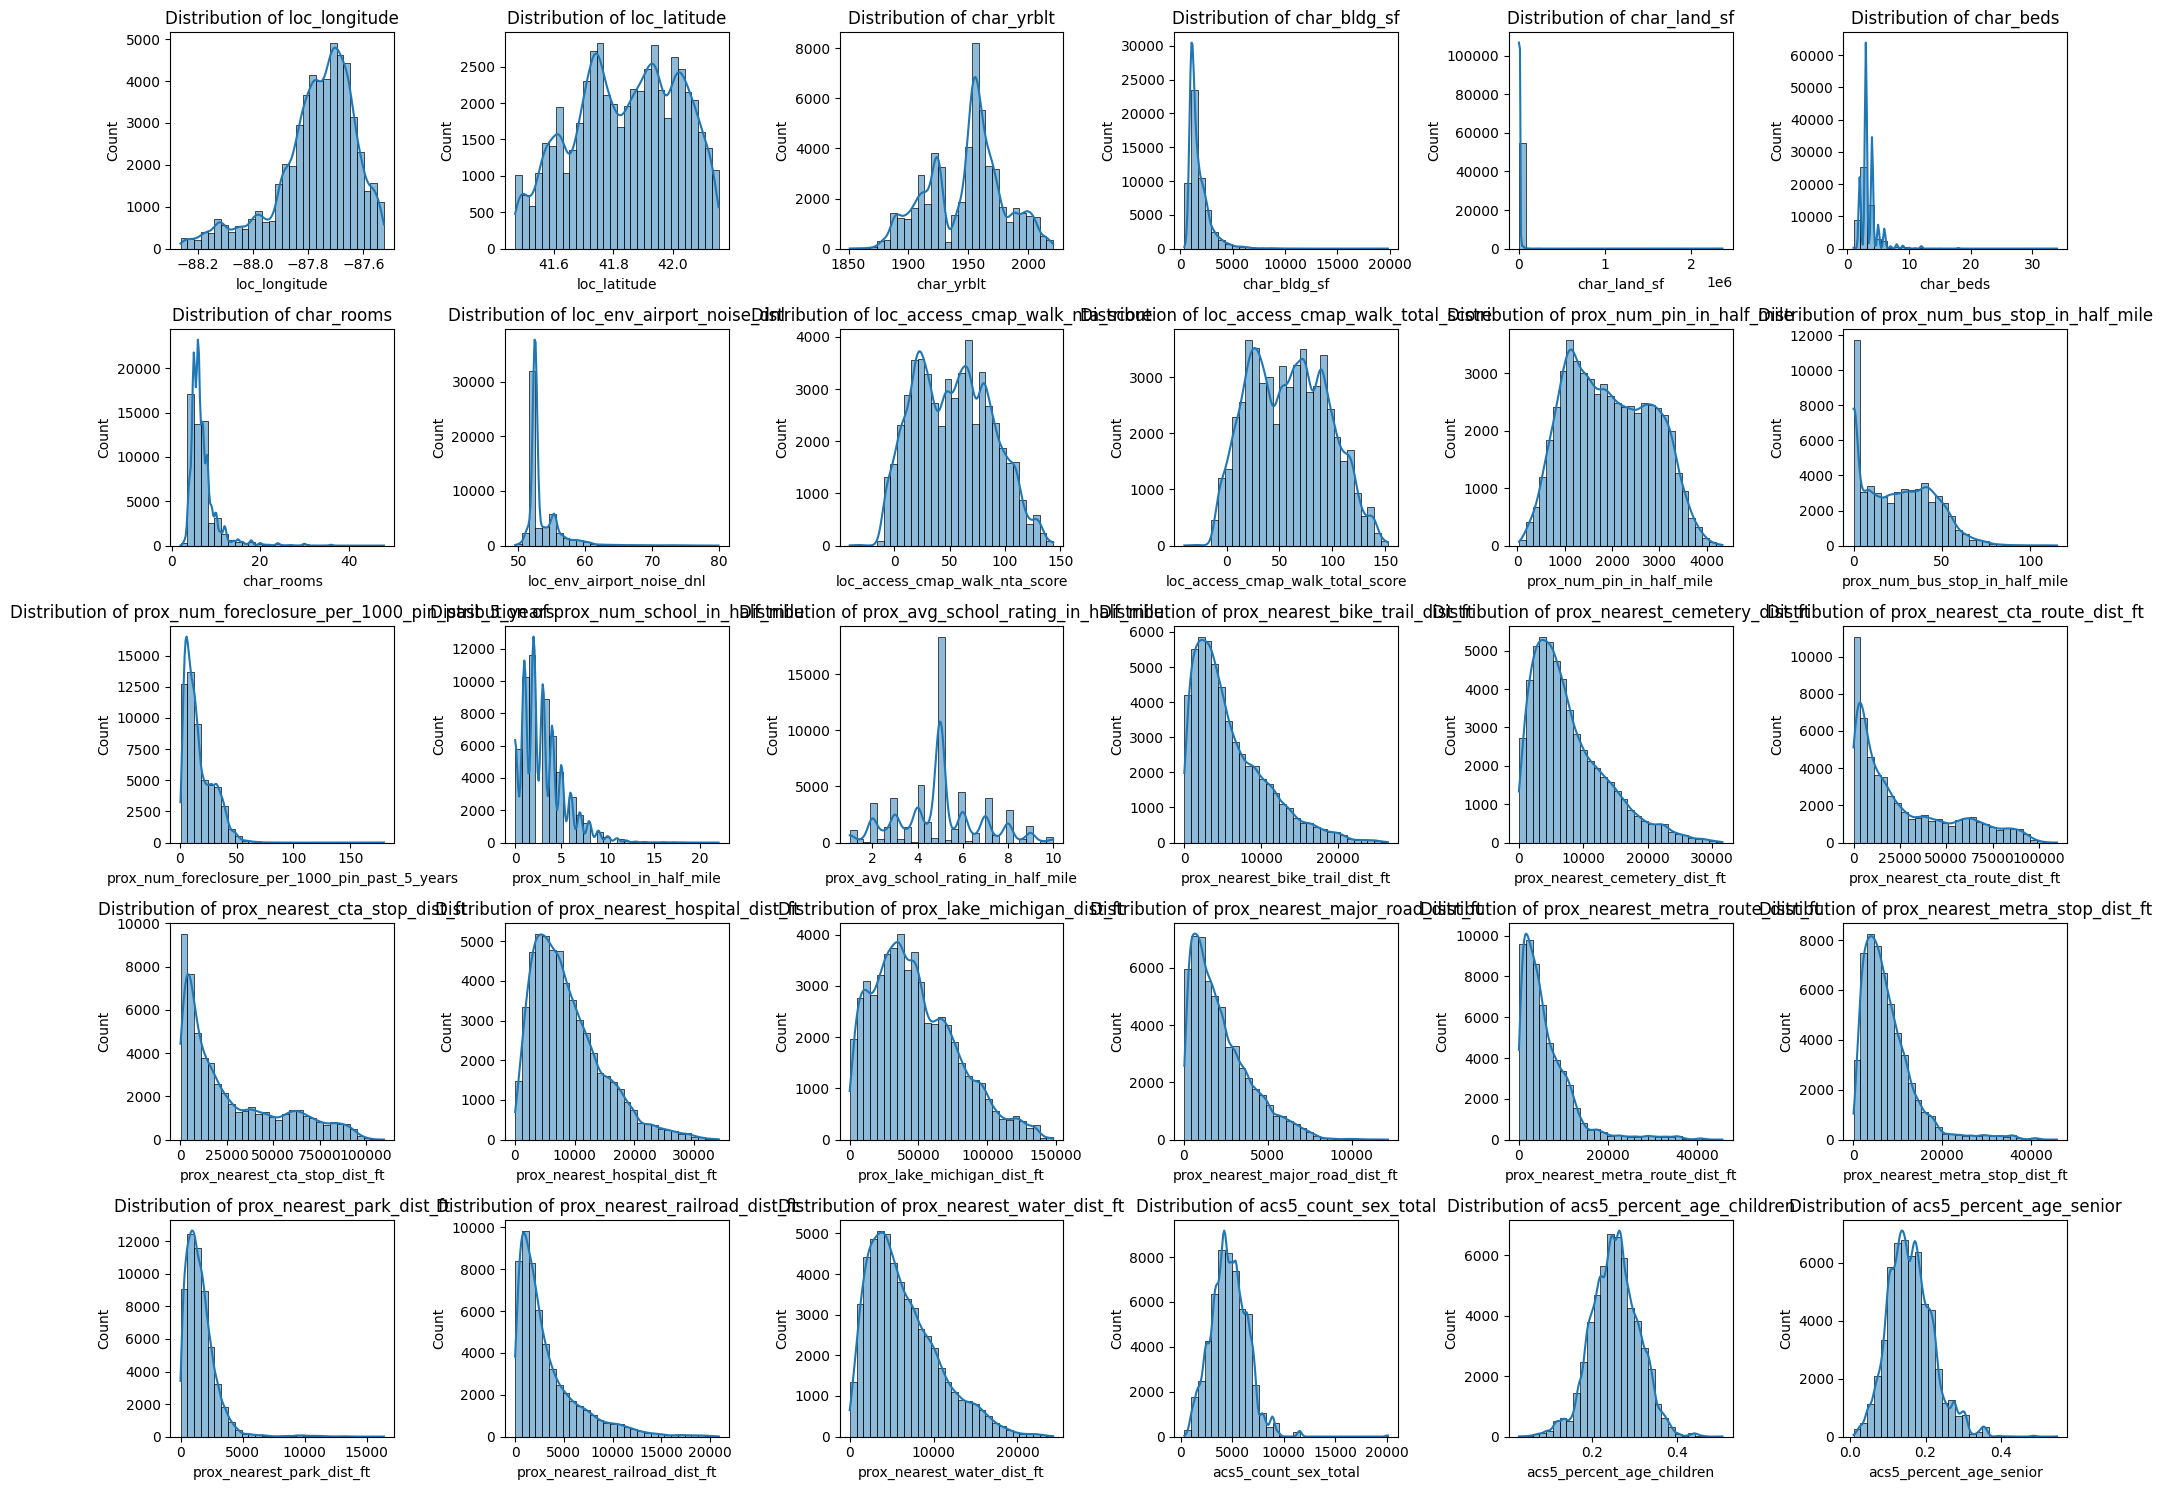

In [42]:
# histplot to make EDA
fig, axes = plt.subplots(nrows=5, ncols=6, figsize=(20, 15))
axes = axes.flatten()

for i, col in enumerate(pkg_continuous[:30]):
    sns.histplot(train_data[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

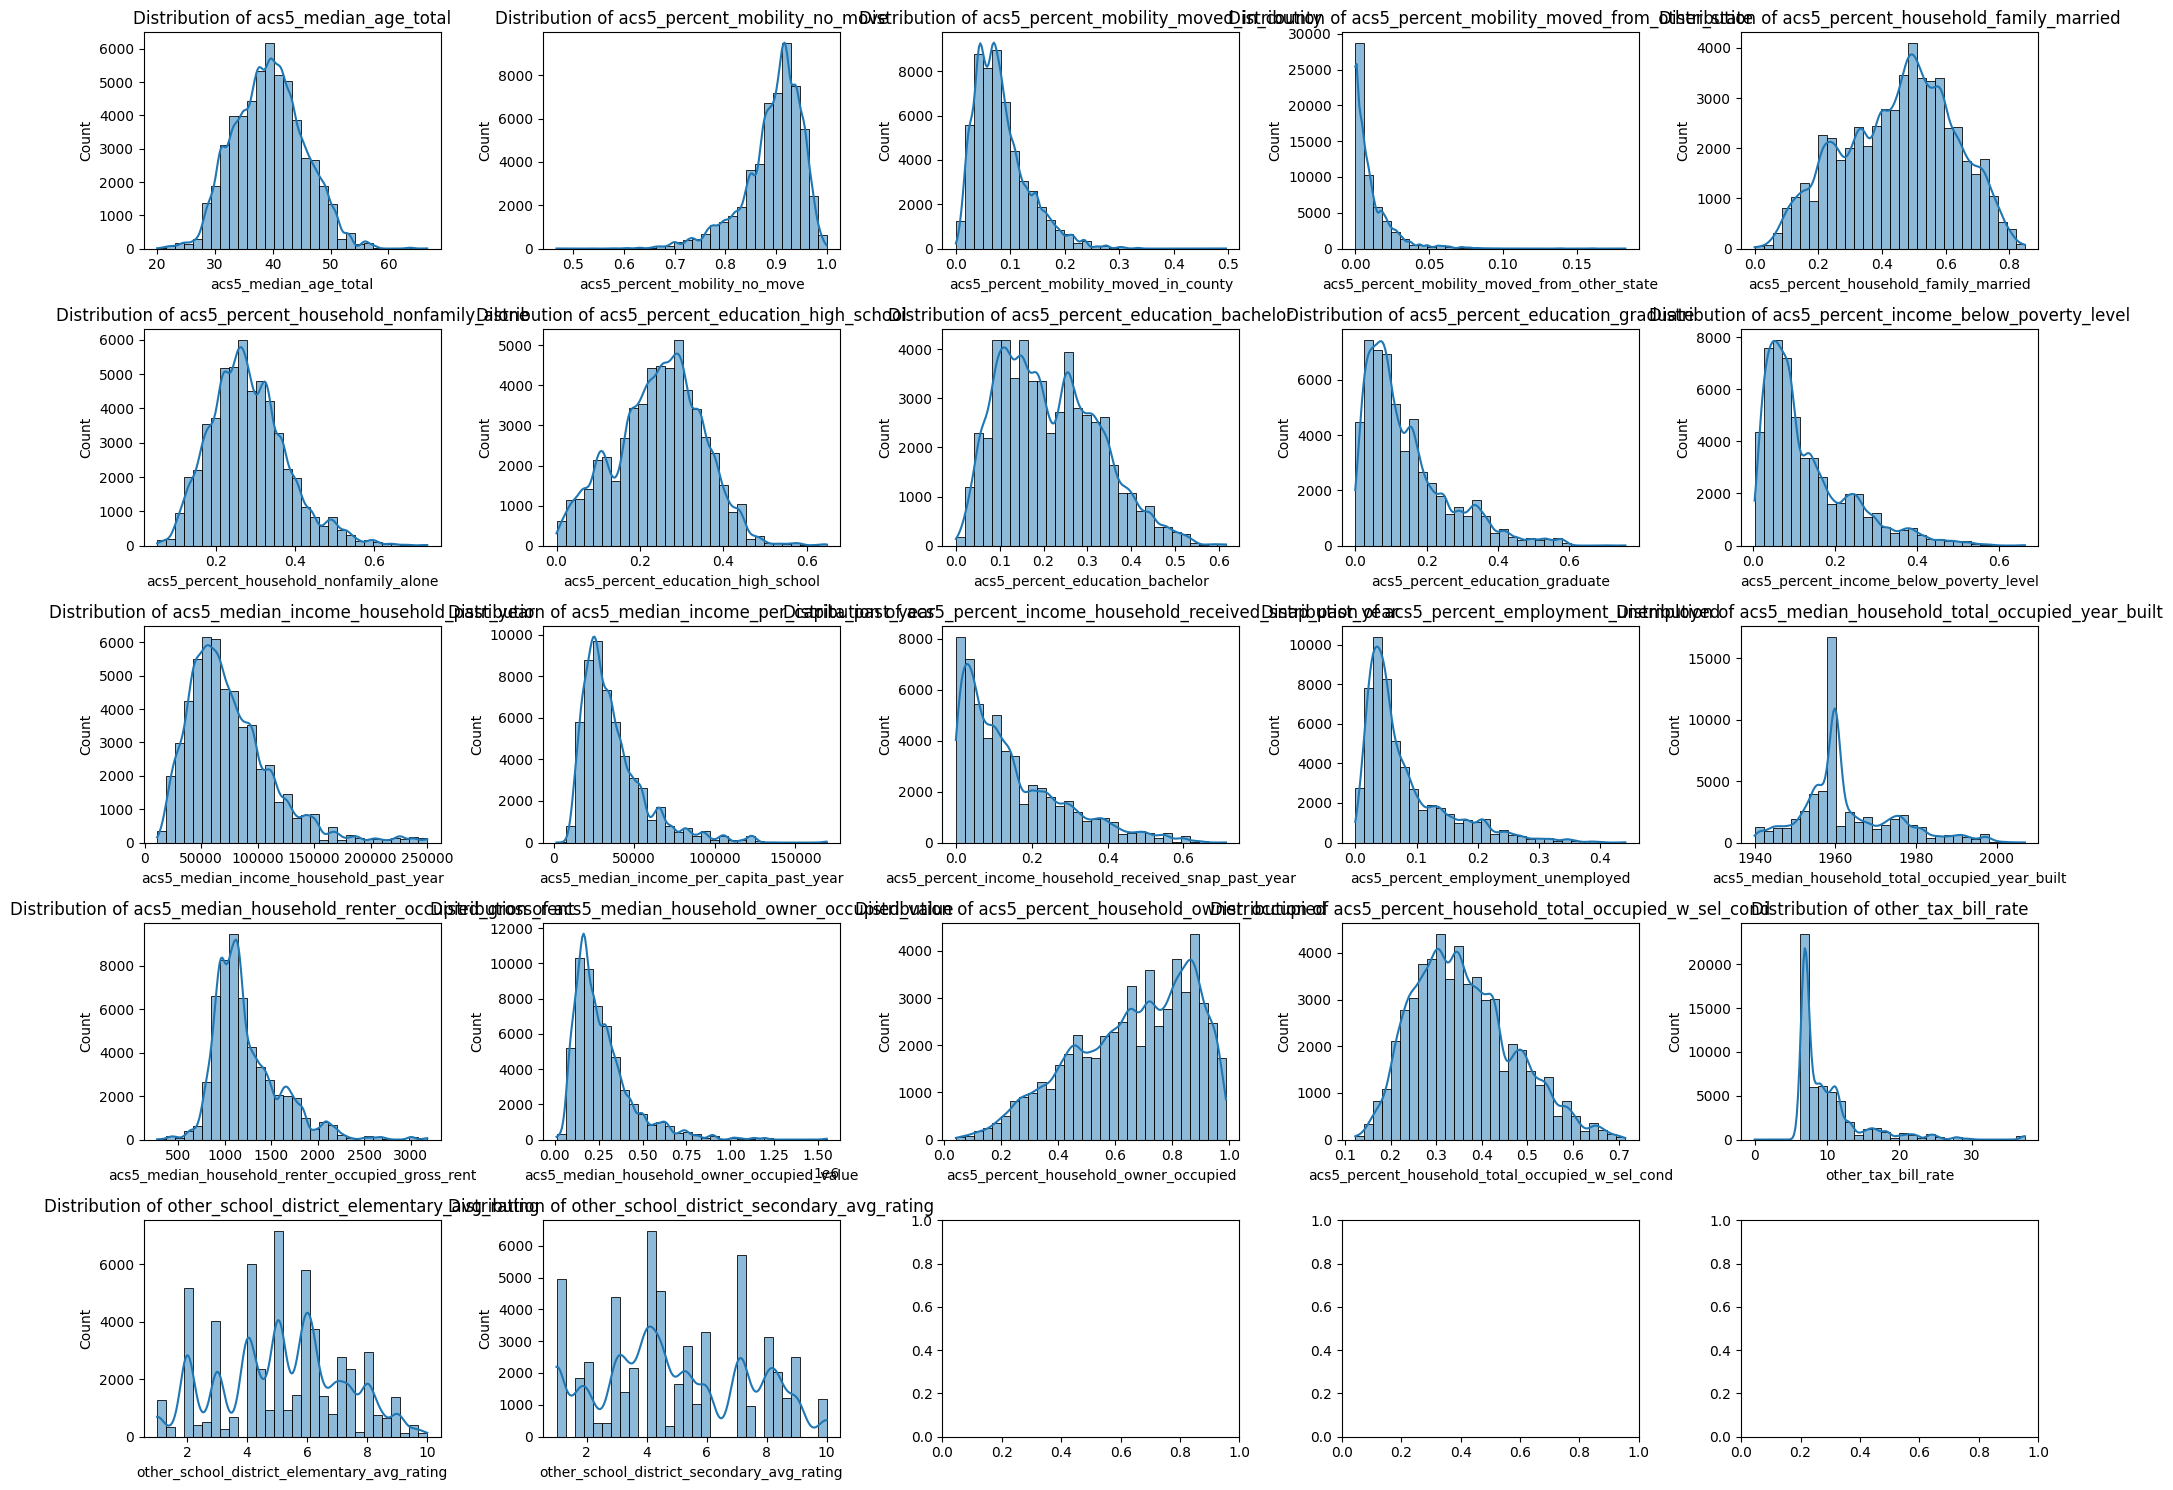

In [43]:
fig, axes = plt.subplots(nrows=5, ncols=5, figsize=(20, 15))
axes = axes.flatten()

for i, col in enumerate(pkg_continuous[30:]):
    sns.histplot(train_data[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

In [44]:
def generate_continuous_outlier_report(df, lower_q=0.01, upper_q=0.99):
    """
    生成连续特征异常值检查的汇总报告 DataFrame
    """
    report_data = []

    for col in df.columns:
        series = df[col].dropna()
        if len(series) == 0:
            continue

        lower_bound = series.quantile(lower_q)
        upper_bound = series.quantile(upper_q)

        below_values = series[series < lower_bound]
        above_values = series[series > upper_bound]

        report_data.append({
            'Feature': col,
            'Valid_Count': len(series),
            'Min_Value': round(series.min(), 4),
            'Max_Value': round(series.max(), 4),
            '1%_Lower_Bound': round(lower_bound, 4),
            '99%_Upper_Bound': round(upper_bound, 4),
            'Count_Below_1%': len(below_values),
            'Count_Above_99%': len(above_values),
            'Total_Outliers': len(below_values) + len(above_values),
            'Outlier_Ratio(%)': round((len(below_values) + len(above_values)) / len(series) * 100, 2),
            # 提取前 3 个最极端的值作为参考
            'Top3_Min_Samples': np.sort(below_values)[:3].tolist(),
            'Top3_Max_Samples': np.sort(above_values)[::-1][:3].tolist()
        })

    return pd.DataFrame(report_data)

# === 使用示例 ===
report_df = generate_continuous_outlier_report(df_continuous)
display(report_df)
report_df.to_csv("continuous_outlier_report.csv", index=False) # 导出查看

,Feature,Valid_Count,Min_Value,Max_Value,1%_Lower_Bound,99%_Upper_Bound,Count_Below_1%,Count_Above_99%,Total_Outliers,Outlier_Ratio(%),Top3_Min_Samples,Top3_Max_Samples
0,loc_longitude,54853,-88.2635,-8.752490e+01,-88.2075,-87.5368,549,549,1098,2.00,"[-88.26350610075501, -88.26333689363103, -88.2631566263013]","[-87.52491910282046, -87.52491910282046, -87.52492250946459]"
1,loc_latitude,54853,41.4699,4.215400e+01,41.4822,42.1407,549,549,1098,2.00,"[41.46992834851476, 41.46997659345463, 41.46998370028336]","[42.15397901114071, 42.15395661600107, 42.15394950860588]"
2,char_yrblt,54853,1851.0000,2.021000e+03,1883.0000,2014.0000,493,433,926,1.69,"[1851.0, 1851.0, 1852.0]","[2021.0, 2021.0, 2021.0]"
3,char_bldg_sf,54853,400.0000,1.980000e+04,720.0000,5880.0000,516,543,1059,1.93,"[400.0, 400.0, 400.0]","[19800.0, 19575.0, 15300.0]"
4,char_land_sf,54853,9.0000,2.363130e+06,1097.0000,38826.8800,548,549,1097,2.00,"[9.0, 358.0, 488.0]","[2363130.0, 2363130.0, 653400.0]"
5,char_beds,54853,1.0000,3.400000e+01,2.0000,10.0000,96,465,561,1.02,"[1.0, 1.0, 1.0]","[34.0, 34.0, 22.0]"
6,char_rooms,54853,2.0000,4.800000e+01,4.0000,22.0000,338,499,837,1.53,"[2.0, 2.0, 3.0]","[48.0, 48.0, 46.0]"
7,loc_env_airport_noise_dnl,54853,49.5349,7.989810e+01,50.8998,67.2733,549,549,1098,2.00,"[49.53487396240234, 49.53657531738281, 49.53836441040039]","[79.89813232421875, 79.78201293945312, 79.42108154296875]"
8,loc_access_cmap_walk_nta_score,54853,-40.0000,1.435000e+02,-7.0000,130.0000,536,442,978,1.78,"[-40.0, -40.0, -40.0]","[143.5, 143.5, 143.5]"
9,loc_access_cmap_walk_total_score,54853,-40.0000,1.525000e+02,-7.0000,138.5000,484,414,898,1.64,"[-40.0, -40.0, -38.0]","[152.5, 152.5, 152.5]"


我们对continuous的数据进行outlier的列示，找出其中极端值与1%和99%分位数值偏离极大的feature进行outlier截断。但对于特殊feature例如时间类的，则不做处理


In [45]:
# 验证loc_access_cmap_walk_nta_score的负值是否有多数为-40的极端情况而代表了不合理的缺失值
print("值小于 -7 的样本数:", (train_data['loc_access_cmap_walk_nta_score'] < -7).sum())
print("值等于 -40 的样本数:", (train_data['loc_access_cmap_walk_nta_score'] == -40).sum())
print("小于 0 但大于 -40 的样本数:", ((train_data['loc_access_cmap_walk_nta_score'] < 0) & (train_data['loc_access_cmap_walk_nta_score'] > -40.0)).sum())

值小于 -7 的样本数: 536
值等于 -40 的样本数: 3
小于 0 但大于 -40 的样本数: 2183


In [46]:
# 验证other_tax_bill_rate的负值是否有多数为-40的极端情况而代表了不合理的缺失值
print("值小于 6 的样本数:", (train_data['other_tax_bill_rate'] < 6).sum())
print("值等于 0 的样本数:", (train_data['other_tax_bill_rate'] == 0).sum())
print("小于 6 但大于 0 的样本数:", ((train_data['other_tax_bill_rate'] < 6) & (train_data['other_tax_bill_rate'] > 0)).sum())

值小于 6 的样本数: 4
值等于 0 的样本数: 3
小于 6 但大于 0 的样本数: 1



通过分析上面的直方图、极端值，结合实际场景，我们配置额外的csv文件，在其中列示了不同feature所归类的特征工程处理方式，来进行统一转换

In [47]:
from sklearn.preprocessing import PowerTransformer, StandardScaler

rule_df = pd.read_csv('/content/drive/MyDrive/Data/featureengineer.csv')

# 将各列去除空格并过滤掉空值、转换为列表。这里去重以应对拼写重复。
def get_cols(col_name):
    if col_name not in rule_df.columns:
        return []
    # dropna() 去除空值，astype(str).str.strip() 去除空格，unique() 去重
    return rule_df[col_name].dropna().astype(str).str.strip().unique().tolist()

# 因为 'yeojohnson' 和 'standardscaler' 列的名字如果与代码有冲突，直接用列名提取
cols_yeojohnson = get_cols('yeojohnson')
cols_scaler = get_cols('standardscaler')
cols_clipping = get_cols('clipping')
cols_binning = get_cols('binning')
cols_remain = get_cols('remain')

# 考虑到处理顺序①②③要求对“所有涉及 clipping/yeojohnson/scaler”的特征一视同仁，
# 我们取这三者的并集作为需要连续处理的列（正如之前的逻辑）。
# 注意过滤掉不在 train_data 中的特征。
continuous_cols = list(set(cols_yeojohnson + cols_scaler + cols_clipping))
continuous_cols = [c for c in continuous_cols if c in train_data.columns]

print(f"解析结果：")
print(f"连续处理组(①②③)特征数: {len(continuous_cols)}")
print(f"分箱组(④)特征数: {len(cols_binning)}")
print(f"保持不变(⑤)特征数: {len(cols_remain)}")


# ==========================================
# 1. 连续特征：① Clipping -> ② Yeo-Johnson -> ③ StandardScaler
# ==========================================
print("\n开始处理连续型特征...")

# ① 计算训练集的 1% 和 99% 分位数（防止数据泄露，必须在训练集上计算）
clip_bounds = {}
for col in continuous_cols:
    lower = train_data[col].quantile(0.01)
    upper = train_data[col].quantile(0.99)
    clip_bounds[col] = (lower, upper)

# ② 提取并 Clip 训练集，用于 Fit PowerTransformer 和 StandardScaler
train_clipped = train_data[continuous_cols].copy()
for col in continuous_cols:
    lower, upper = clip_bounds[col]
    train_clipped[col] = train_clipped[col].clip(lower, upper)

# Fit 转换器
pt = PowerTransformer(method='yeo-johnson')
scaler = StandardScaler()

train_pt = pt.fit_transform(train_clipped)
scaler.fit(train_pt)

# 应用到三个数据集
for df in [train_data, val_data, test_data]:
    df_clipped = df[continuous_cols].copy()

    # 执行 Clipping
    for col in continuous_cols:
        lower, upper = clip_bounds[col]
        df_clipped[col] = df_clipped[col].clip(lower, upper)

    # 执行 Yeo-Johnson
    df_pt = pt.transform(df_clipped)

    # 执行 StandardScaler
    df_scaled = scaler.transform(df_pt)

    # 覆盖回原数据
    df[continuous_cols] = df_scaled

print("✅ 连续特征处理完成！")

解析结果：
连续处理组(①②③)特征数: 44
分箱组(④)特征数: 6
保持不变(⑤)特征数: 2

开始处理连续型特征...
✅ 连续特征处理完成！


In [48]:
print("\n开始处理分箱特征...")

# 分箱逻辑函数
def apply_binning(df, binning_list):
    df_bin = df.copy()

    if 'char_beds' in binning_list and 'char_beds' in df_bin.columns:
        # 1卧、2卧、3卧、4卧、5卧及以上 (共计5个标签)
        df_bin['char_beds_bin'] = df_bin['char_beds'].clip(lower=1, upper=5).fillna(1).astype(int)

    if 'char_rooms' in binning_list and 'char_rooms' in df_bin.columns:
        # 0-9间，10间及以上 (共计11个标签)
        df_bin['char_rooms_bin'] = df_bin['char_rooms'].clip(lower=0, upper=10).fillna(0).astype(int)

    if 'prox_num_school_in_half_mile' in binning_list and 'prox_num_school_in_half_mile' in df_bin.columns:
        # 0-9间，10间及以上 (共计11个标签)
        df_bin['prox_num_school_bin'] = df_bin['prox_num_school_in_half_mile'].clip(lower=0, upper=10).fillna(0).astype(int)

    if 'prox_avg_school_rating_in_half_mile' in binning_list and 'prox_avg_school_rating_in_half_mile' in df_bin.columns:
        # 四舍五入，1-10，10个标签
        rounded = df_bin['prox_avg_school_rating_in_half_mile'].round()
        df_bin['prox_avg_school_rating_bin'] = rounded.clip(lower=1, upper=10).fillna(1).astype(int)

    if 'other_school_district_elementary_avg_rating' in binning_list and 'other_school_district_elementary_avg_rating' in df_bin.columns:
        # 四舍五入，1-10，10个标签
        rounded = df_bin['other_school_district_elementary_avg_rating'].round()
        df_bin['other_elementary_rating_bin'] = rounded.clip(lower=1, upper=10).fillna(1).astype(int)

    if 'other_school_district_secondary_avg_rating' in binning_list and 'other_school_district_secondary_avg_rating' in df_bin.columns:
        # 四舍五入，1-10，10个标签
        rounded = df_bin['other_school_district_secondary_avg_rating'].round()
        df_bin['other_secondary_rating_bin'] = rounded.clip(lower=1, upper=10).fillna(1).astype(int)

    return df_bin

# 应用分箱
train_data = apply_binning(train_data, cols_binning)
val_data = apply_binning(val_data, cols_binning)
test_data = apply_binning(test_data, cols_binning)

# 找出新生成的分箱列名
bin_col_names = [
    'char_beds_bin', 'char_rooms_bin', 'prox_num_school_bin',
    'prox_avg_school_rating_bin', 'other_elementary_rating_bin', 'other_secondary_rating_bin'
]
# 过滤出真实存在的
bin_col_names = [c for c in bin_col_names if c in train_data.columns]

# 为了对齐 One-Hot 列数，先合并再做 dummies
train_len = len(train_data)
val_len = len(val_data)

combined_df = pd.concat([train_data, val_data, test_data], axis=0, ignore_index=True)

# 执行 One-Hot (drop_first=True 去掉每个特征的第一个类别作为基准)
combined_df = pd.get_dummies(combined_df, columns=bin_col_names, drop_first=True)

# 将布尔型 0/1 转为整数型
bool_cols = combined_df.select_dtypes(include=['bool']).columns
combined_df[bool_cols] = combined_df[bool_cols].astype(int)

# 拆回三个数据集
train_data = combined_df.iloc[:train_len].copy()
val_data = combined_df.iloc[train_len:train_len+val_len].copy()
test_data = combined_df.iloc[train_len+val_len:].copy()

# 清理原数据集中对应的原始连续分箱列
original_binning_cols = [c for c in cols_binning if c in train_data.columns]
for df in [train_data, val_data, test_data]:
    df.drop(columns=original_binning_cols, inplace=True, errors='ignore')

print(f"✅ 分箱与 One-Hot 处理完成！生成了 {len([c for c in train_data.columns if any(bc in c for bc in bin_col_names)])} 个 One-Hot 特征。")
print(f"\n最终数据维度: Train={train_data.shape}, Val={val_data.shape}, Test={test_data.shape}")


开始处理分箱特征...
✅ 分箱与 One-Hot 处理完成！生成了 49 个 One-Hot 特征。

最终数据维度: Train=(54853, 163), Val=(18132, 163), Test=(36322, 163)


对于以上数据特征中，

接下来，对discrete类别的特征包进行EDA分析，使用柱状图和箱型图

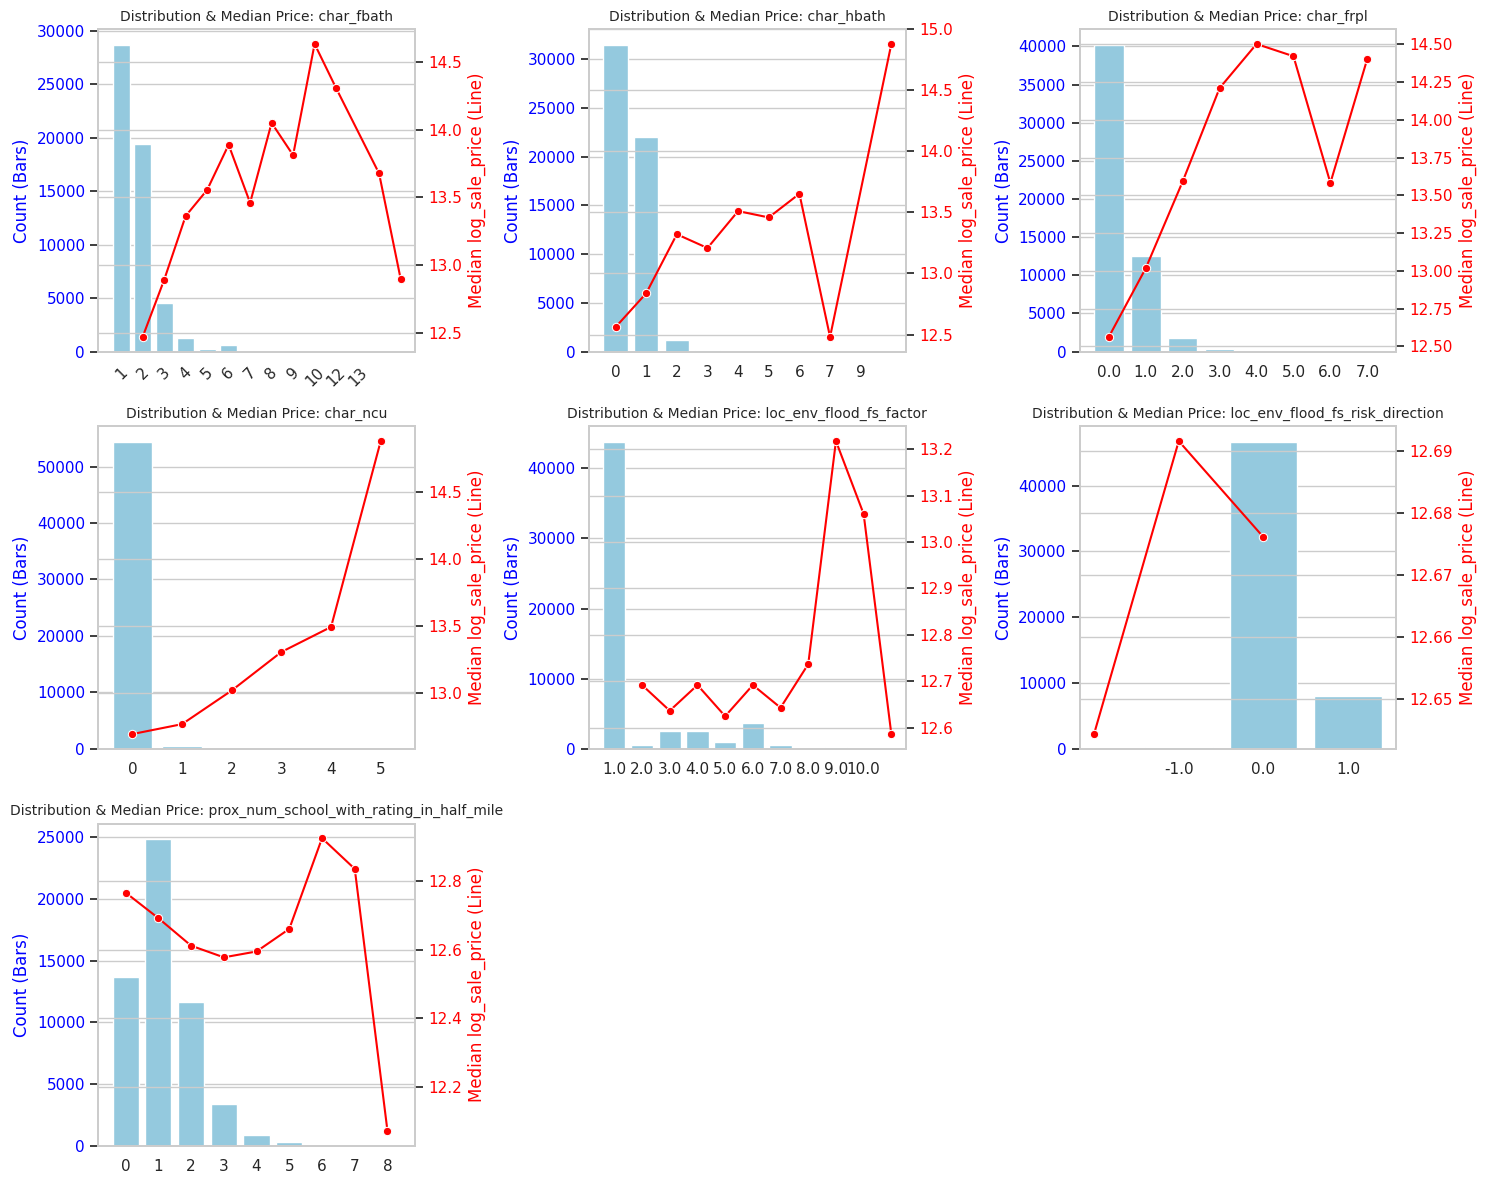

In [49]:
sns.set_theme(style="whitegrid")

if len(pkg_discrete) > 0:
    # 计算需要的行数和列数（最多每排显示 3 个图）
    n_cols = 3
    n_rows = math.ceil(len(pkg_discrete) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(pkg_discrete):
        # 1. 画频数柱状图（使用蓝色表示频数）
        ax1 = axes[i]
        sns.countplot(data=train_data, x=col, ax=ax1, color='skyblue')

        # 2. 将双轴图放在同一个子图里（用 twinx 共享 X 轴）
        ax2 = ax1.twinx()
        # 计算该特征每个取值对应的房价中位数
        median_price = train_data.groupby(col)['log_sale_price'].median().reset_index()
        # 画折线图（使用红色圆点表示房价中位数趋势）
        sns.lineplot(data=median_price, x=col, y='log_sale_price',
                     ax=ax2, color='red', marker='o', sort=False)

        # 3. 设置标题和坐标轴
        ax1.set_title(f'Distribution & Median Price: {col}', fontsize=10)
        ax1.set_xlabel('')
        ax1.set_ylabel('Count (Bars)', color='blue')
        ax2.set_ylabel('Median log_sale_price (Line)', color='red')
        ax1.tick_params(axis='y', labelcolor='blue')
        ax2.tick_params(axis='y', labelcolor='red')

        # 优化 X 轴刻度：如果取值太多，只显示部分刻度，防止重叠
        if len(train_data[col].unique()) > 10:
            for label in ax1.get_xticklabels():
                label.set_rotation(45)

    # 隐藏多余的空子图
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()
else:
    print("当前没有离散型 (Discrete) 特征。")

In [50]:
# char_fbath: 截断极端值，保留到 3
for df in [train_data, val_data, test_data]:
    if 'char_fbath' in df.columns:
        df['char_fbath'] = df['char_fbath'].clip(upper=3).astype('Int64')

# char_hbath: 截断极端值，保留到 2
for df in [train_data, val_data, test_data]:
    if 'char_hbath' in df.columns:
        df['char_hbath'] = df['char_hbath'].clip(upper=2).astype('Int64')

# char_ncu: 截断极端值，保留到 2
for df in [train_data, val_data, test_data]:
    if 'char_ncu' in df.columns:
        df['char_ncu'] = df['char_ncu'].clip(upper=2).astype('Int64')

# prox_num_school_with_rating_in_half_mile: 截断极端值，保留到 3
for df in [train_data, val_data, test_data]:
    if 'prox_num_school_with_rating_in_half_mile' in df.columns:
        df['prox_num_school_with_rating_in_half_mile'] = df['prox_num_school_with_rating_in_half_mile'].clip(upper=3).astype('Int64')

# ==========================================
# 2. 二值化 (Binarization) —— 处理"0占绝大多数"的特征
# ==========================================

# char_frpl: 转换为是否有壁炉 (0=无, 1=有)
for df in [train_data, val_data, test_data]:
    if 'char_frpl' in df.columns:
        df['char_frpl'] = (df['char_frpl'] > 0).astype('Int64')

# ==========================================
# 3. 洪水相关特征 (保持原样，仅做类型安全性确认)
# ==========================================
# 这两个特征由于极度偏态（几乎全为0），无需改动，树模型可以直接处理
# 只要确保是 float 或 Int 即可
for df in [train_data, val_data, test_data]:
    if 'loc_env_flood_fs_factor' in df.columns:
        df['loc_env_flood_fs_factor'] = pd.to_numeric(df['loc_env_flood_fs_factor'], errors='coerce').astype('float64')
    if 'loc_env_flood_fs_risk_direction' in df.columns:
        df['loc_env_flood_fs_risk_direction'] = pd.to_numeric(df['loc_env_flood_fs_risk_direction'], errors='coerce').astype('float64')

print("✅ pkg_discrete 特征工程转换完成！")

✅ pkg_discrete 特征工程转换完成！


下面观测boolean类别的特征包，使用箱型图

/tmp/ipykernel_30901/2889100940.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_data, x=col, y='log_sale_price', ax=ax,
/tmp/ipykernel_30901/2889100940.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_data, x=col, y='log_sale_price', ax=ax,
/tmp/ipykernel_30901/2889100940.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_data, x=col, y='log_sale_price', ax=ax,
/tmp/ipykernel_30901/2889100940.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0

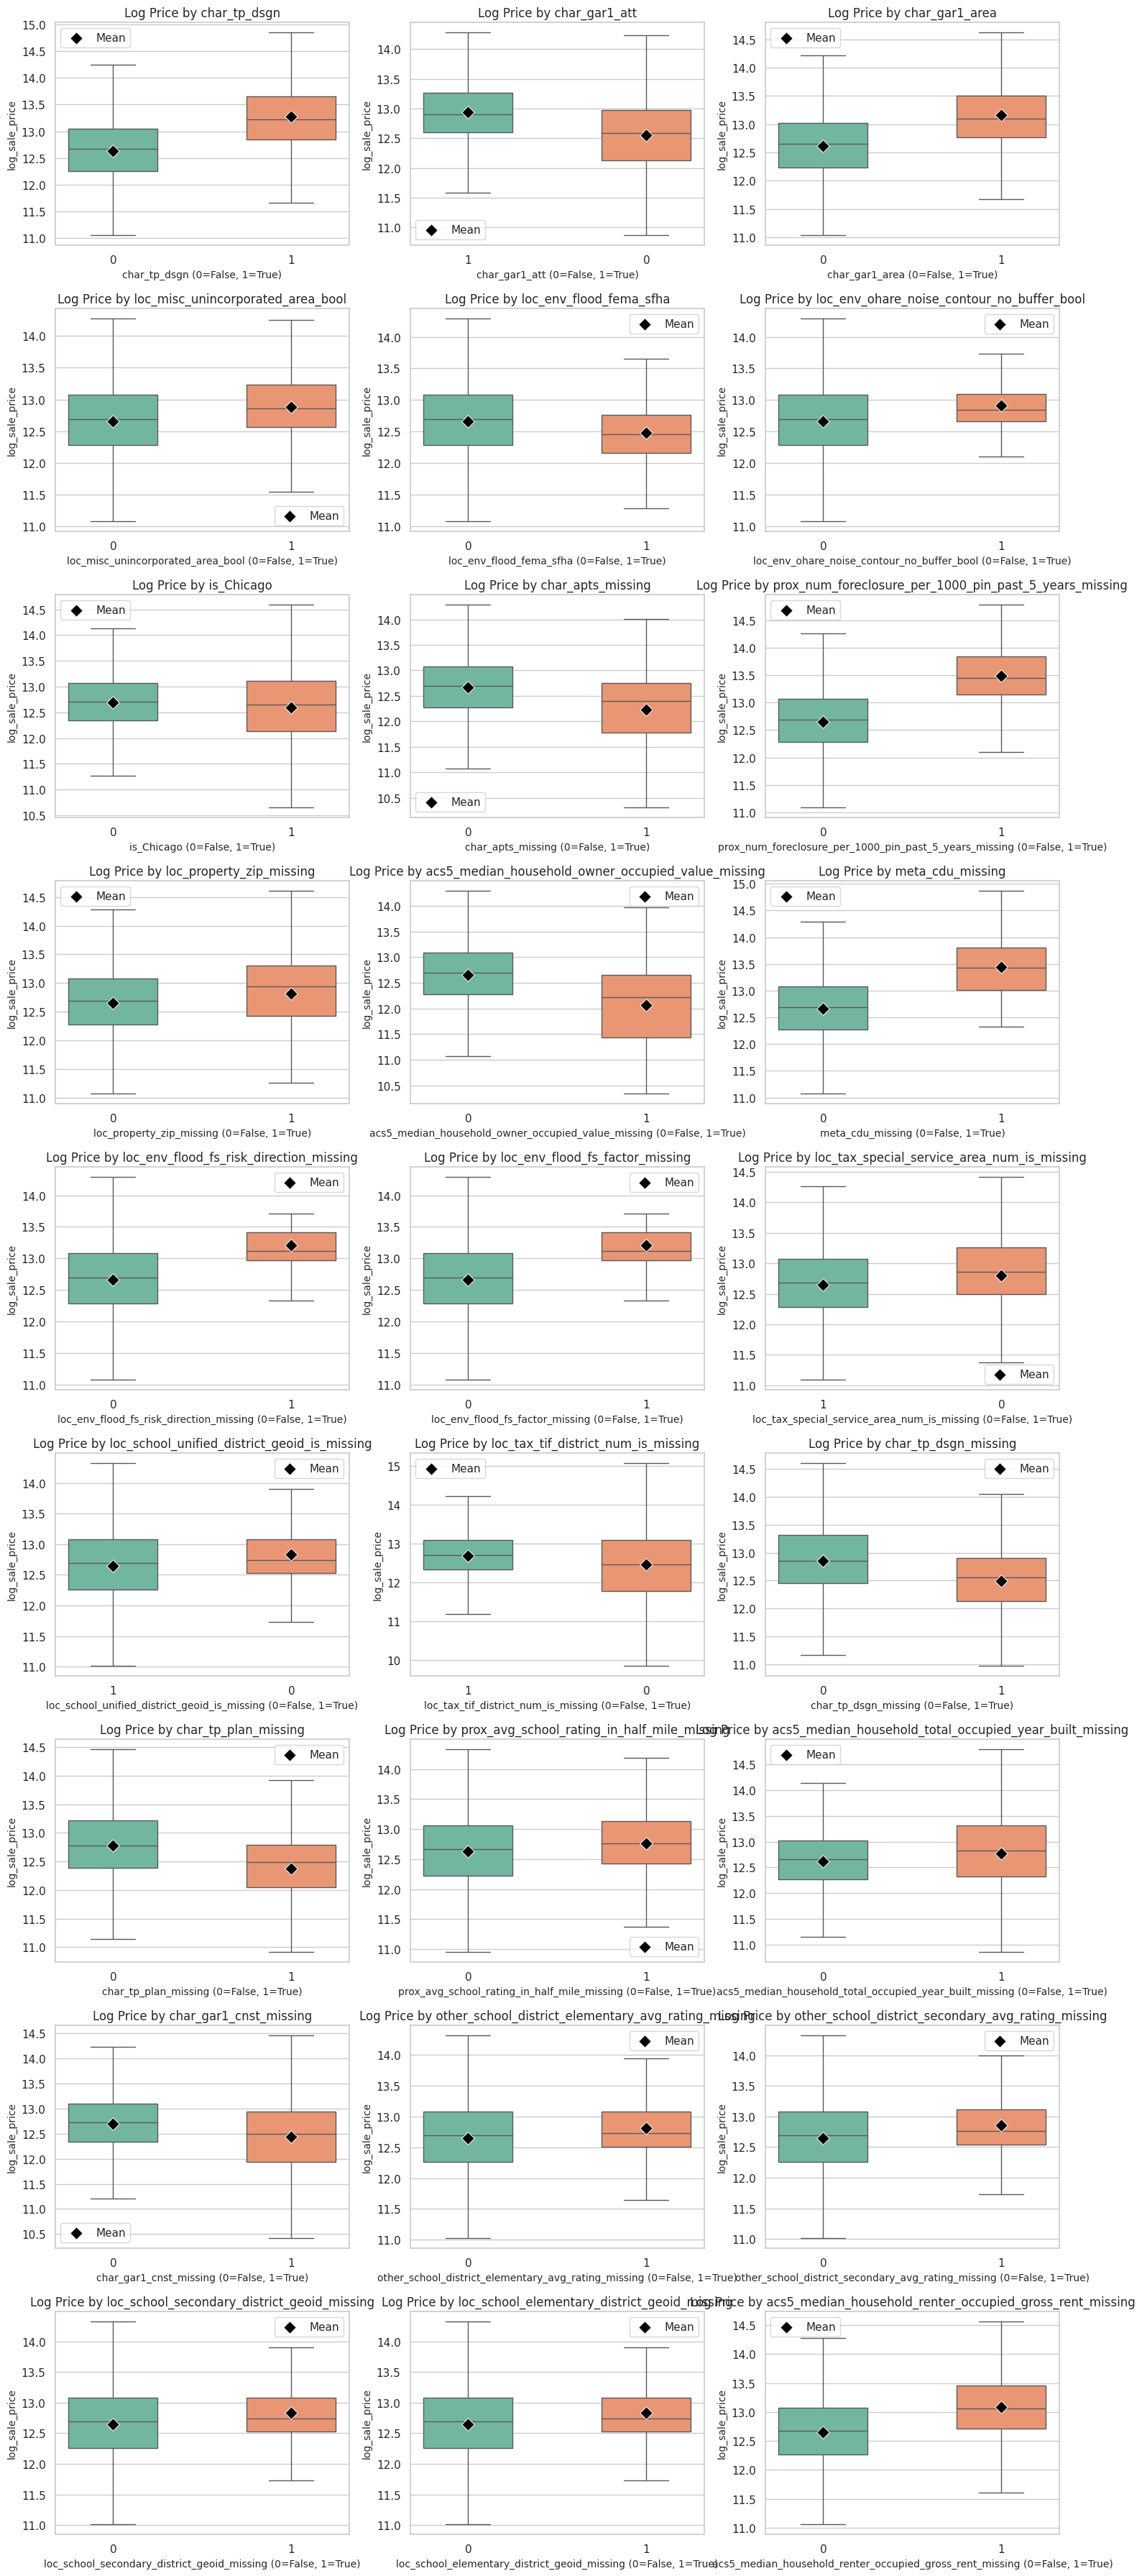

In [51]:
if len(pkg_boolean) > 0:
    n_cols = 3
    n_rows = math.ceil(len(pkg_boolean) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(pkg_boolean):
        ax = axes[i]

        # 1. 将 Boolean 列临时转回 string 或 object 以保证 Seaborn 能正确识别为离散类别
        # 如果你的列是 category 类型，Seaborn 有时会犯傻
        plot_data = train_data[[col, 'log_sale_price']].copy()
        plot_data[col] = plot_data[col].astype(str)

        # 2. 画箱线图
        sns.boxplot(data=plot_data, x=col, y='log_sale_price', ax=ax,
                    palette="Set2", width=0.5, showfliers=False) # showfliers=False 隐藏极端异常值，让图更干净

        # 3. 计算均值
        means = plot_data.groupby(col, observed=True)['log_sale_price'].mean().reset_index()

        # 4. 画均值点（不用 pointplot，改用 scatter 画散点，绝对不报错）
        sns.scatterplot(data=means, x=col, y='log_sale_price', ax=ax,
                        color='black', marker='D', s=80, zorder=5, label='Mean')

        ax.set_title(f'Log Price by {col}', fontsize=12)
        ax.set_xlabel(f'{col} (0=False, 1=True)', fontsize=10)
        ax.set_ylabel('log_sale_price', fontsize=10)
        ax.legend(loc='best')

    # 隐藏多余的空子图
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()
else:
    print("当前没有布尔型 (Boolean) 特征。")

In [52]:
cat_dtypes = train_data[pkg_category].dtypes

# 筛出实际类型为 float 的列
float_in_cat = cat_dtypes[cat_dtypes == 'float64'].index.tolist()
# 如果包含 float32 等其他浮点型
float_in_cat = cat_dtypes[cat_dtypes.apply(lambda x: pd.api.types.is_float_dtype(x))].index.tolist()

if float_in_cat:
    print(f"⚠️ 发现 {len(float_in_cat)} 个原本属于 float 类型的列混入了 Category 包：")
    for col in float_in_cat:
        print(f"  - {col}: dtype={train_data[col].dtype}")
else:
    print("✅ pkg_category 中没有直接的 float dtype 列。")

✅ pkg_category 中没有直接的 float dtype 列。


正在生成各特征的分布与价格关系图...


/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


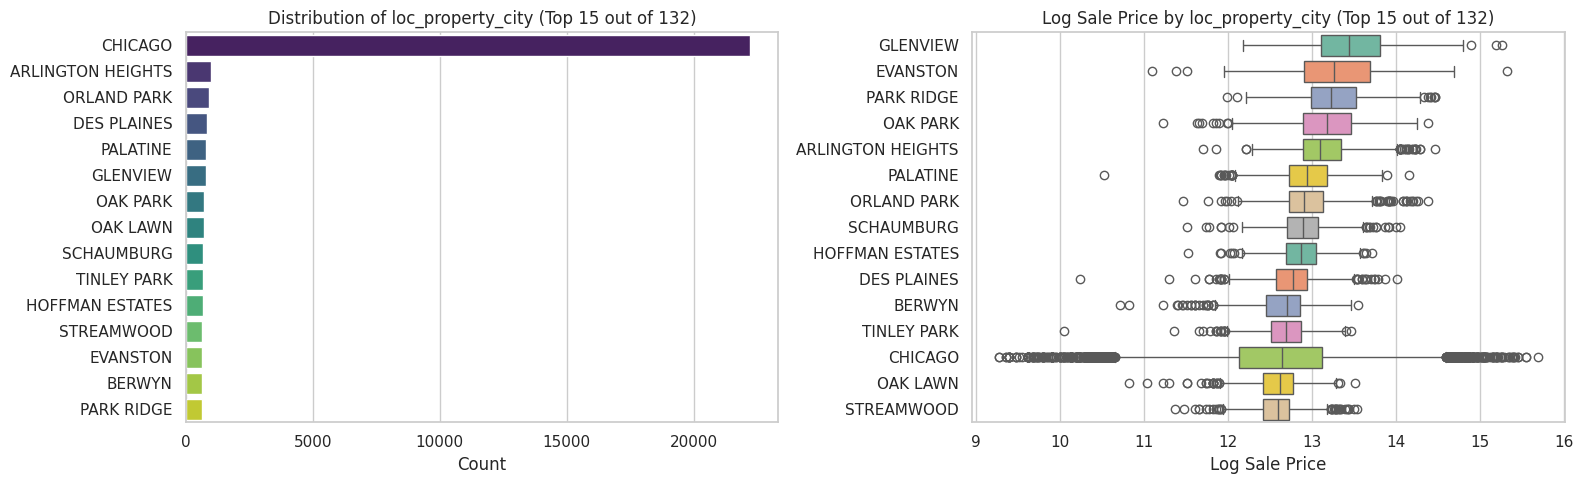

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


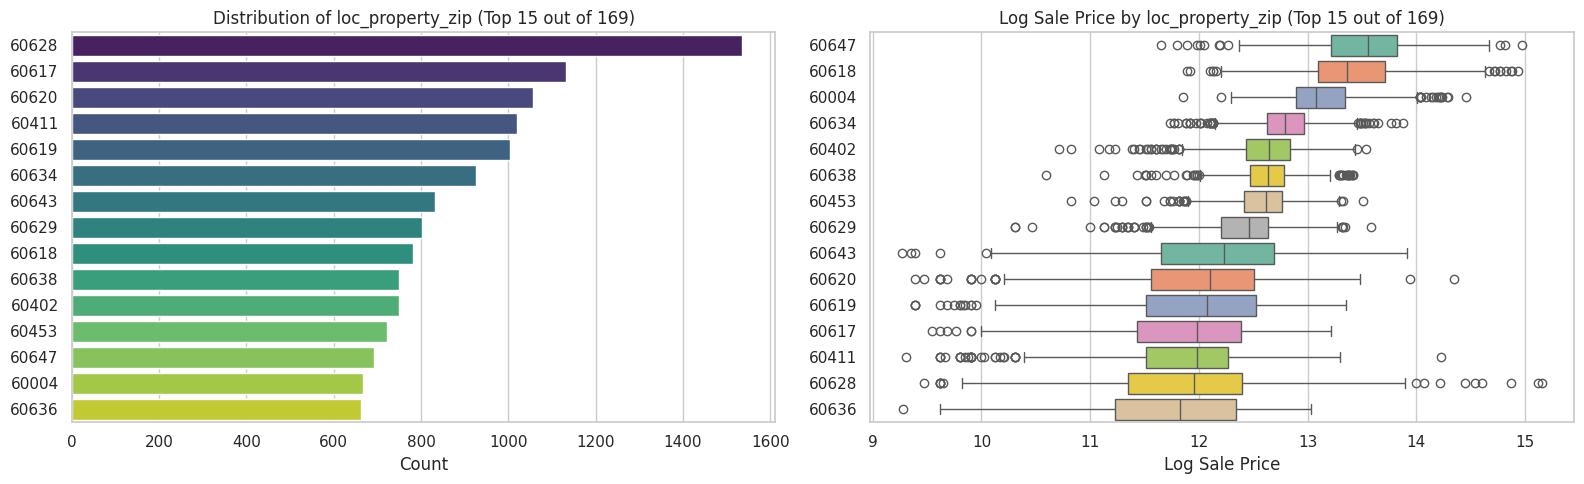

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


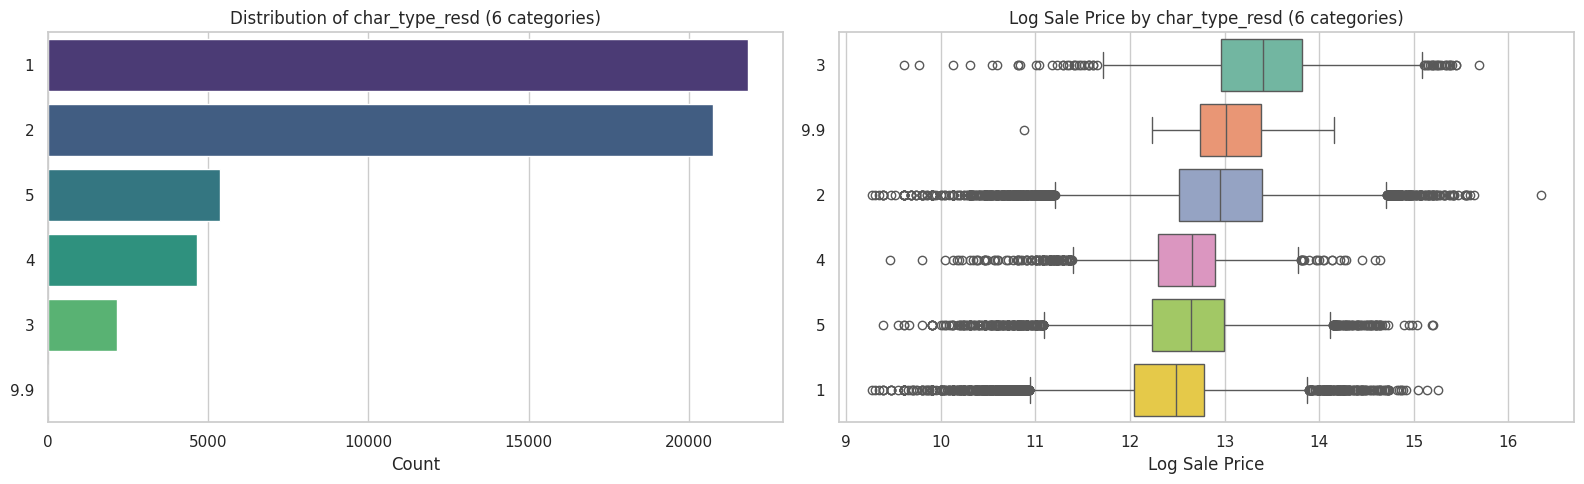

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


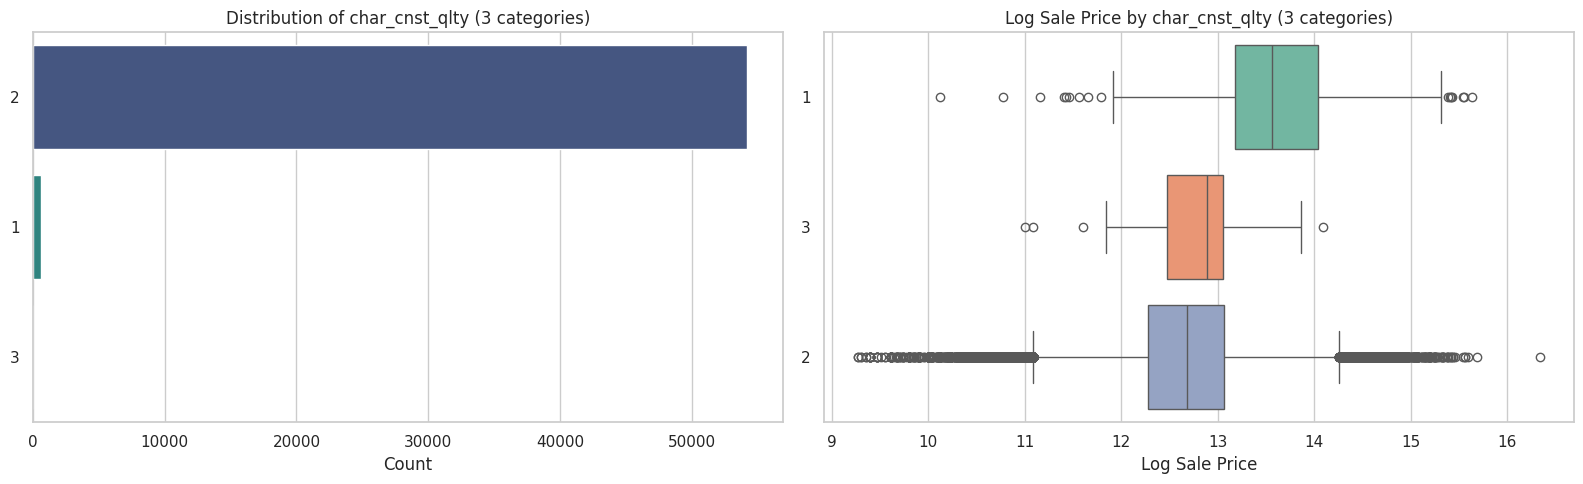

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


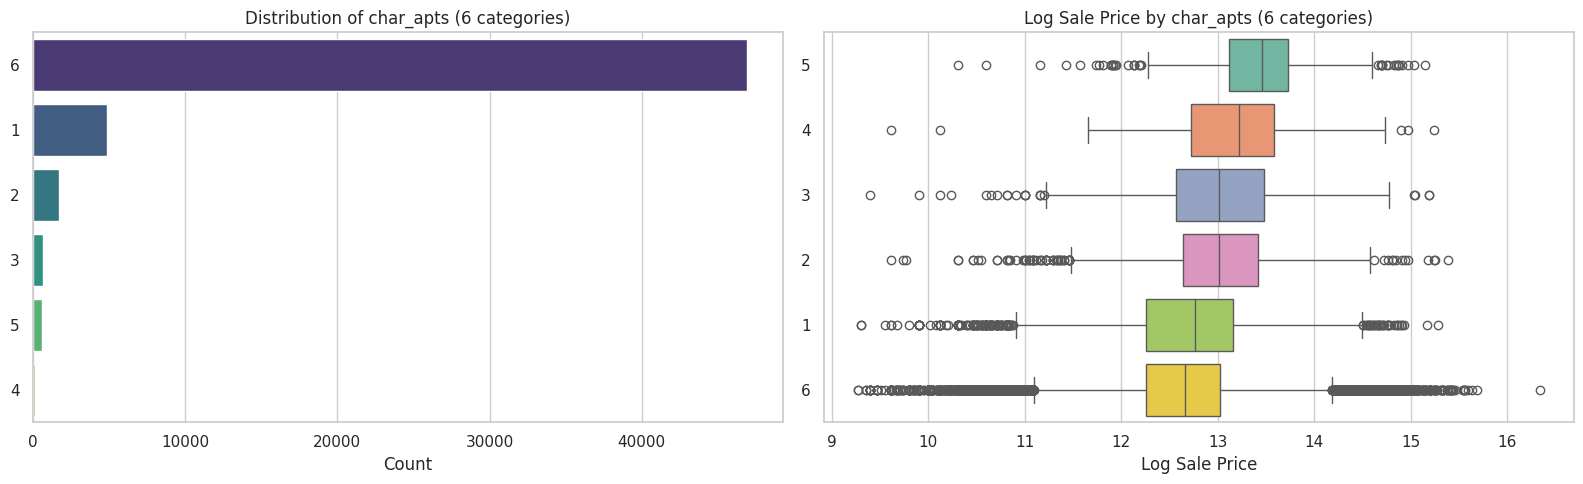

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


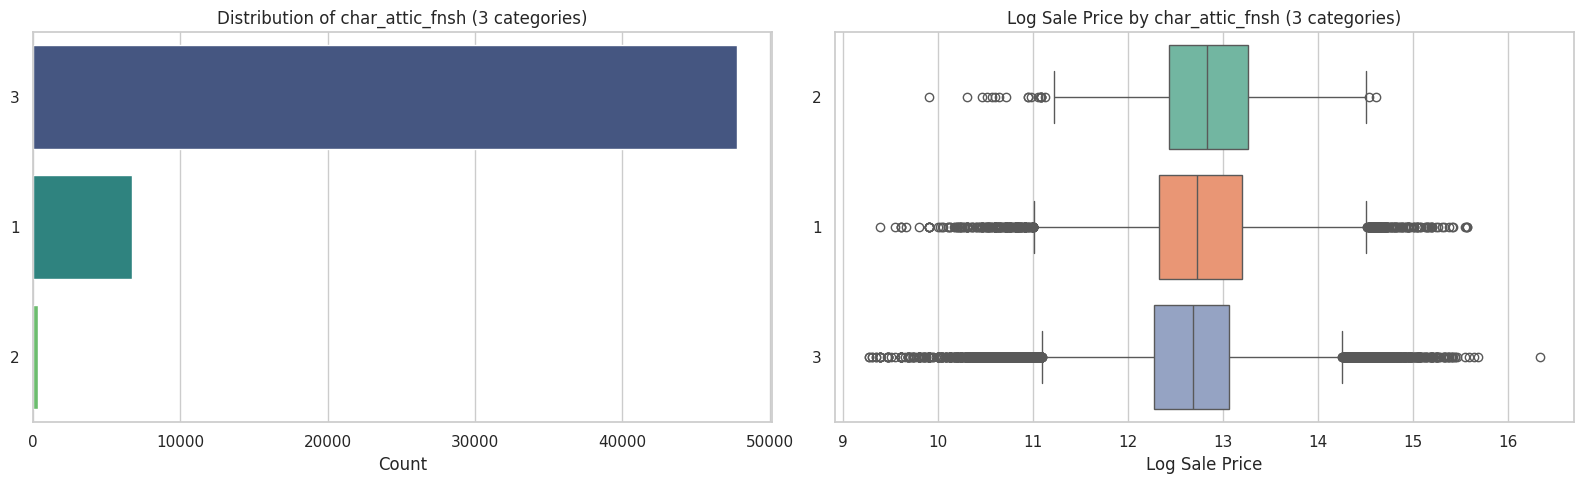

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


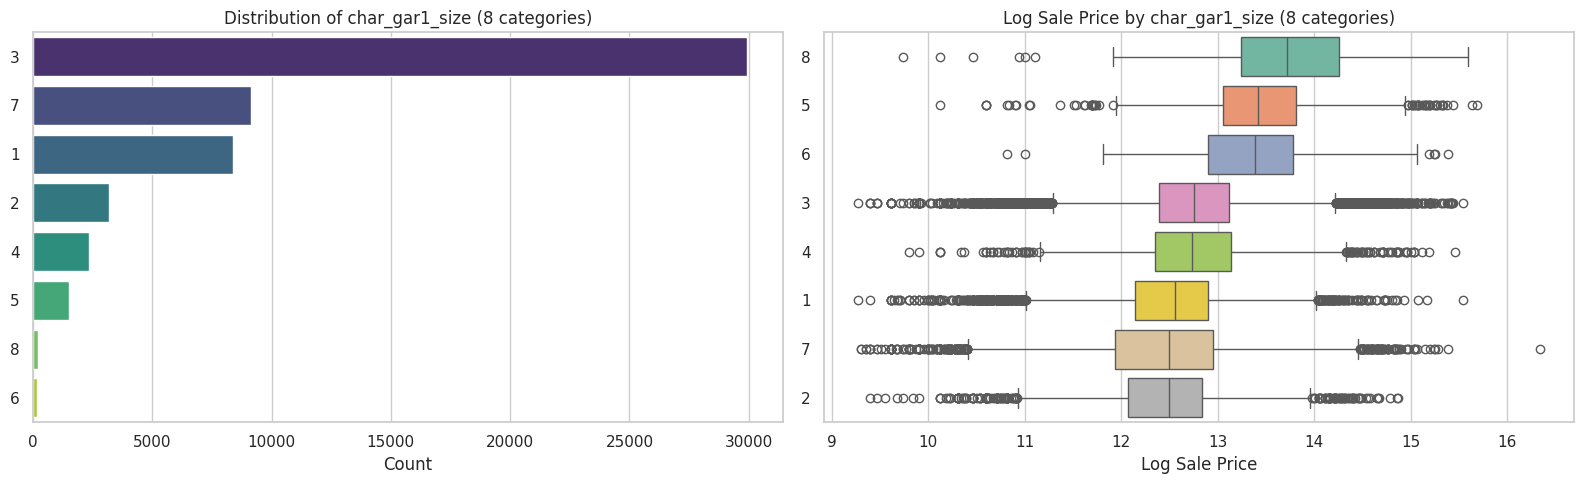

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


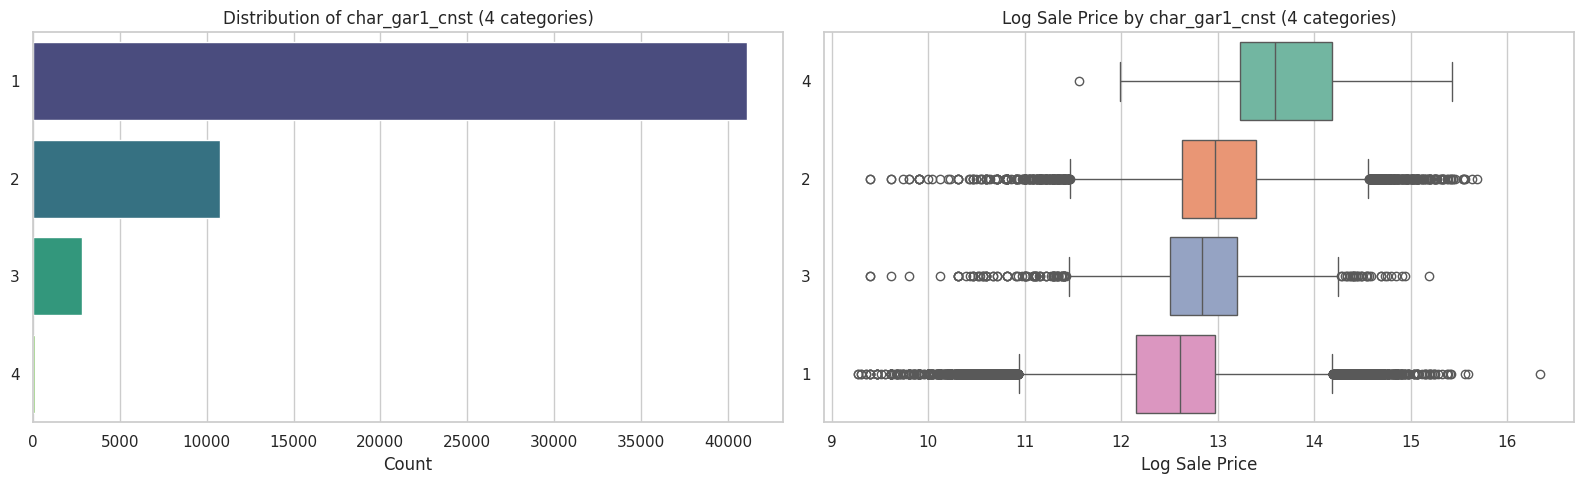

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


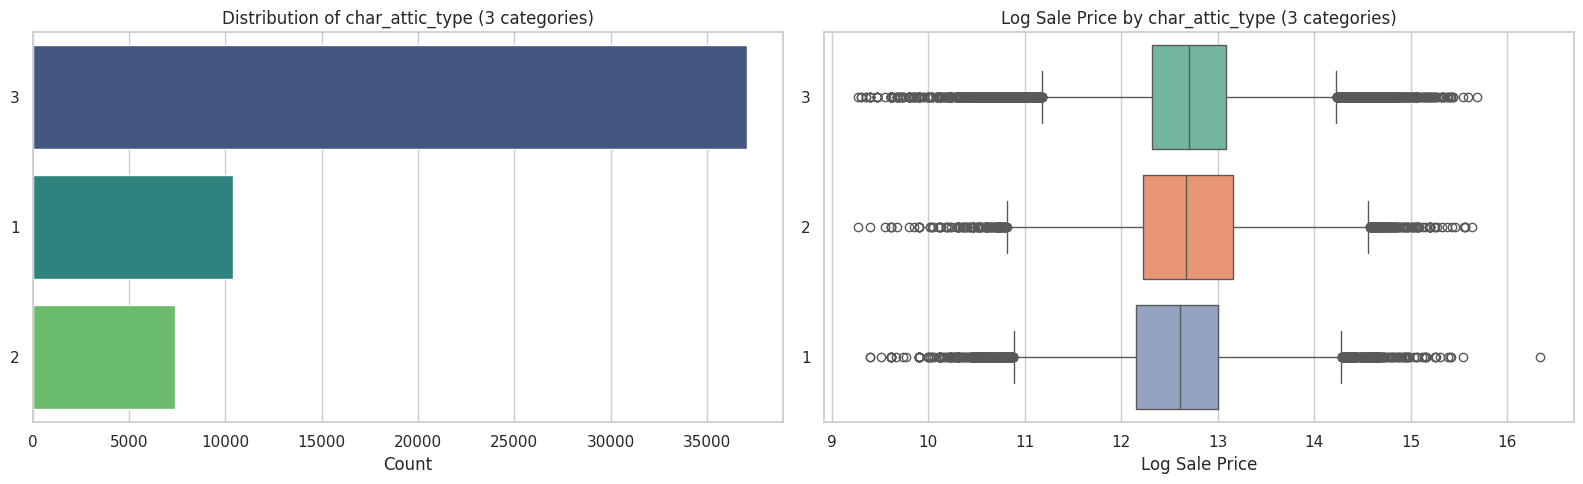

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


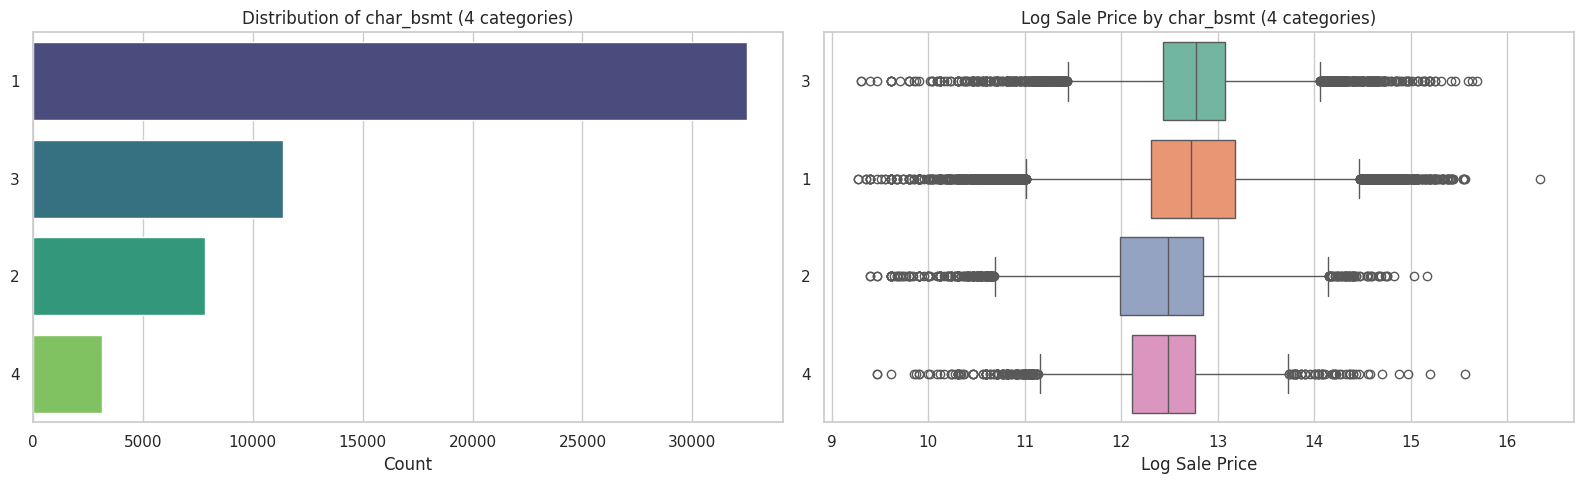

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


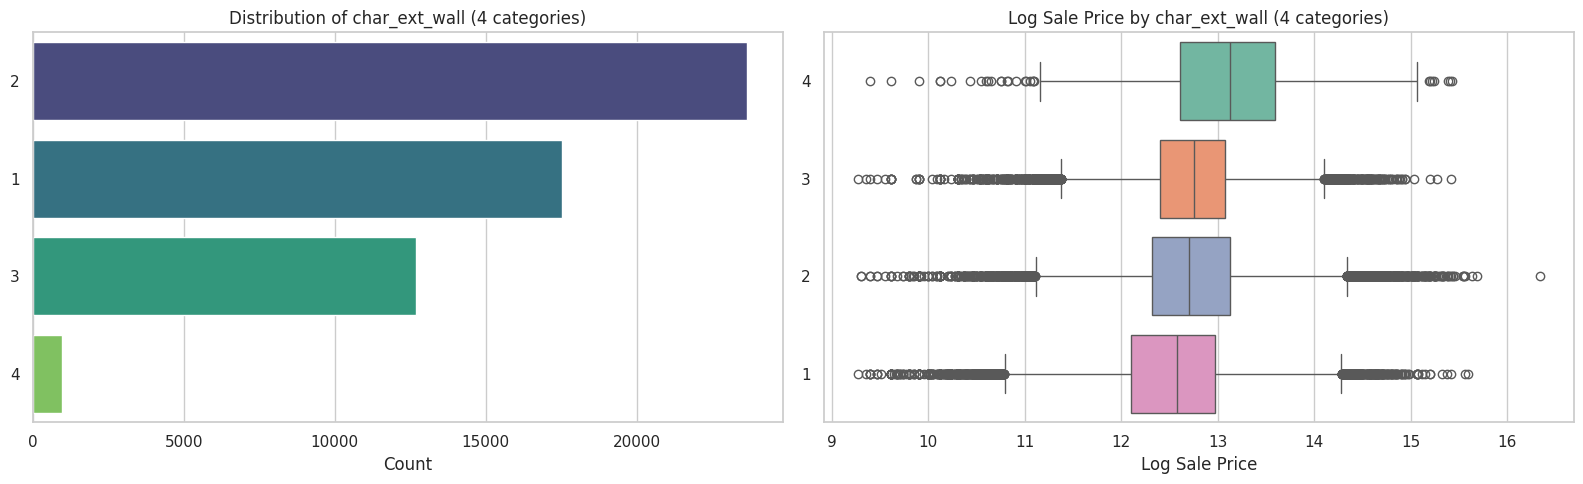

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


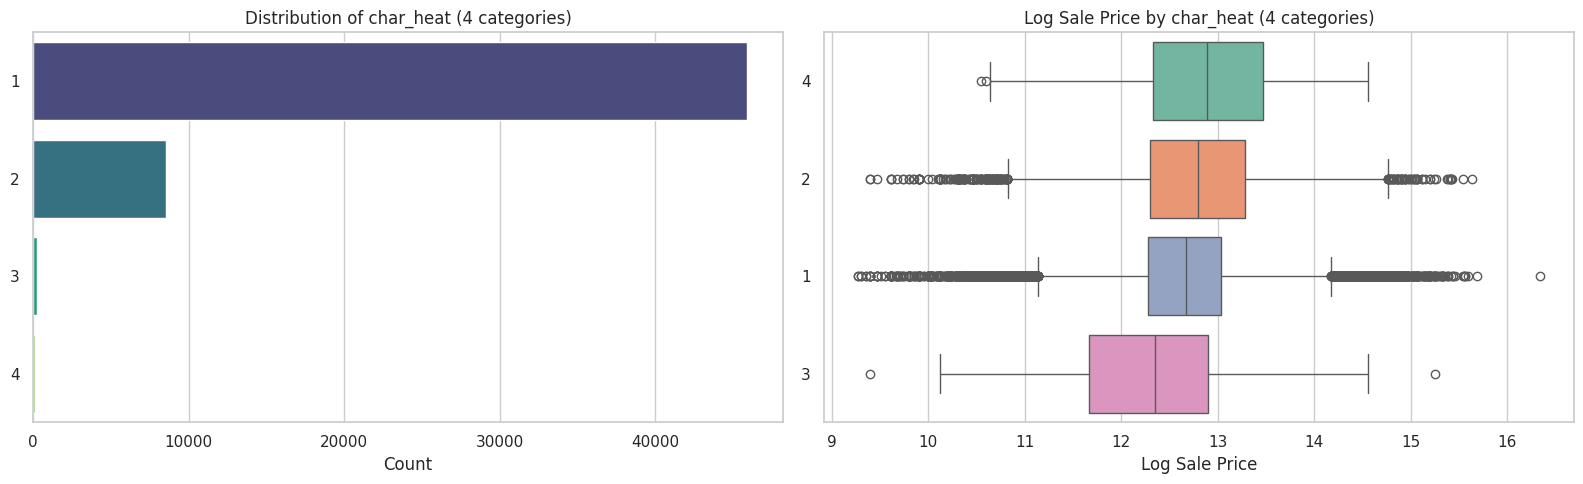

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


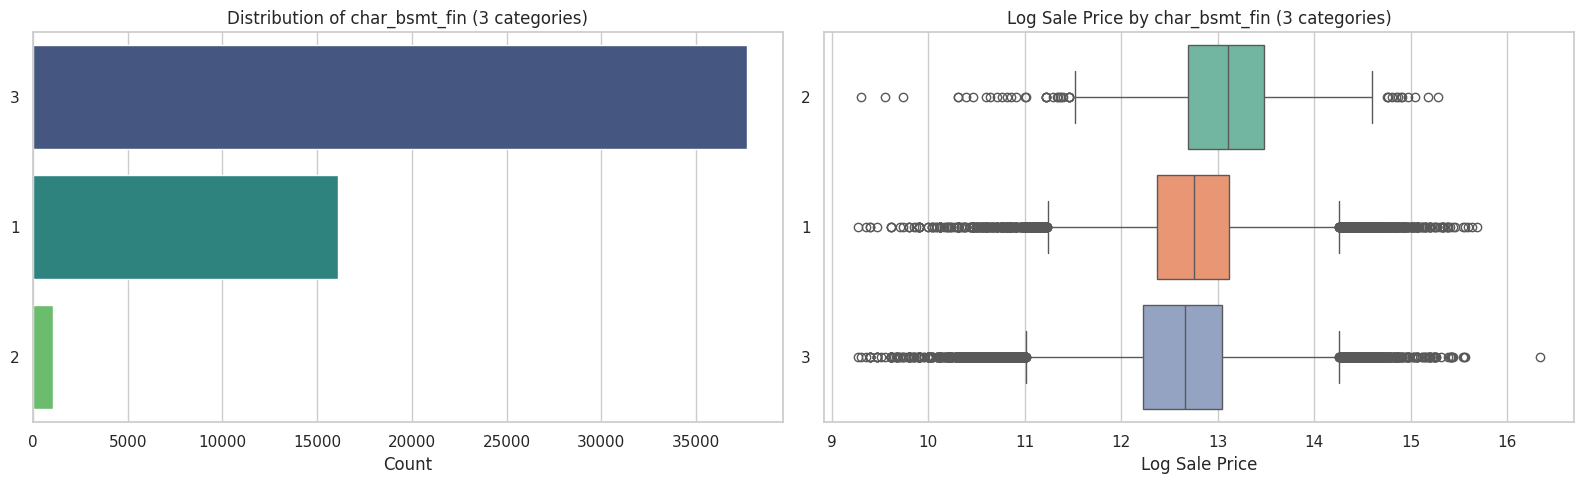

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


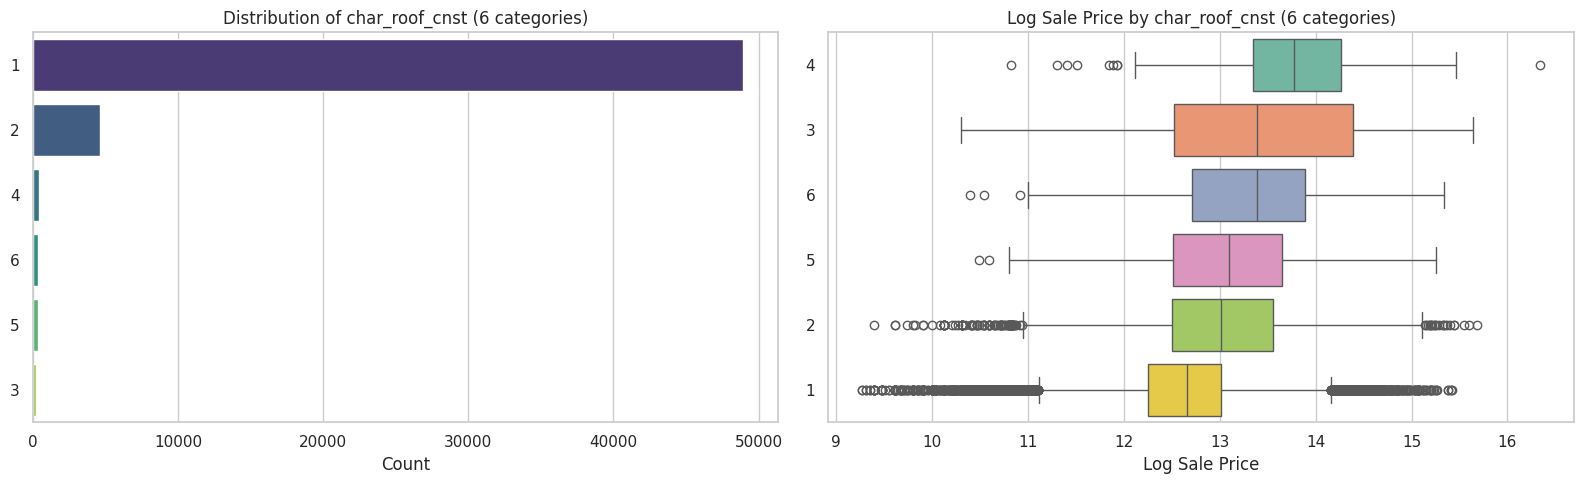

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


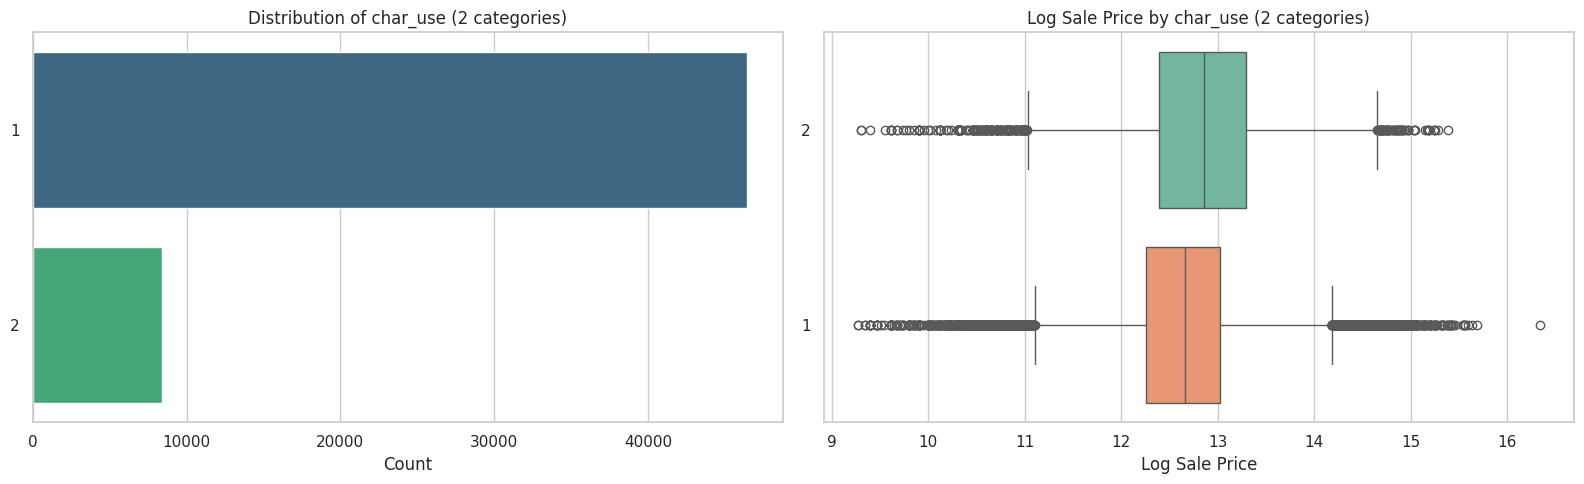

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


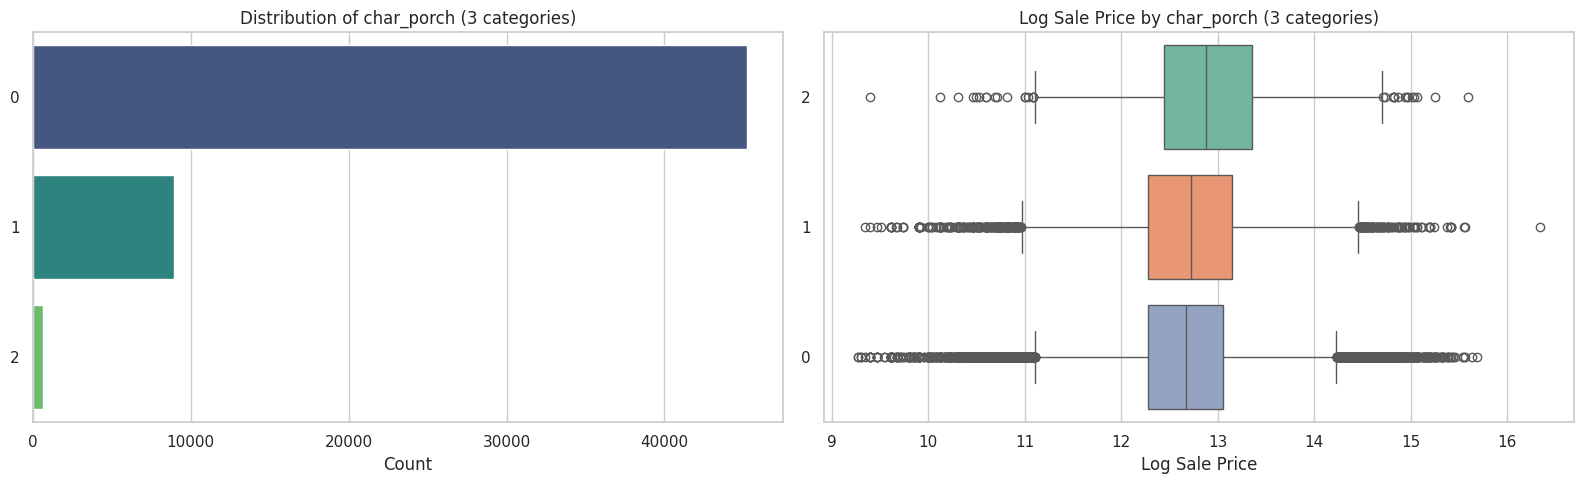

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


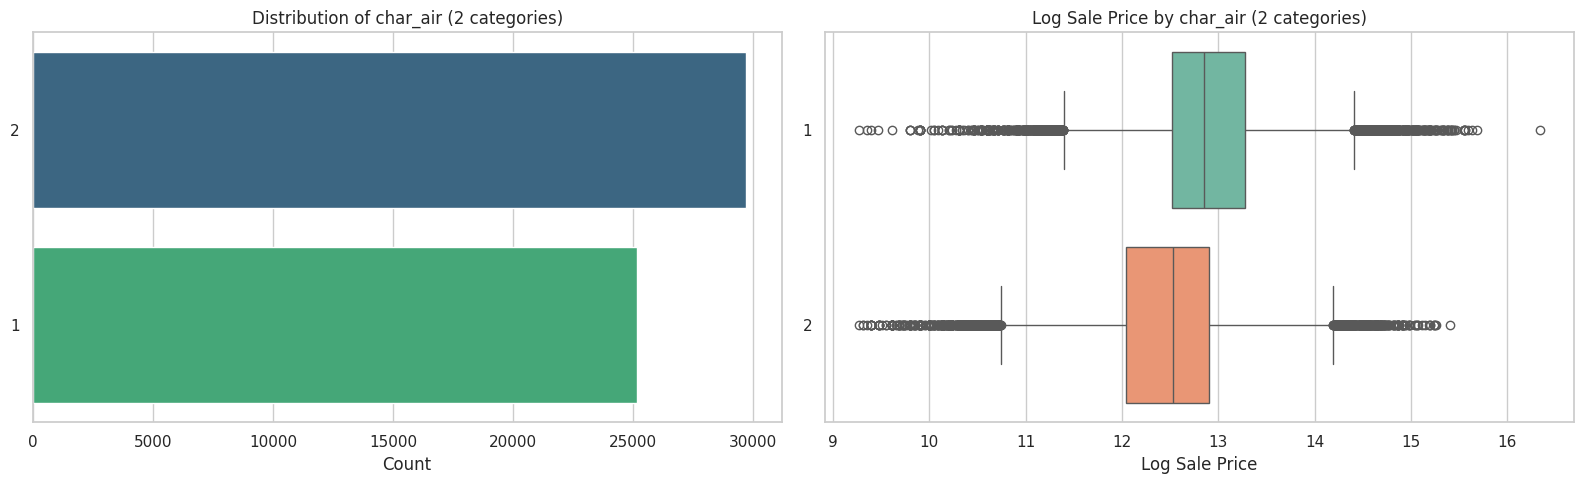

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


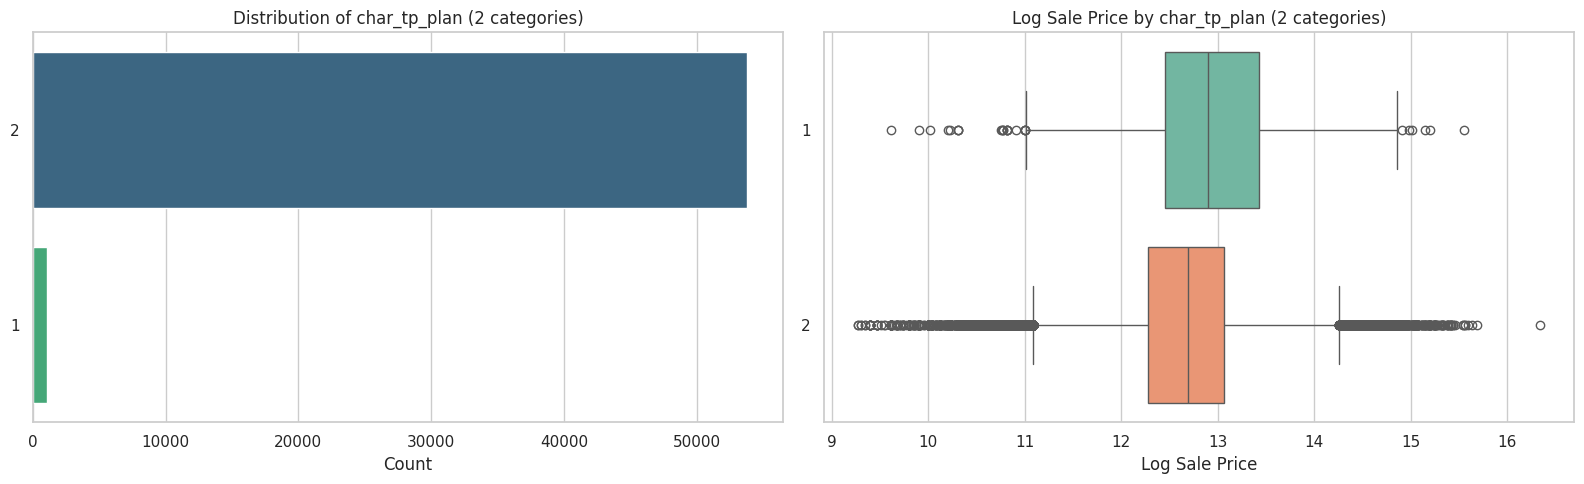

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


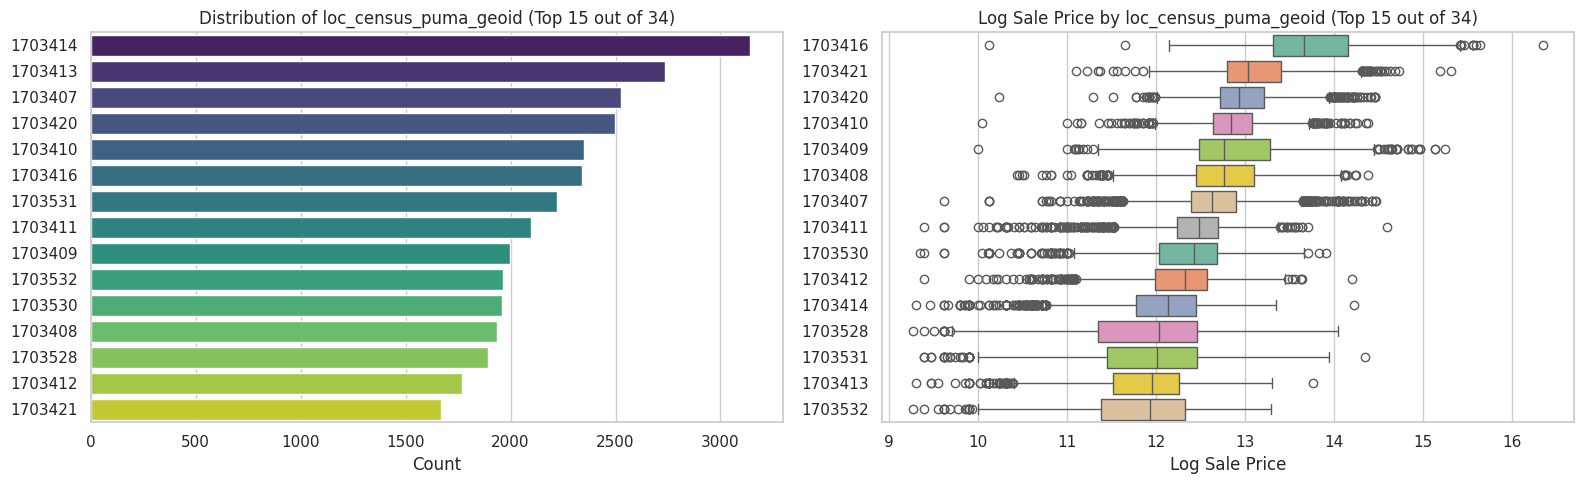

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


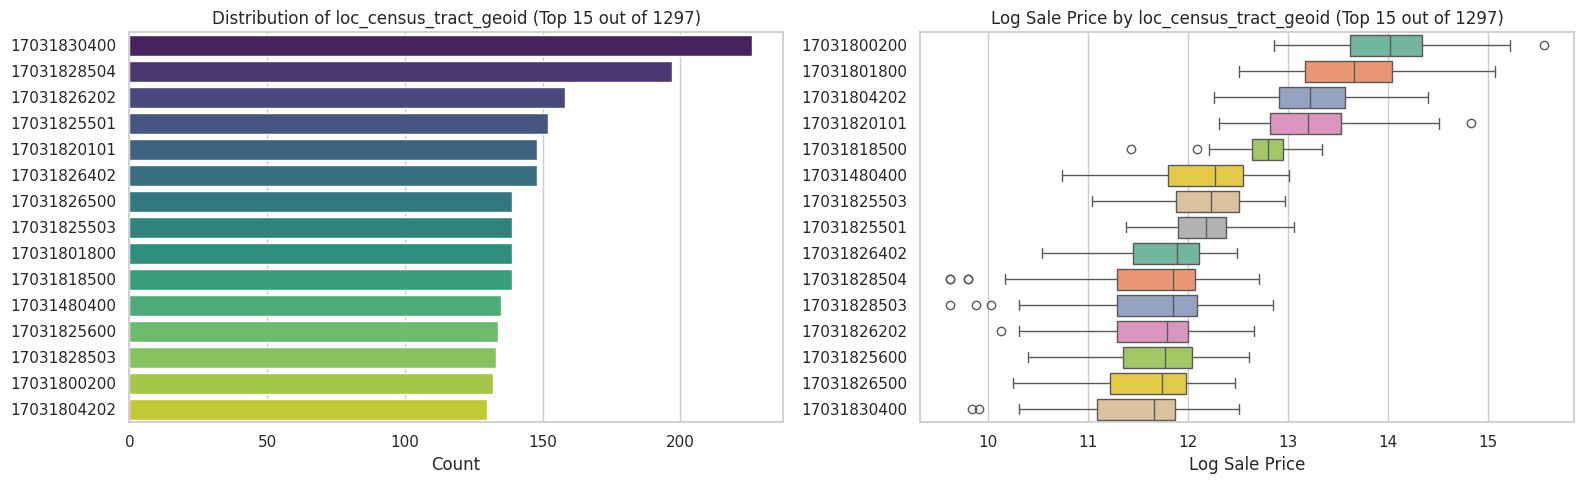

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


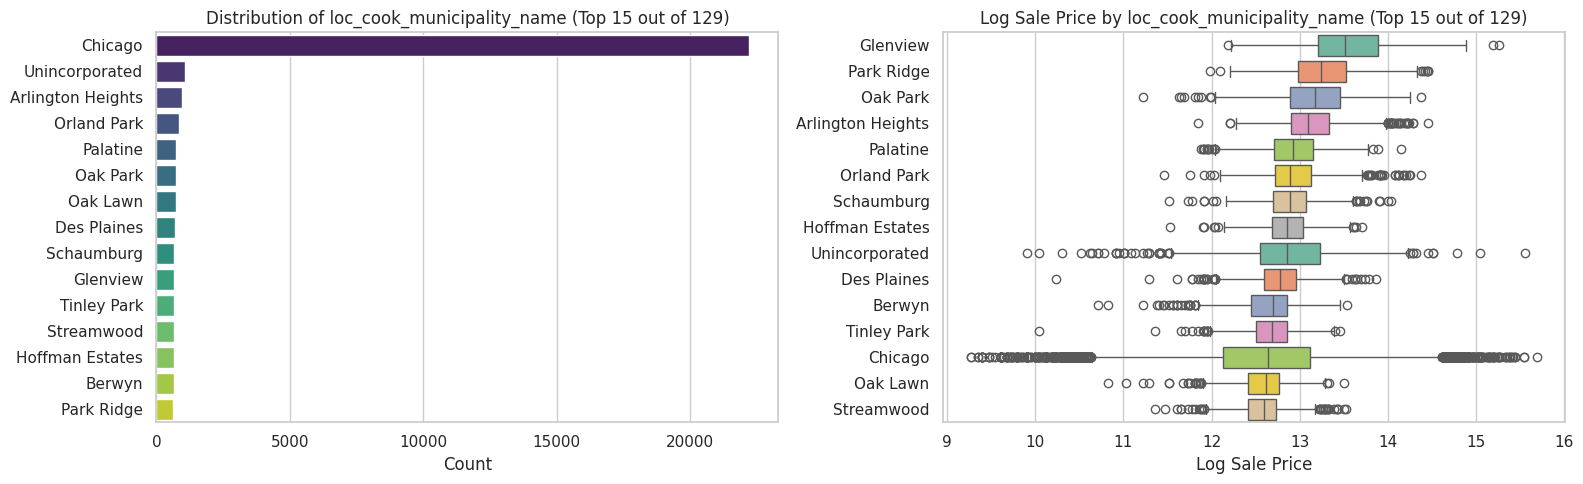

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


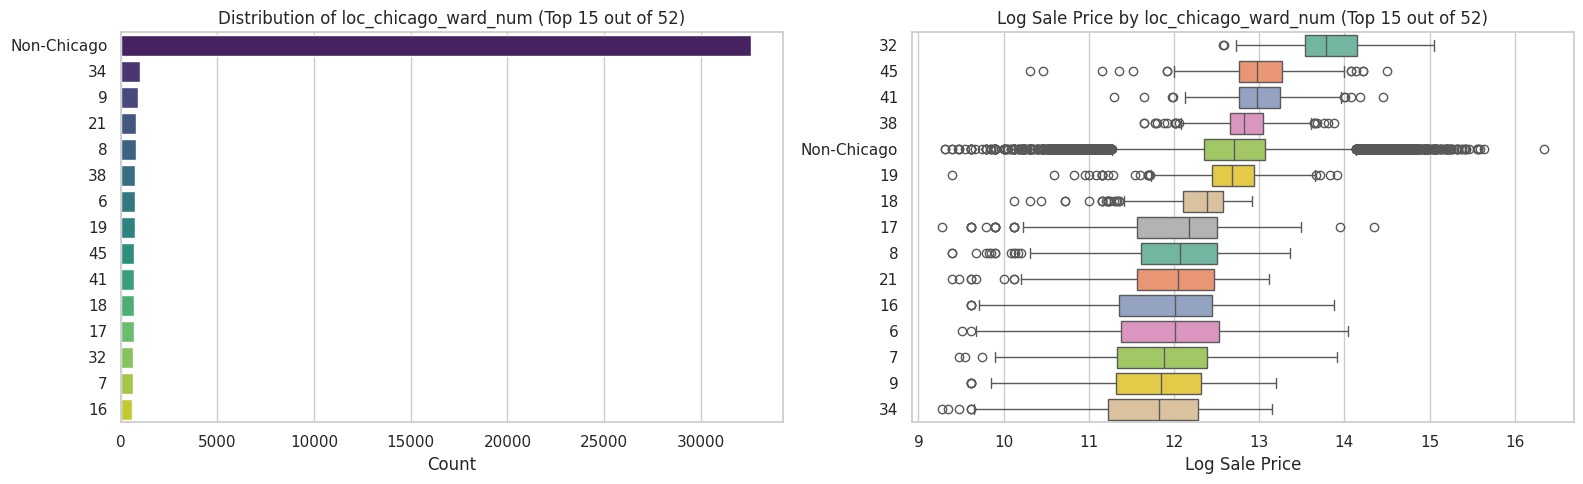

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


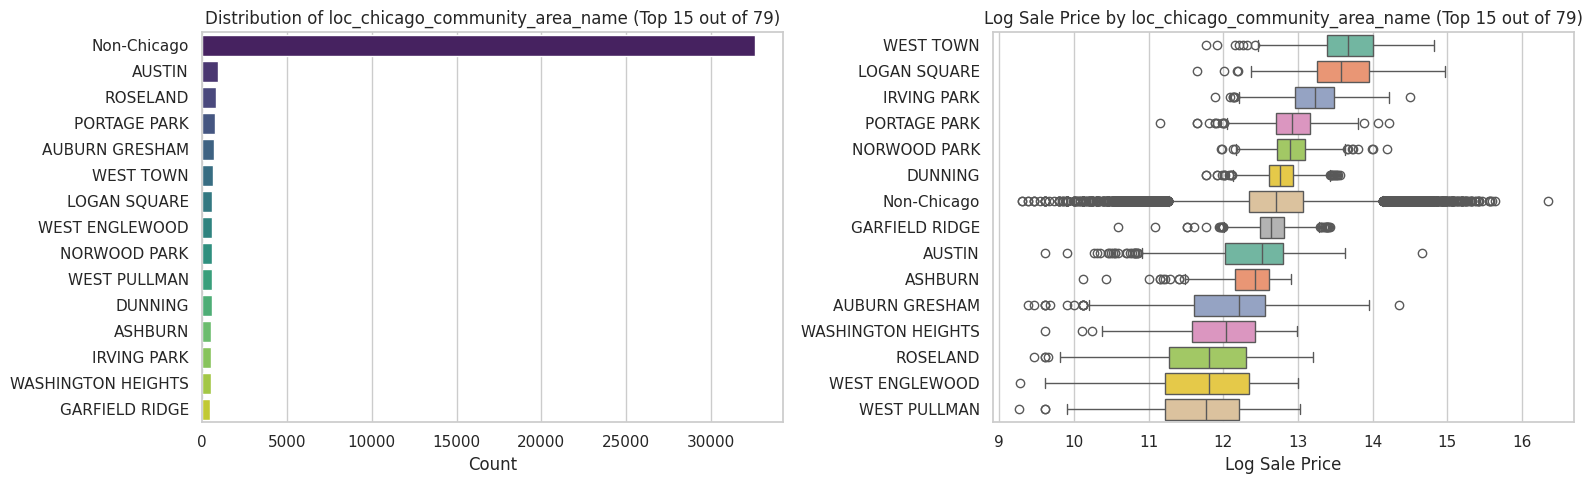

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


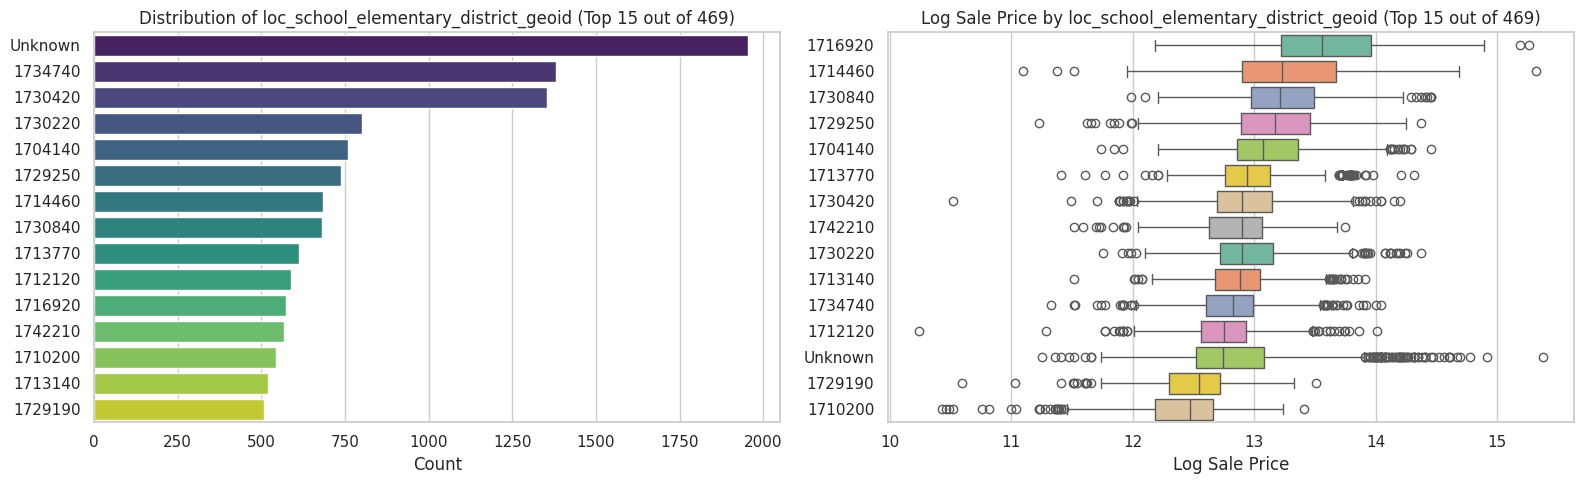

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


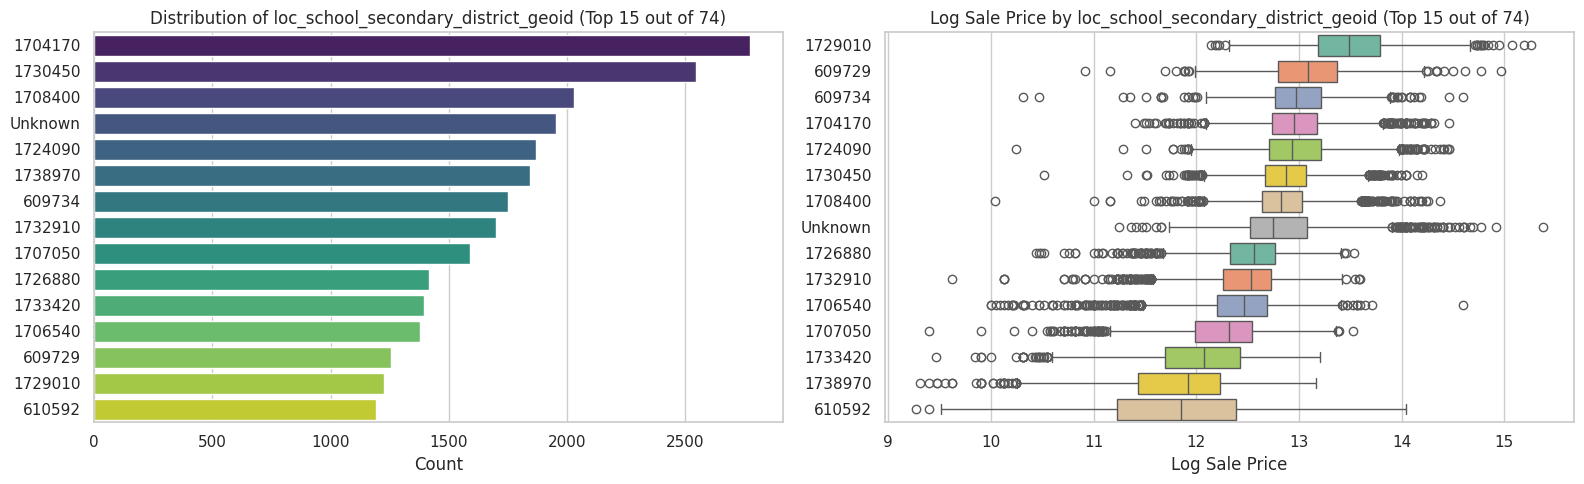

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


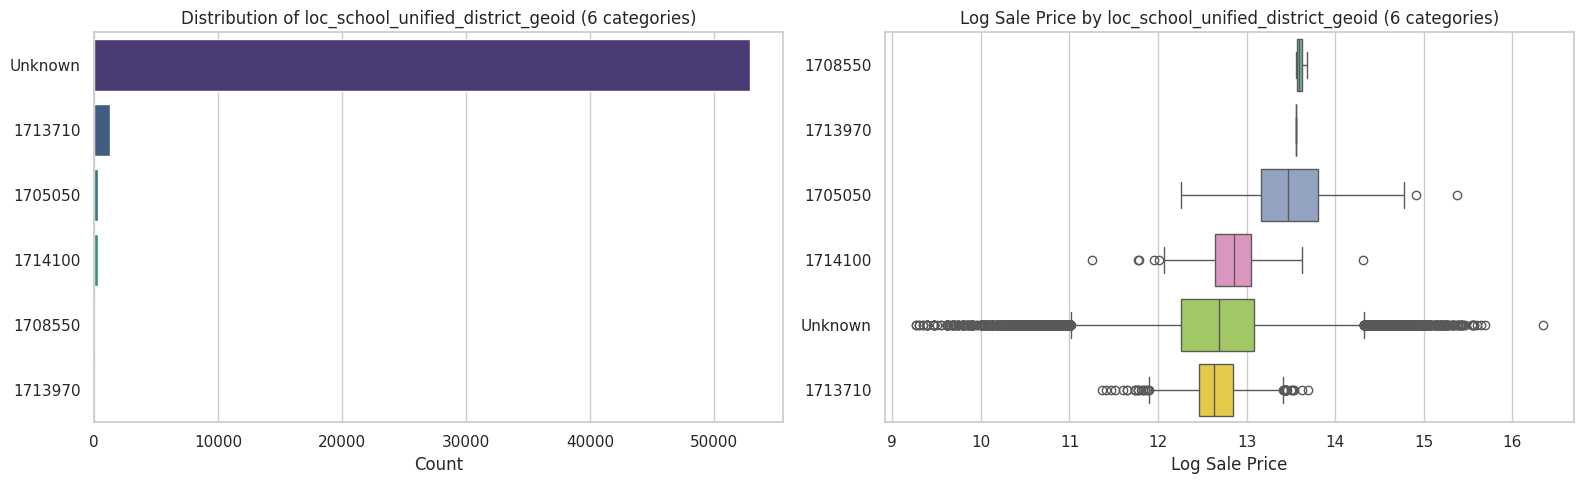

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


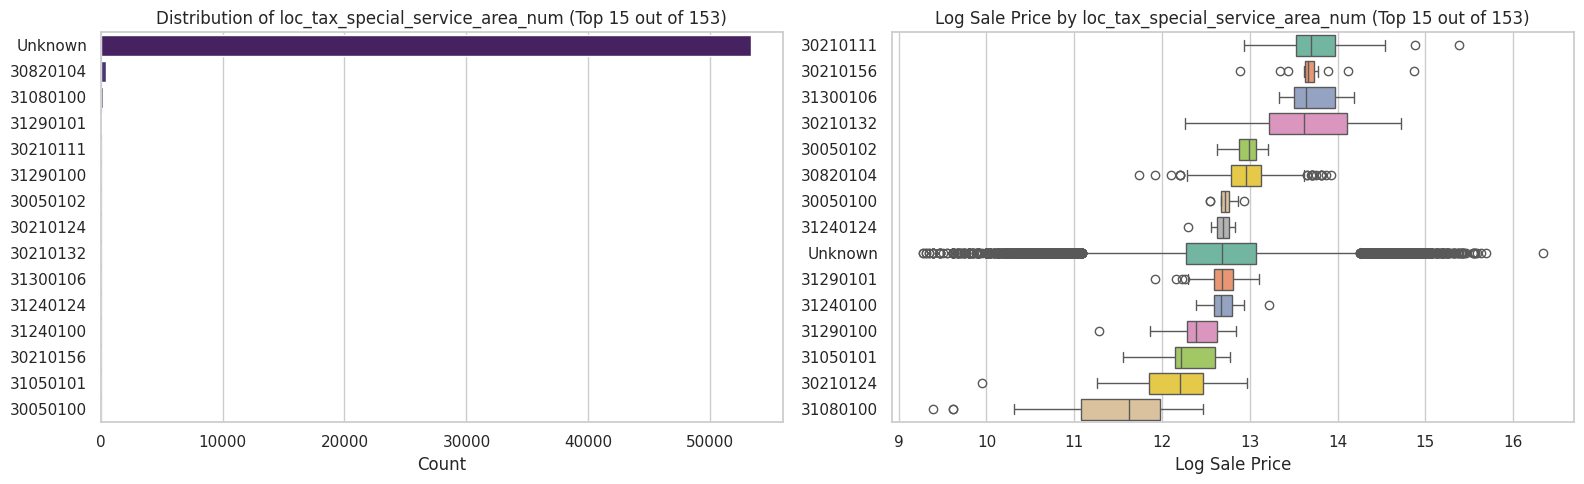

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


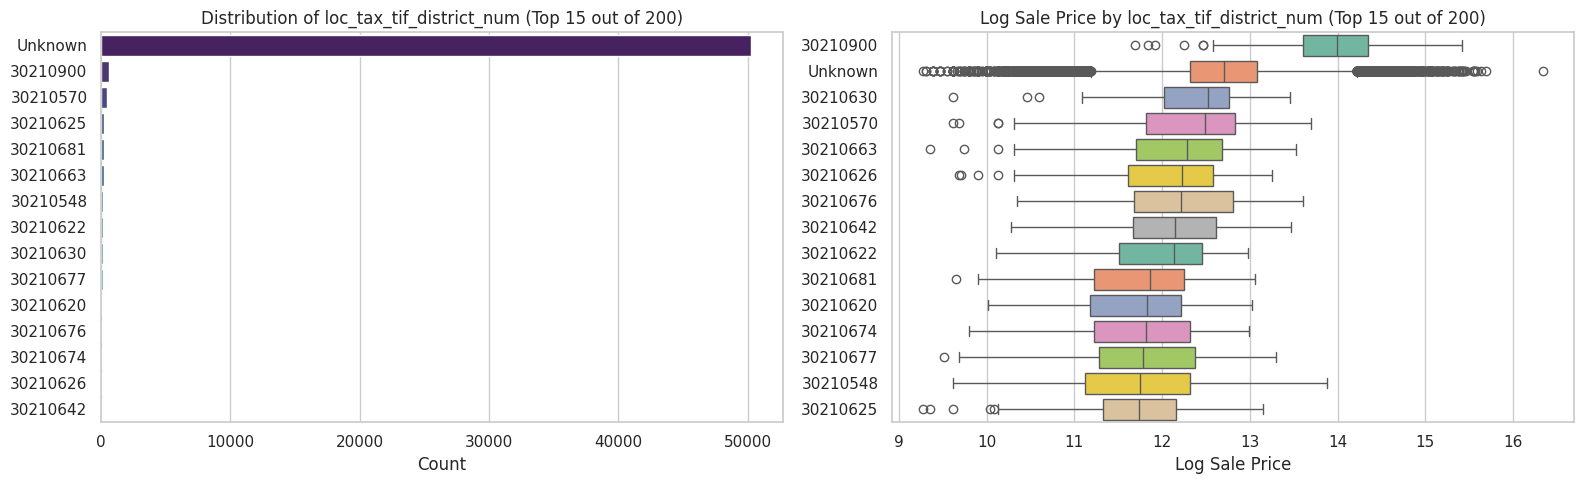

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


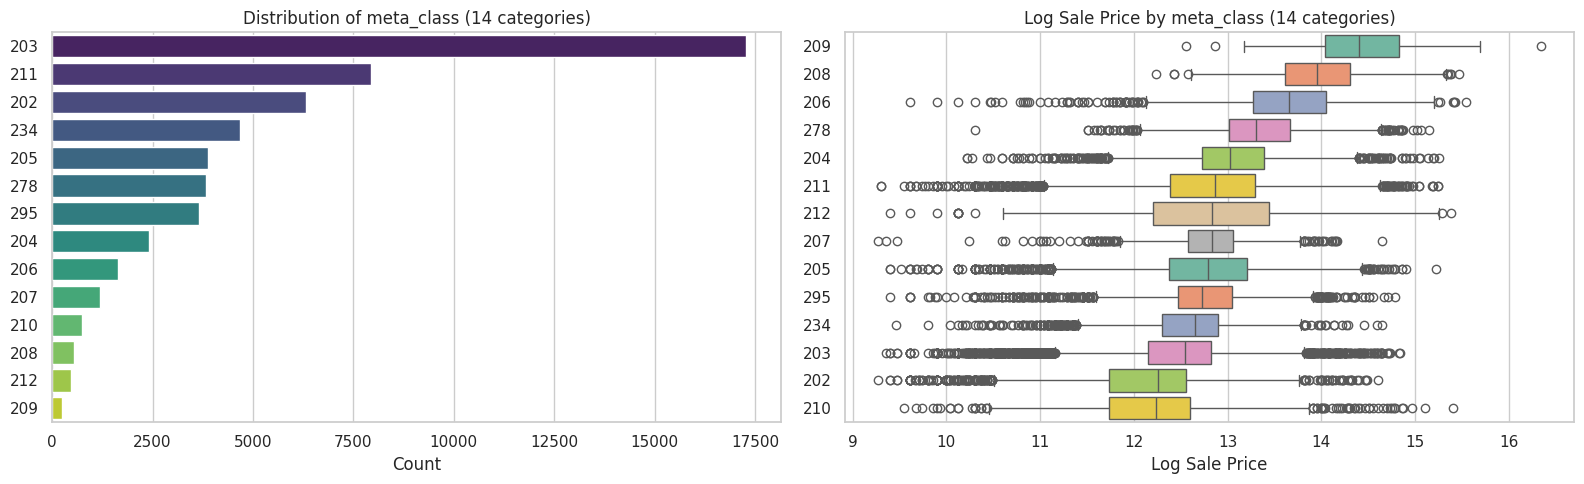

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


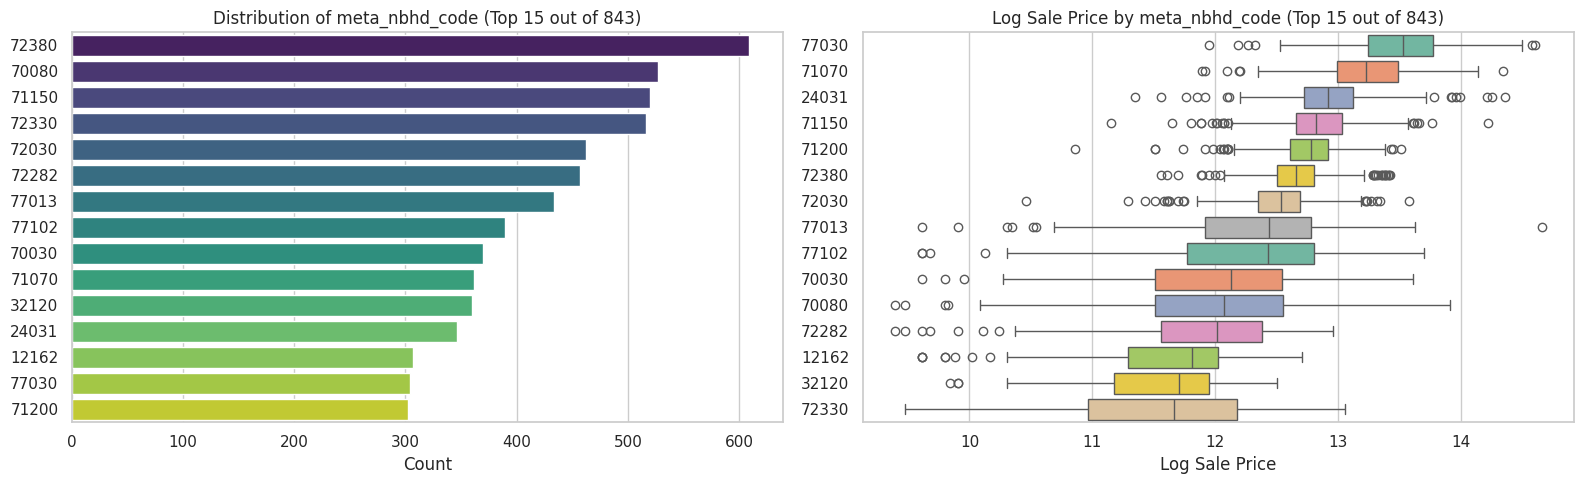

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


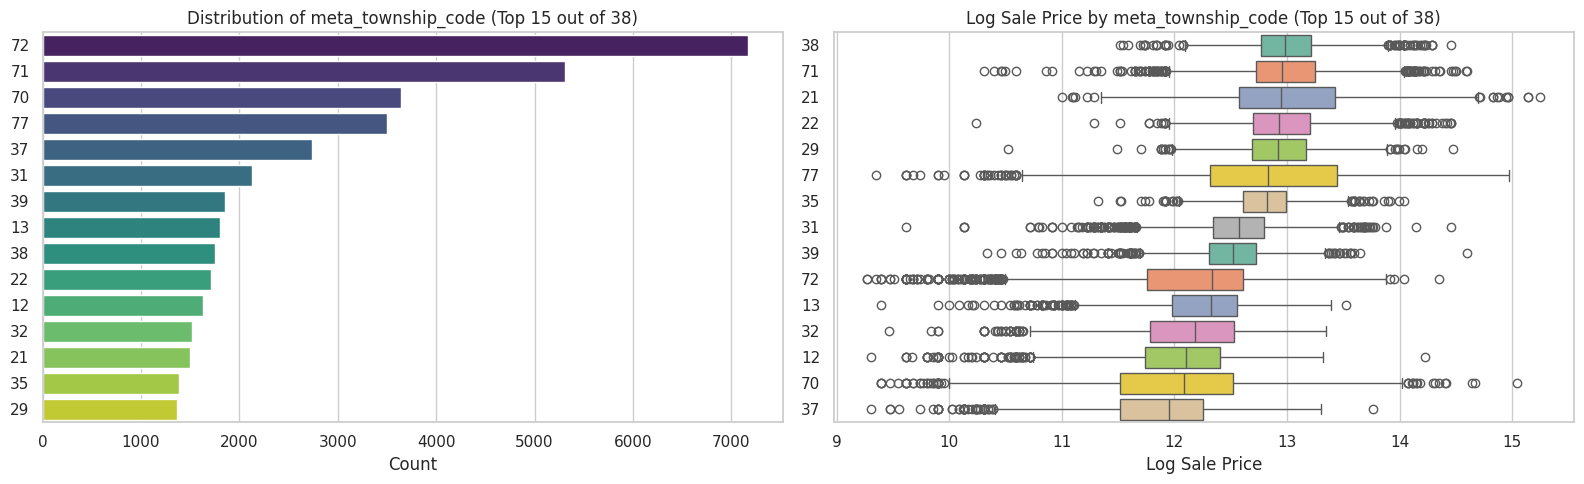

/tmp/ipykernel_30901/791713538.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
/tmp/ipykernel_30901/791713538.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")


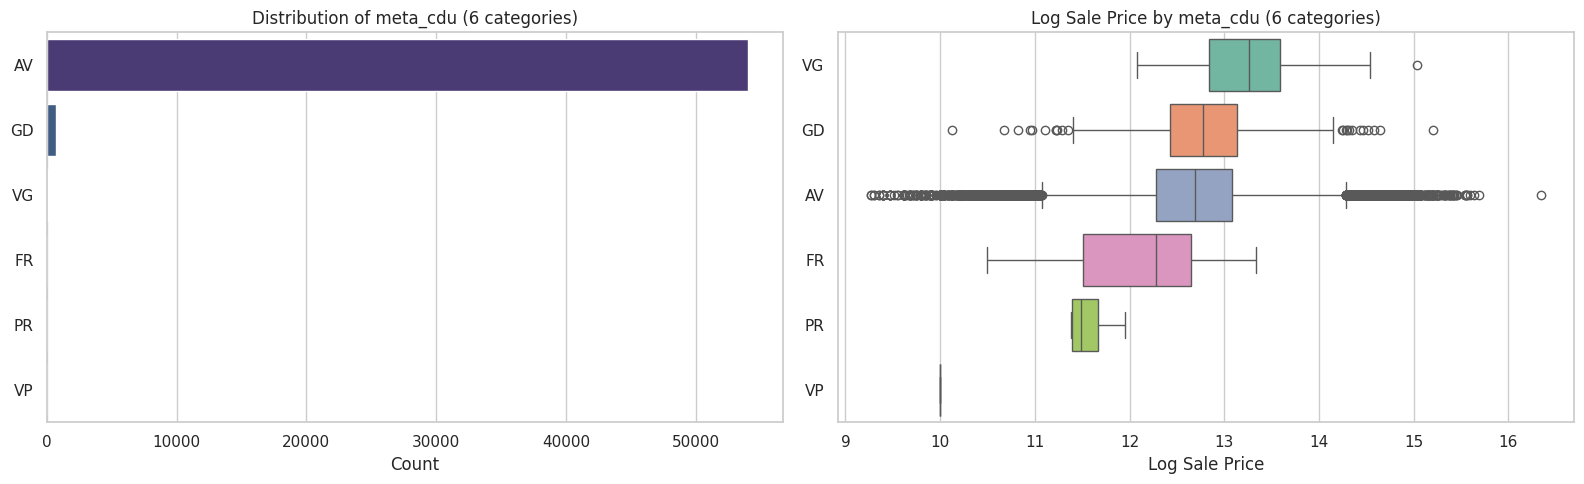


各特征类别对应的价格中位数 (按中位数降序):

--- loc_property_city (基数: 132) ---
                   count  median    mean
loc_property_city                       
KENILWORTH            68  14.263  14.262
WINNETKA             251  14.254  14.292
GLENCOE              176  14.119  14.140
BARRINGTON HILLS      35  13.816  13.871
GOLF                   4  13.799  13.808
HINSDALE              50  13.795  13.791
BURR RIDGE            52  13.781  13.776
SOUTH BARRINGTON      92  13.777  13.818
WILMETTE             511  13.728  13.778
NORTHFIELD           110  13.715  13.721

--- loc_property_zip (基数: 169) ---
                  count  median    mean
loc_property_zip                       
60606                 1  14.880  14.880
60611                20  14.436  14.411
60043                68  14.263  14.262
60093               361  14.152  14.118
60022               176  14.119  14.140
60614               440  14.093  14.102
60654                15  14.006  14.055
60657               324  13.911  13.927
60610     

In [55]:
# 1. 条形图与箱线图 (针对低基数与 Top N 类别)
# ==========================================
print("正在生成各特征的分布与价格关系图...")

for col in pkg_category:
    if col not in train_data.columns:
        continue

    # 计算类别基数
    n_unique = train_data[col].nunique()

    # 如果类别过多，只取频数最高的前 15 个类别画图
    if n_unique > 15:
        top_categories = train_data[col].value_counts().nlargest(15).index
        df_plot = train_data[train_data[col].isin(top_categories)]
        title_suffix = f" (Top 15 out of {n_unique})"
    else:
        df_plot = train_data
        title_suffix = f" ({n_unique} categories)"

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

    # 左图：Count Plot (类别分布)
    sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
    axes[0].set_title(f'Distribution of {col}{title_suffix}')
    axes[0].set_xlabel('Count')
    axes[0].set_ylabel('')

    # 右图：Box Plot (不同类别下的价格分布)
    # 确保类别按价格中位数排序，使图表更易读
    order = df_plot.groupby(col)['log_sale_price'].median().sort_values(ascending=False).index
    sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")
    axes[1].set_title(f'Log Sale Price by {col}{title_suffix}')
    axes[1].set_xlabel('Log Sale Price')
    axes[1].set_ylabel('')

    plt.tight_layout()
    plt.show()

# ==========================================
# 2. 统计表：类别对应的价格中位数
# ==========================================
print("\n各特征类别对应的价格中位数 (按中位数降序):")
for col in pkg_category:
    if col in train_data.columns:
        print(f"\n--- {col} (基数: {train_data[col].nunique()}) ---")
        target_summary = train_data.groupby(col)['log_sale_price'].agg(
            count='count',
            median='median',
            mean='mean'
        ).sort_values('median', ascending=False).round(3)
        print(target_summary.head(10)) # 只展示前 10 个

# ==========================================
# 3. 训练集与测试集的类别覆盖对齐情况
# ==========================================
print("\n训练集与测试集类别差异检查:")
for col in pkg_category:
    if col in train_data.columns and col in test_data.columns:
        train_cats = set(train_data[col].dropna().unique())
        test_cats = set(test_data[col].dropna().unique())

        unseen_in_test = test_cats - train_cats
        if len(unseen_in_test) > 0:
            print(f"⚠️ {col}: Test集有 {len(unseen_in_test)} 个新类别 (Train集未见): {list(unseen_in_test)[:5]} ...")
        else:
            print(f"✅ {col}: Test集类别完全被Train集覆盖。")

In [56]:
from sklearn.model_selection import KFold

# 假设 pkg_category 列表和 train_data, val_data, test_data 已经准备就绪
# 目标变量使用 'log_sale_price' (或者 'sale_price'，根据您的后续模型输入调整)
target_col = 'log_sale_price'

# ==========================================
# 辅助函数：带平滑与 K-Fold 的 Target Encoding
# ==========================================
def target_encode_with_smoothing(train_df, val_df, test_df, col, target_col, m=50, n_splits=5):
    global_mean = train_df[target_col].mean()

    # 1. 训练集使用 K-Fold 防止自身泄露
    train_encoded = np.zeros(len(train_df))
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    for tr_idx, va_idx in kf.split(train_df):
        X_tr, X_va = train_df.iloc[tr_idx], train_df.iloc[va_idx]
        agg = X_tr.groupby(col)[target_col].agg(['mean', 'count'])
        # 平滑公式：(count * category_mean + m * global_mean) / (count + m)
        smooth = (agg['count'] * agg['mean'] + m * global_mean) / (agg['count'] + m)
        train_encoded[va_idx] = X_va[col].map(smooth).fillna(global_mean).values

    # 2. 验证集和测试集使用全量训练集的统计量
    agg_full = train_df.groupby(col)[target_col].agg(['mean', 'count'])
    smooth_full = (agg_full['count'] * agg_full['mean'] + m * global_mean) / (agg_full['count'] + m)

    val_encoded = val_df[col].map(smooth_full).fillna(global_mean)
    test_encoded = test_df[col].map(smooth_full).fillna(global_mean)

    # 生成新列
    train_df[col + '_te'] = train_encoded
    val_df[col + '_te'] = val_encoded
    test_df[col + '_te'] = test_encoded

    # 删除原始高基数特征，防止维度爆炸和模型误判
    train_df.drop(columns=[col], inplace=True)
    val_df.drop(columns=[col], inplace=True)
    test_df.drop(columns=[col], inplace=True)

    print(f"  └─ 已执行 Target Encoding -> 生成 {col}_te")

# ==========================================
# 辅助函数：Rare Group + One-Hot Encoding
# ==========================================
def group_rare_and_onehot(train_df, val_df, test_df, col, threshold_pct=0.01):
    # 找出在训练集中占比小于阈值（默认1%）的稀有类别
    counts = train_df[col].value_counts(normalize=True)
    rare_cats = counts[counts < threshold_pct].index

    # 如果稀有类别过多（比如类别总数本来就少），就不合并了
    if len(rare_cats) == 0:
        print(f"  └─ 无需合并长尾，直接 One-Hot")
    else:
        print(f"  └─ 合并 {len(rare_cats)} 个稀有类别为 'Other'，然后 One-Hot")
        for df in [train_df, val_df, test_df]:
            df[col] = df[col].astype(str).apply(lambda x: 'Other' if x in map(str, rare_cats) else x)

    # 合并三个数据集进行统一 One-Hot，保证列对齐
    train_len = len(train_df)
    val_len = len(val_df)
    combined = pd.concat([train_df, val_df, test_df], axis=0, ignore_index=True)

    combined = pd.get_dummies(combined, columns=[col], drop_first=True)

    # 将 bool 型转为 int
    bool_cols = combined.select_dtypes(include=['bool']).columns
    combined[bool_cols] = combined[bool_cols].astype(int)

    # 拆分回原数据集
    train_df = combined.iloc[:train_len].copy()
    val_df = combined.iloc[train_len:train_len+val_len].copy()
    test_df = combined.iloc[train_len+val_len:].copy()

    return train_df, val_df, test_df

# ==========================================
# 主循环：遍历 pkg_category 执行分支逻辑
# ==========================================
print("\n开始处理 Category 特征...")

for col in pkg_category:
    if col not in train_data.columns:
        continue

    print(f"\n▶ 正在处理: {col}")

    # 确保数据为字符串格式
    for df in [train_data, val_data, test_data]:
        df[col] = df[col].astype(str)

    n_unique = train_data[col].nunique()
    print(f"  └─ Train nunique: {n_unique}")

    # ------------------------------------------
    # 规则 1：nunique >= 30，使用 Target Encode
    # ------------------------------------------
    if n_unique >= 30:
        target_encode_with_smoothing(train_data, val_data, test_data, col, target_col, m=50)

    # ------------------------------------------
    # 规则 2：10 <= nunique < 30，Rare Group + One-Hot
    # ------------------------------------------
    elif 10 <= n_unique < 30:
        # 合并占比 < 5% 的类别
        train_data, val_data, test_data = group_rare_and_onehot(
            train_data, val_data, test_data, col, threshold_pct=0.05
        )

    # ------------------------------------------
    # 规则 3：nunique < 10，判断头部占比决定是否 Rare Group，统用 One-Hot
    # ------------------------------------------
    else:
        # 统计训练集中各类别占比
        value_pcts = train_data[col].value_counts(normalize=True)
        # 计算前 1-2 个类别的累计占比
        top2_pct = value_pcts.head(2).sum()

        # 设定一个阈值（例如 Top2 占比超过 95% 视为极度倾斜）
        if top2_pct > 0.95:
            print(f"  └─ Top1/2 类别占比极高 ({top2_pct:.2%})，将执行 Rare Group 以防过拟合")
            # 依然合并占比极低的类别（这里放宽一点，比如 < 2%，或者根据实际需求设定）
            train_data, val_data, test_data = group_rare_and_onehot(
                train_data, val_data, test_data, col, threshold_pct=0.02
            )
        else:
            print(f"  └─ Top1/2 类别占比正常 ({top2_pct:.2%})，直接 One-Hot")
            train_data, val_data, test_data = group_rare_and_onehot(
                train_data, val_data, test_data, col, threshold_pct=0.0 # 0.0 意味着不合并任何类别
            )

print("\n✅ 所有 Category 特征处理完毕！")
print(f"最终数据维度: Train={train_data.shape}, Val={val_data.shape}, Test={test_data.shape}")


开始处理 Category 特征...

▶ 正在处理: loc_property_city
  └─ Train nunique: 132
  └─ 已执行 Target Encoding -> 生成 loc_property_city_te

▶ 正在处理: loc_property_zip
  └─ Train nunique: 169
  └─ 已执行 Target Encoding -> 生成 loc_property_zip_te

▶ 正在处理: char_type_resd
  └─ Train nunique: 6
  └─ Top1/2 类别占比正常 (77.65%)，直接 One-Hot
  └─ 无需合并长尾，直接 One-Hot

▶ 正在处理: char_cnst_qlty
  └─ Train nunique: 3
  └─ Top1/2 类别占比极高 (99.92%)，将执行 Rare Group 以防过拟合
  └─ 合并 2 个稀有类别为 'Other'，然后 One-Hot

▶ 正在处理: char_apts
  └─ Train nunique: 6
  └─ Top1/2 类别占比正常 (94.42%)，直接 One-Hot
  └─ 无需合并长尾，直接 One-Hot

▶ 正在处理: char_attic_fnsh
  └─ Train nunique: 3
  └─ Top1/2 类别占比极高 (99.34%)，将执行 Rare Group 以防过拟合
  └─ 合并 1 个稀有类别为 'Other'，然后 One-Hot

▶ 正在处理: char_gar1_size
  └─ Train nunique: 8
  └─ Top1/2 类别占比正常 (71.20%)，直接 One-Hot
  └─ 无需合并长尾，直接 One-Hot

▶ 正在处理: char_gar1_cnst
  └─ Train nunique: 4
  └─ Top1/2 类别占比正常 (94.60%)，直接 One-Hot
  └─ 无需合并长尾，直接 One-Hot

▶ 正在处理: char_attic_type
  └─ Train nunique: 3
  └─ Top1/2 类别占比正常 (86.58%)，直接 One-Hot

In [60]:
cols_train = set(train_data.columns)
cols_val = set(val_data.columns)
cols_test = set(test_data.columns)

if cols_train == cols_val == cols_test:
    print("✅ 列名与特征数量完全一致。")
else:
    print("⚠️ 列名不一致！")
    print("Train独有:", cols_train - cols_val)
    print("Val独有:", cols_val - cols_train)

for name, df in zip(['Train', 'Val', 'Test'], [train_data, val_data, test_data]):
    assert df['log_sale_price'].isnull().sum() == 0, f"{name} 目标变量存在缺失！"
    assert not np.isinf(df['log_sale_price']).any(), f"{name} 目标变量存在无穷大！"
    print(f"✅ {name} 目标变量无缺失、无异常值。")

# 检查所有特征列是否包含 inf 或 NaN
for name, df in zip(['Train', 'Val', 'Test'], [train_data, val_data, test_data]):
    # 排除目标列
    features = df.drop(columns=['log_sale_price', 'sale_price'], errors='ignore')

    # 检查无限大
    inf_count = np.isinf(features.select_dtypes(include=[np.number])).sum().sum()
    if inf_count > 0:
        print(f"⚠️ {name} 集存在 {inf_count} 个无穷大 (inf) 值！")

    # 检查剩余 NaN
    nan_cols = features.columns[features.isnull().any()].tolist()
    if len(nan_cols) > 0:
        print(f"⚠️ {name} 集存在缺失值的列: {nan_cols}")
    else:
        print(f"✅ {name} 集所有特征值干净（无 NaN，无 inf）。")

obj_cols = train_data.select_dtypes(include=['object']).columns.tolist()
if obj_cols:
    print(f"⚠️ 发现 object 类型列（会导致模型训练报错）: {obj_cols}")
    # 视情况转为 category 或 drop
else:
    print("✅ 无残留的 object 列。")

✅ 列名与特征数量完全一致。
✅ Train 目标变量无缺失、无异常值。
✅ Val 目标变量无缺失、无异常值。
✅ Test 目标变量无缺失、无异常值。
✅ Train 集所有特征值干净（无 NaN，无 inf）。
✅ Val 集所有特征值干净（无 NaN，无 inf）。
✅ Test 集所有特征值干净（无 NaN，无 inf）。
✅ 无残留的 object 列。


保存数据

In [61]:
train_data.to_parquet('train_processed.parquet')
val_data.to_parquet('val_processed.parquet')
test_data.to_parquet('test_processed.parquet')